# SIRCON 2026 poster: microRNA–messenger RNA regulatory network in inflammation-associated colorectal cancer

**Pipeline:** GEO download → QC → differential expression → miRTarBase targets → inverse-expression filter → network + hubs → enrichment (with inflammation filter) → STRING PPI → independent validation (ROC) → drug–gene hits → poster figures.

Run cells top to bottom. **Cell 3 (config) and the group-assignment cells need your eyes**: check the printed sample labels before trusting the results.

## 1. Setup

In [ ]:
!pip -q install GEOparse gseapy statsmodels networkx openpyxl

import os, re, warnings, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
import GEOparse, gseapy as gp
from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.metrics import roc_curve, roc_auc_score

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True); os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 300, "figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
RED, BLUE, GREY = "#d62728", "#1f77b4", "#c7c7c7"

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 4.4 MB/s eta 0:00:00


## 2. Configuration (edit this)

In [ ]:
# --- Datasets: VERIFY each accession on the GEO website (tissue, tumour vs normal, sample numbers) ---
MRNA_GSE  = "GSE44076"   # candidate: paired colon tumour / adjacent / healthy mucosa (verify)
MIRNA_GSE = "GSE35834"   # miRNA array: normal mucosa, primary tumour, liver metastasis (metastasis is excluded below)
VALID_GSE = "GSE9348"    # candidate independent mRNA cohort for validation (verify); set None to skip

# Optional: force a platform if a series has several (e.g. "GPL570"); None = first platform
MRNA_PLATFORM = None; MIRNA_PLATFORM = None; VALID_PLATFORM = None

# --- Keywords used to label samples (matched against title + characteristics, lower-case) ---
TUMOR_KW  = ["tumor", "tumour", "cancer", "carcinoma", "primary"]
NORMAL_KW = ["normal", "healthy", "mucosa", "adjacent", "control"]   # normal wins if both appear
EXCLUDE_KW = ["metast", "liver", "adenoma", "cell line"]

# --- Thresholds ---
GENE_LFC, GENE_PADJ = 1.0, 0.05
MIR_LFC,  MIR_PADJ  = 0.58, 0.05     # looser for miRNAs (state this on the poster)
STRONG_MTI_ONLY = True               # miRTarBase "Functional MTI" (drop "Weak")
STRING_SCORE = 700
N_HUB_MIR, N_HUB_GENE = 10, 15

## 3. Helper functions

In [ ]:
def load_gse(acc, platform=None):
    gse = GEOparse.get_GEO(geo=acc, destdir="data", silent=True)
    plats = list(gse.gpls); platform = platform or plats[0]
    gsms = {k: v for k, v in gse.gsms.items() if v.metadata["platform_id"][0] == platform}
    expr = pd.concat({k: v.table.set_index("ID_REF")["VALUE"] for k, v in gsms.items()}, axis=1)
    expr = expr.apply(pd.to_numeric, errors="coerce")
    meta = pd.DataFrame({k: {"text": " | ".join(v.metadata.get("title", []) + v.metadata.get("source_name_ch1", []) + v.metadata.get("characteristics_ch1", []))}
                         for k, v in gsms.items()}).T
    print(f"{acc}: platforms={plats}, using {platform}, probes={expr.shape[0]}, samples={expr.shape[1]}")
    return gse.gpls[platform].table, expr, meta

def assign_groups(meta):
    t = meta["text"].str.lower()
    g = pd.Series("other", index=meta.index)
    g[t.apply(lambda s: any(k in s for k in TUMOR_KW))] = "Tumor"
    g[t.apply(lambda s: any(k in s for k in NORMAL_KW))] = "Normal"
    g[t.apply(lambda s: any(k in s for k in EXCLUDE_KW))] = "other"
    print(g.value_counts().to_string())
    print("\nExample labels per group (CHECK THESE):")
    for grp in ["Tumor", "Normal", "other"]:
        print(f"[{grp}]", meta.loc[g == grp, "text"].head(3).tolist())
    return g

def ensure_log2(expr):
    if np.nanmax(expr.values) > 100:
        print("Values look un-logged -> applying log2(x+1)")
        return np.log2(expr.clip(lower=0) + 1)
    return expr

def collapse(expr, gpl, mirna=False):
    gpl = gpl.copy()
    if mirna:   # column with the most 'hsa-' entries holds miRNA names
        col = max(gpl.columns, key=lambda c: gpl[c].astype(str).str.startswith("hsa-").sum())
    else:
        cands = [c for c in gpl.columns if re.search(r"gene.?symbol|^symbol$", c, re.I)]
        col = cands[0]
    print("Annotation column used:", col)

    gpl_indexed = gpl.set_index("ID")
    if mirna and col == "ID":
        m = gpl_indexed.index.to_series().astype(str)
    else:
        m = gpl_indexed[col].astype(str)

    m = m.str.split(r"\s*///\s*").str[0].str.strip()
    if mirna:
        m = m.str.replace(r"(_x)?(_s)?_st$", "", regex=True)
        m = m[m.str.match(r"^hsa-(miR|let)")]          # mature human miRNAs only
    df = expr.loc[expr.index.intersection(m.index)].copy()
    df["sym"] = df.index.map(m)
    df = df[df["sym"].notna() & ~df["sym"].isin(["nan", "", "---"])]
    df["mu"] = df.drop(columns="sym").mean(axis=1)
    df = df.sort_values("mu", ascending=False).drop_duplicates("sym").drop(columns="mu").set_index("sym")
    return df

def diff_expr(expr, groups, case="Tumor", ctrl="Normal"):
    a, b = expr.loc[:, groups == case], expr.loc[:, groups == ctrl]
    t, p = stats.ttest_ind(a, b, axis=1, equal_var=False, nan_policy="omit")
    res = pd.DataFrame({"log2FC": a.mean(1) - b.mean(1), "pval": p, "mean_expr": expr.mean(1)})
    res["padj"] = multipletests(res["pval"].fillna(1), method="fdr_bh")[1]
    return res.sort_values("padj")

def volcano(res, lfc_t, padj_t, title, fname, n_label=10):
    d = res.copy(); d["nlp"] = -np.log10(d["padj"].clip(lower=1e-300))
    sig = (d.padj < padj_t) & (d.log2FC.abs() > lfc_t)
    col = np.where(sig & (d.log2FC > 0), RED, np.where(sig & (d.log2FC < 0), BLUE, GREY))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.scatter(d.log2FC, d.nlp, c=col, s=8, alpha=.8)
    ax.axvline(lfc_t, ls="--", c="k", lw=.6); ax.axvline(-lfc_t, ls="--", c="k", lw=.6); ax.axhline(-np.log10(padj_t), ls="--", c="k", lw=.6)
    for g in d[sig].sort_values("padj").head(n_label).index:
        ax.annotate(g, (d.log2FC[g], d.nlp[g]), fontsize=7)
    ax.set(xlabel="log2 fold change (Tumor vs Normal)", ylabel="-log10 adjusted p", title=f"{title}\nUp: {(sig & (d.log2FC>0)).sum()} | Down: {(sig & (d.log2FC<0)).sum()}")
    savefig(fname)

def pca_plot(expr, groups, title, fname):
    keep = groups.isin(["Tumor", "Normal"]); X = expr.loc[:, keep].dropna().T
    pcs = PCA(2).fit(X); Z = pcs.transform(X)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    for grp, c in [("Tumor", RED), ("Normal", BLUE)]:
        m = (groups[keep] == grp).values; ax.scatter(Z[m, 0], Z[m, 1], c=c, label=grp, s=18)
    ax.set(xlabel=f"PC1 ({pcs.explained_variance_ratio_[0]*100:.0f}%)", ylabel=f"PC2 ({pcs.explained_variance_ratio_[1]*100:.0f}%)", title=title); ax.legend()
    savefig(fname)

def heatmap(expr, groups, res, n, title, fname):
    top = res.head(n).index; keep = groups.isin(["Tumor", "Normal"])
    Z = expr.loc[top, keep]; Z = Z.sub(Z.mean(1), axis=0).div(Z.std(1), axis=0)
    colors = groups[keep].map({"Tumor": RED, "Normal": BLUE})
    cg = sns.clustermap(Z, col_colors=colors, cmap="vlag", center=0, figsize=(7, 7), xticklabels=False, yticklabels=True)
    cg.fig.suptitle(title, y=1.02); cg.savefig(f"figures/{fname}.png", bbox_inches="tight"); plt.show()

## 4. mRNA discovery dataset

In [ ]:
gpl_m, expr_m, meta_m = load_gse(MRNA_GSE, MRNA_PLATFORM)
grp_m = assign_groups(meta_m)

GSE44076: platforms=['GPL13667'], using GPL13667, probes=49386, samples=246
Normal    148
Tumor      98

Example labels per group (CHECK THESE):
[Tumor] ['Tumor sample from A2004 patient | Primary colon adenocarcinoma cells | sample type: Tumor | individual id: A2004 | Stage: IIA | location: Left | gender: Male | age: 66', 'Tumor sample from A2027 patient | Primary colon adenocarcinoma cells | sample type: Tumor | individual id: A2027 | Stage: IIA | location: Left | gender: Female | age: 51', 'Tumor sample from A2050 patient | Primary colon adenocarcinoma cells | sample type: Tumor | individual id: A2050 | Stage: IIA | location: Left | gender: Male | age: 60']
[Normal] ['Mucosa sample from A2119 healthy donnor | Healthy colon mucosa cells | sample type: Mucosa | individual id: A2119 | Stage: -- | location: Left | gender: Male | age: 62', 'Mucosa sample from A2142 healthy donnor | Healthy colon mucosa cells | sample type: Mucosa | individual id: A2142 | Stage: -- | location: Left | gend

Annotation column used: Gene Symbol
Genes: (19468, 246)


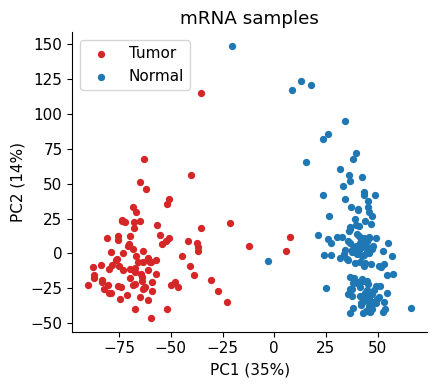

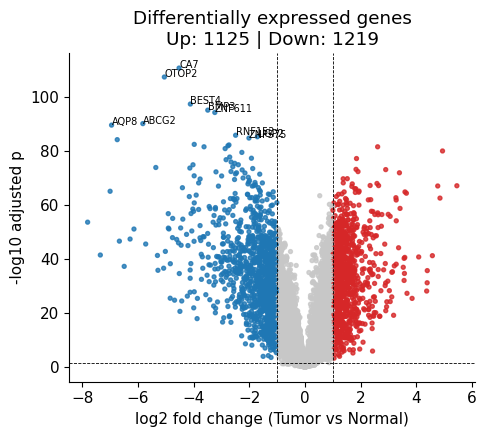

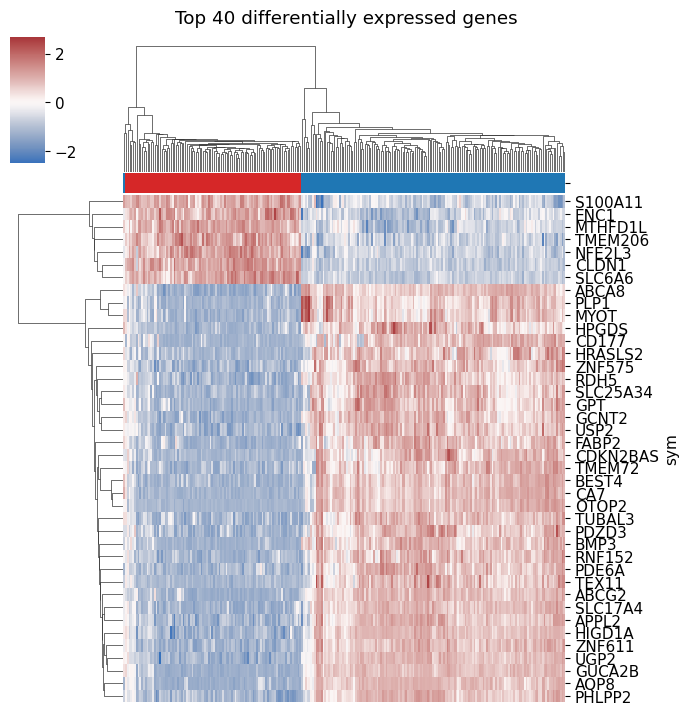

Significant genes: 2344


In [ ]:
# If the labels above look wrong, override manually, e.g.:
# grp_m = meta_m["text"].apply(lambda s: "Tumor" if "your tumour text" in s.lower() else ("Normal" if "your normal text" in s.lower() else "other"))
expr_m = ensure_log2(expr_m)
gene_expr = collapse(expr_m, gpl_m)
print("Genes:", gene_expr.shape)
pca_plot(gene_expr, grp_m, "mRNA samples", "Fig1a_PCA_mRNA")
gene_res = diff_expr(gene_expr, grp_m)
volcano(gene_res, GENE_LFC, GENE_PADJ, "Differentially expressed genes", "Fig1b_volcano_mRNA")
heatmap(gene_expr, grp_m, gene_res, 40, "Top 40 differentially expressed genes", "Fig1c_heatmap_mRNA")
gene_res.to_csv("tables/DEG_results.csv")
de_gene = gene_res[(gene_res.padj < GENE_PADJ) & (gene_res.log2FC.abs() > GENE_LFC)]
print("Significant genes:", len(de_gene))

## 5. miRNA discovery dataset

In [ ]:
gpl_r, expr_r, meta_r = load_gse(MIRNA_GSE, MIRNA_PLATFORM)
grp_r = assign_groups(meta_r)

GSE35834: platforms=['GPL8786', 'GPL15236'], using GPL8786, probes=7815, samples=78
Tumor     31
other     24
Normal    23

Example labels per group (CHECK THESE):
[Tumor] ['mirna-9821t | colon cancer, colon ascending | gender: M | patient_id: 9821 | site: colon ascending | age: 63 | grading: G3 | tnm: 4 | ln_positive: 1 | ln_examined: 27 | mts_type: synchronous', 'mirna-5525t | colon cancer, rectum | gender: M | patient_id: 5525 | site: rectum | age: 70 | grading: G2 | tnm: 4 | ln_positive: 6 | ln_examined: 10 | mts_type: synchronous', 'mirna-5773t | colon cancer, cecum | gender: F | patient_id: 5773 | site: cecum | age: 64 | grading: G3 | tnm: 4 | ln_positive: 3 | ln_examined: 7 | mts_type: metachronous']
[Normal] ['mirna-6233n | normal colon mucosa, sigmoid colon | gender: F | patient_id: 6233 | site: sigmoid colon | age: 43 | grading: G3 | tnm: 4 | ln_positive: 8 | ln_examined: 11 | mts_type: synchronous', 'mirna-6021n | normal colon mucosa, splenic [left] flexure | gender: M | pat

Annotation column used: ID
miRNAs: (847, 78)


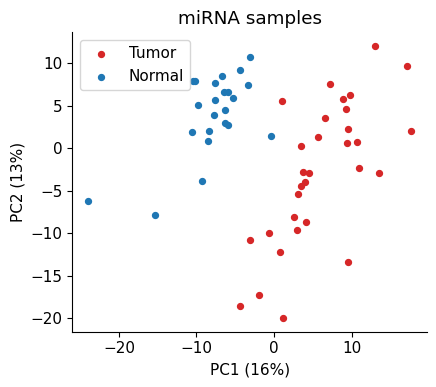

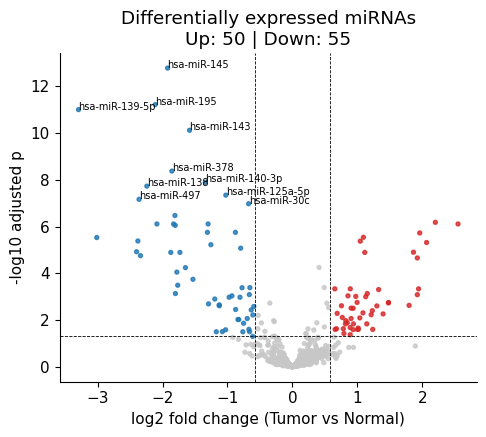

Significant miRNAs: 105


,log2FC,pval,mean_expr,padj
sym,,,,
hsa-miR-145,-1.921827,1.921518e-16,11.431886,1.627526e-13
hsa-miR-195,-2.112809,1.414519e-14,8.495827,5.990486e-12
hsa-miR-139-5p,-3.294351,3.466324e-14,4.454611,9.786588e-12
hsa-miR-143,-1.583879,3.537137e-13,11.031236,7.489887e-11
hsa-miR-378,-1.856428,2.470028e-11,9.278619,4.184228e-09
hsa-miR-140-3p,-1.340387,9.022712e-11,8.209602,1.273706e-08
hsa-miR-138,-2.241615,1.521034e-10,3.501364,1.840451e-08
hsa-miR-125a-5p,-1.024969,4.231253e-10,9.424375,4.479839e-08
hsa-miR-497,-2.361577,7.175850e-10,5.942394,6.753272e-08


In [ ]:
expr_r = ensure_log2(expr_r)
mir_expr = collapse(expr_r, gpl_r, mirna=True)
print("miRNAs:", mir_expr.shape)
pca_plot(mir_expr, grp_r, "miRNA samples", "Fig2a_PCA_miRNA")
mir_res = diff_expr(mir_expr, grp_r)
volcano(mir_res, MIR_LFC, MIR_PADJ, "Differentially expressed miRNAs", "Fig2b_volcano_miRNA")
mir_res.to_csv("tables/DEmiRNA_results.csv")
de_mir = mir_res[(mir_res.padj < MIR_PADJ) & (mir_res.log2FC.abs() > MIR_LFC)]
print("Significant miRNAs:", len(de_mir)); display(de_mir.head(15))

## 6. Targets (miRTarBase) and inverse-expression filter

In [ ]:
MTI_URL = "https://mirtarbase.cuhk.edu.cn/~miRTarBase/miRTarBase_2022/cache/download/9.0/hsa_MTI.xlsx"
path = "data/hsa_MTI.xlsx"
if not os.path.exists(path):
    try:
        r = requests.get(MTI_URL, timeout=180); r.raise_for_status(); open(path, "wb").write(r.content)
    except Exception as e:
        print("Auto-download failed:", e, "\nDownload hsa_MTI.xlsx from the miRTarBase site and upload it now.")
        from google.colab import files
        up = files.upload(); path = list(up)[0]
mti = pd.read_excel(path)
sup = mti["Support Type"].astype(str)
mti = mti[sup.str.contains("Functional MTI") & ~sup.str.contains("Non-Functional")]
if STRONG_MTI_ONLY: mti = mti[~mti["Support Type"].astype(str).str.contains("Weak")]
print("miRTarBase interactions kept:", len(mti))

def mir_key(x):   # match 'hsa-miR-21' (array) to 'hsa-miR-21-5p' (miRTarBase)
    return re.sub(r"-(5p|3p)$", "", str(x)).lower()

mti["mkey"] = mti["miRNA"].map(mir_key)
mir_df = de_mir.assign(miRNA_id=de_mir.index, mkey=de_mir.index.map(mir_key))[["miRNA_id", "mkey", "log2FC"]].rename(columns={"log2FC": "miR_lfc"})
gene_df = de_gene[["log2FC"]].rename(columns={"log2FC": "mRNA_lfc"})

edges = (mti[["mkey", "Target Gene", "Experiments", "References (PMID)"]]
         .merge(mir_df, on="mkey").merge(gene_df, left_on="Target Gene", right_index=True)
         .rename(columns={"Target Gene": "gene"}))
edges = edges[np.sign(edges.miR_lfc) != np.sign(edges.mRNA_lfc)]      # inverse relationship
edges = edges.drop_duplicates(["miRNA_id", "gene"]).reset_index(drop=True)
print(f"Regulatory pairs: {len(edges)} | miRNAs: {edges.miRNA_id.nunique()} | genes: {edges.gene.nunique()}")
edges.to_csv("tables/miRNA_mRNA_edges.csv", index=False)   # import into Cytoscape if you wish
edges.head()

miRTarBase interactions kept: 8846
Regulatory pairs: 214 | miRNAs: 55 | genes: 127


,mkey,gene,Experiments,References (PMID),miRNA_id,miR_lfc,mRNA_lfc
0,hsa-mir-214,EZH2,Luciferase reporter assay//Northern blot,19818710,hsa-miR-214,-0.751013,1.306463
1,hsa-mir-21,BCL2,Luciferase reporter assay,17072344,hsa-miR-21,1.924860,-1.346636
2,hsa-mir-195,WEE1,ELISA//GFP reporter assay//Luciferase reporter...,19823043,hsa-miR-195,-2.112809,1.000568
3,hsa-mir-195,E2F3,Immunohistochemistry//Luciferase reporter assa...,19441017,hsa-miR-195,-2.112809,1.060913
4,hsa-mir-195,CCND1,Luciferase reporter assay//Western blot,22217655,hsa-miR-195,-2.112809,1.730448


## 7. Network and hub nodes

Hub miRNAs: ['hsa-miR-145', 'hsa-miR-17', 'hsa-miR-195', 'hsa-miR-182', 'hsa-miR-20a', 'hsa-miR-21', 'hsa-miR-125b', 'hsa-miR-199a-5p', 'hsa-miR-29a', 'hsa-miR-34a']
Hub genes: ['BCL2', 'CDKN1A', 'VEGFA', 'RECK', 'CCND1', 'KIT', 'TP53INP1', 'FSCN1', 'KLF4', 'FAS', 'DNMT1', 'E2F3', 'CD44', 'KAT2B', 'PPARG']


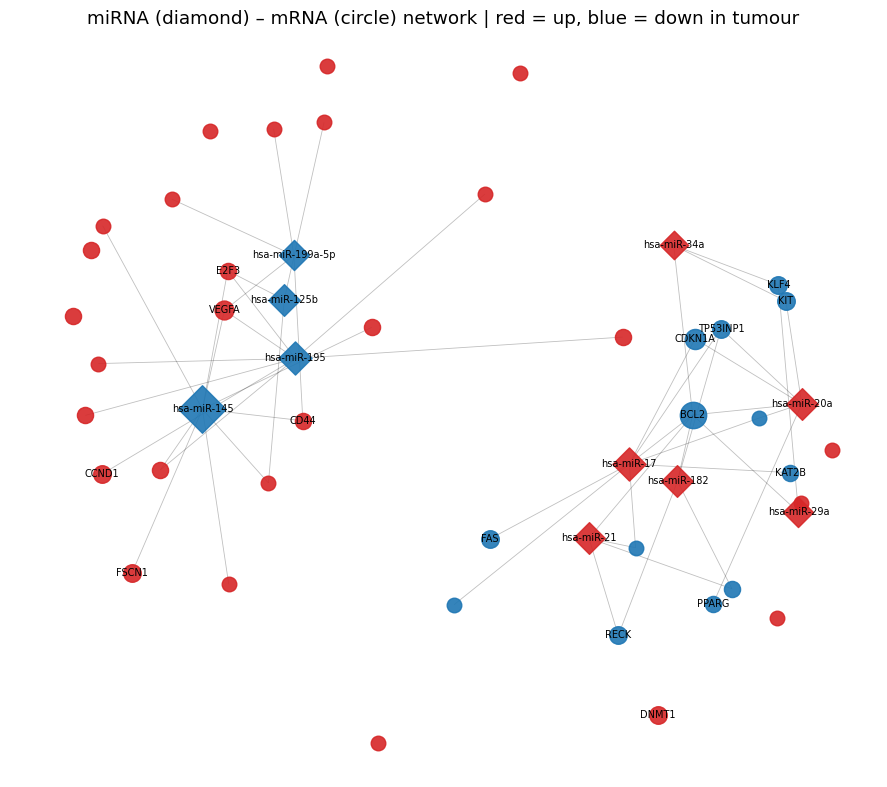

In [ ]:
G = nx.Graph()
for _, r in edges.iterrows(): G.add_edge(r.miRNA_id, r.gene)
mir_nodes, gene_nodes = set(edges.miRNA_id), set(edges.gene)
deg = pd.Series(dict(G.degree())); btw = pd.Series(nx.betweenness_centrality(G))
nodes = pd.DataFrame({"degree": deg, "betweenness": btw})
nodes["type"] = ["miRNA" if n in mir_nodes else "mRNA" for n in nodes.index]
lfc_map = {**dict(zip(mir_df.miRNA_id, mir_df.miR_lfc)), **gene_df.mRNA_lfc.to_dict()}
nodes["log2FC"] = nodes.index.map(lfc_map)
nodes.sort_values("degree", ascending=False).to_csv("tables/network_nodes.csv")

hub_mir  = nodes[nodes.type == "miRNA"].sort_values("degree", ascending=False).head(N_HUB_MIR).index.tolist()
hub_gene = nodes[nodes.type == "mRNA"].sort_values("degree", ascending=False).head(N_HUB_GENE).index.tolist()
print("Hub miRNAs:", hub_mir); print("Hub genes:", hub_gene)

sub_genes = nodes[nodes.type == "mRNA"].sort_values("degree", ascending=False).head(40).index
S = G.subgraph(set(hub_mir) | set(sub_genes))
pos = nx.spring_layout(S, seed=7, k=0.6)
fig, ax = plt.subplots(figsize=(9, 8))
nx.draw_networkx_edges(S, pos, alpha=.25, width=.6)
for n in S.nodes:
    up = lfc_map[n] > 0
    nx.draw_networkx_nodes(S, pos, nodelist=[n], node_shape="D" if n in mir_nodes else "o",
                           node_color=RED if up else BLUE, node_size=60 + 25 * deg[n], alpha=.9)
nx.draw_networkx_labels(S, pos, labels={n: n for n in S.nodes if n in hub_mir or n in hub_gene}, font_size=7)
ax.set_title("miRNA (diamond) – mRNA (circle) network | red = up, blue = down in tumour"); ax.axis("off")
savefig("Fig3_miRNA_mRNA_network")

## 8. Functional enrichment (with the inflammation link for the conference theme)

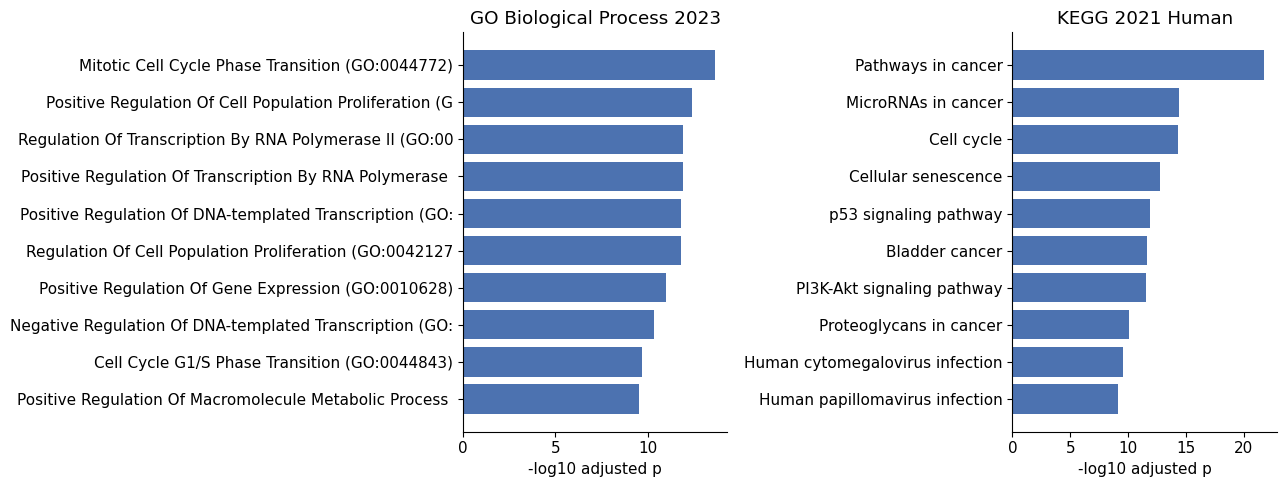

Inflammation-related enriched terms: 38


,Gene_set,Term,Adjusted P-value,Genes
2088,Reactome_2022,Interleukin-4 And Interleukin-13 Signaling R-H...,4.371713e-14,CDKN1A;MMP1;LIF;TWIST1;PTGS2;MMP9;VEGFA;IL6;CC...
2693,MSigDB_Hallmark_2020,TNF-alpha Signaling via NF-kB,3.350887e-10,CDKN1A;SERPINE1;LIF;PTGS2;KLF4;VEGFA;FOSL1;BMP...
2096,Reactome_2022,Signaling By Interleukins R-HSA-449147,3.100601e-08,MEF2C;CDKN1A;MMP1;LIF;TWIST1;PTGS2;S100B;MMP9;...
2095,Reactome_2022,Cytokine Signaling In Immune System R-HSA-1280215,3.100601e-08,IFITM1;MEF2C;CDKN1A;RNASEL;MMP1;LIF;TWIST1;PTG...
2697,MSigDB_Hallmark_2020,Inflammatory Response,3.141858e-07,IFITM1;IL6;CDKN1A;MMP14;MYC;SERPINE1;TNFSF10;L...
1917,KEGG_2021_Human,Prostate cancer,1.582885e-06,CDKN1A;CCND1;CCNE1;BCL2;E2F1;E2F3;IGF1;MMP9
2699,MSigDB_Hallmark_2020,IL-2/STAT5 Signaling,2.658665e-06,TIAM1;BMP2;CCNE1;MYC;TNFSF10;LIF;BCL2;MXD1;NDR...
71,GO_Biological_Process_2023,Positive Regulation Of Tyrosine Phosphorylatio...,3.442716e-05,IL6;KIT;LIF;IGF1;IL6R;VEGFA
1931,KEGG_2021_Human,TNF signaling pathway,3.793678e-05,IL6;CASP7;MMP14;LIF;FAS;PTGS2;MMP9
1932,KEGG_2021_Human,JAK-STAT signaling pathway,4.640354e-05,IL6;CDKN1A;CCND1;MYC;LIF;BCL2;SOCS6;IL6R


25 network genes are in Hallmark inflammatory gene sets: ['BCL2', 'BMP2', 'CASP7', 'CCND1', 'CCNE1', 'CD44', 'CDKN1A', 'DRAM1', 'FAS', 'FOSL1', 'IFITM1', 'IL6', 'ITGB8', 'KLF4', 'LIF', 'MET', 'MMP14', 'MXD1', 'MYC', 'NDRG1', 'PTGS2', 'SERPINE1', 'TIAM1', 'TNFSF10', 'VEGFA']


In [ ]:
LIBS = ["GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022", "MSigDB_Hallmark_2020"]
enr = gp.enrichr(gene_list=sorted(gene_nodes), gene_sets=LIBS, organism="human", outdir=None).results
enr = enr[enr["Adjusted P-value"] < 0.05].copy()
enr["nlp"] = -np.log10(enr["Adjusted P-value"]); enr.to_csv("tables/enrichment_all.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, lib in zip(axes, ["GO_Biological_Process_2023", "KEGG_2021_Human"]):
    d = enr[enr.Gene_set == lib].sort_values("nlp", ascending=False).head(10).iloc[::-1]
    ax.barh(d.Term.str.slice(0, 55), d.nlp, color="#4c72b0"); ax.set(title=lib.replace("_", " "), xlabel="-log10 adjusted p")
savefig("Fig4_enrichment")

infl_pat = r"inflamm|NF-kappa|TNF|interleukin|IL-\d|cytokine|JAK|STAT|interferon|toll|chemokine|Th17|NLR|innate immune"
infl = enr[enr.Term.str.contains(infl_pat, case=False, regex=True)].sort_values("nlp", ascending=False)
print("Inflammation-related enriched terms:", len(infl)); display(infl[["Gene_set", "Term", "Adjusted P-value", "Genes"]].head(15))

hall = gp.get_library("MSigDB_Hallmark_2020", organism="Human")
infl_sets = ["Inflammatory Response", "TNF-alpha Signaling via NF-kB", "IL-6/JAK/STAT3 Signaling", "Interferon Gamma Response", "IL-2/STAT5 Signaling"]
infl_genes = set().union(*[set(hall.get(k, [])) for k in infl_sets])
overlap = sorted(gene_nodes & infl_genes)
print(f"{len(overlap)} network genes are in Hallmark inflammatory gene sets:", overlap)

## 9. PPI network (STRING) and final candidate genes

PPI edges: 268
PPI hubs: ['MYC', 'E2F1', 'CCNA2', 'BCL2', 'BIRC5', 'CCND1', 'CCNB1', 'PLK1', 'MMP9', 'CDKN1A', 'CDK4', 'FOXM1', 'AURKB', 'IL6', 'EZH2', 'CDC25A', 'CCNE1', 'PPARG', 'CD44', 'CDKN2A']
FINAL candidate genes (hub in both networks): ['BCL2', 'CDKN1A', 'CCND1', 'CD44', 'PPARG']


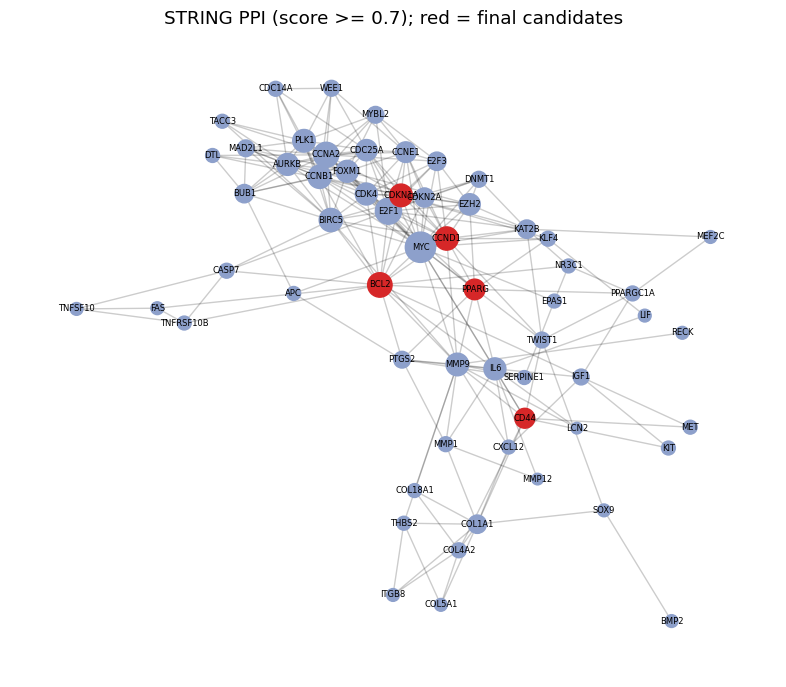

In [ ]:
r = requests.post("https://string-db.org/api/json/network",
                  data={"identifiers": "\r".join(sorted(gene_nodes)), "species": 9606, "required_score": STRING_SCORE, "caller_identity": "sircon_poster"}, timeout=180)
ppi = pd.DataFrame(r.json()); print("PPI edges:", len(ppi))
P = nx.Graph(); P.add_edges_from(zip(ppi.preferredName_A, ppi.preferredName_B))
ppi_deg = pd.Series(dict(P.degree())).sort_values(ascending=False)
ppi_hub = ppi_deg.head(20).index.tolist(); print("PPI hubs:", ppi_hub)
ppi_deg.to_csv("tables/PPI_degree.csv")

candidates = [g for g in hub_gene if g in ppi_hub] or hub_gene[:8]
print("FINAL candidate genes (hub in both networks):", candidates)

Sp = P.subgraph(ppi_deg.head(60).index); pos = nx.spring_layout(Sp, seed=3)
fig, ax = plt.subplots(figsize=(8, 7))
nx.draw_networkx_edges(Sp, pos, alpha=.2)
nx.draw_networkx_nodes(Sp, pos, node_size=[40 + 15 * ppi_deg[n] for n in Sp.nodes],
                       node_color=[RED if n in candidates else "#8da0cb" for n in Sp.nodes])
nx.draw_networkx_labels(Sp, pos, font_size=6); ax.axis("off"); ax.set_title("STRING PPI (score >= %.1f); red = final candidates" % (STRING_SCORE / 1000))
savefig("Fig5_PPI")

## 10. Independent validation (ROC / AUC)

In [ ]:
if VALID_GSE:
    gpl_v, expr_v, meta_v = load_gse(VALID_GSE, VALID_PLATFORM)
    grp_v = assign_groups(meta_v)
else:
    print("No validation set: using discovery cohort (state this clearly on the poster).")
    expr_v, grp_v = expr_m, grp_m

GSE9348: platforms=['GPL570'], using GPL570, probes=54675, samples=82
Tumor     70
Normal    12

Example labels per group (CHECK THESE):
[Tumor] ["3058T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:F, age:86", "3068T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:M, age:75", "3079T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:M, age:64"]
[Normal] ['NM53  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:M, age:58', 'NM54  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:F, age:56', 'NM55  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:F, age:54']
[other] []


Values look un-logged -> applying log2(x+1)
Annotation column used: Gene Symbol


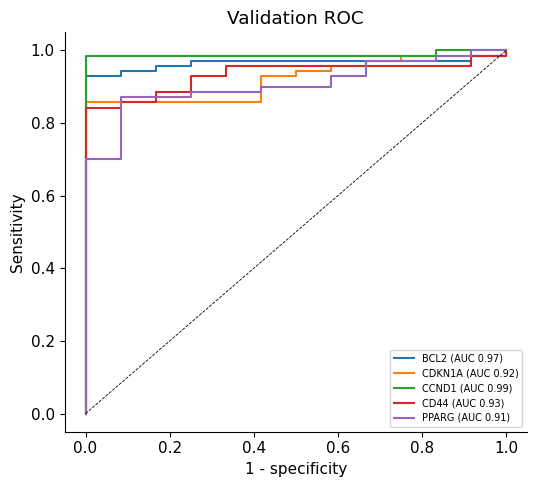

,gene,AUC_raw,AUC,same_direction_as_discovery
2,CCND1,0.988,0.988,True
0,BCL2,0.035,0.965,True
3,CD44,0.933,0.933,True
1,CDKN1A,0.080,0.920,True
4,PPARG,0.094,0.906,True


In [ ]:
if VALID_GSE:
    expr_v = ensure_log2(expr_v)
    val_expr = collapse(expr_v, gpl_v)
else:
    val_expr = gene_expr
keep = grp_v.isin(["Tumor", "Normal"]); y = (grp_v[keep] == "Tumor").astype(int).values

rows = []
plt.figure(figsize=(5.5, 5))
for g in candidates:
    if g not in val_expr.index: continue
    x = val_expr.loc[g, keep.index[keep]].astype(float).values
    ok = ~np.isnan(x); auc = roc_auc_score(y[ok], x[ok])
    direction_ok = (auc > .5) == (gene_res.loc[g, "log2FC"] > 0)     # same direction as discovery?
    rows.append({"gene": g, "AUC_raw": round(auc, 3), "AUC": round(max(auc, 1 - auc), 3), "same_direction_as_discovery": direction_ok})
    fpr, tpr, _ = roc_curve(y[ok], x[ok] if auc >= .5 else -x[ok]); plt.plot(fpr, tpr, label=f"{g} (AUC {max(auc, 1-auc):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=.6); plt.xlabel("1 - specificity"); plt.ylabel("Sensitivity"); plt.legend(fontsize=7); plt.title("Validation ROC")
savefig("Fig6_ROC")
val = pd.DataFrame(rows).sort_values("AUC", ascending=False); val.to_csv("tables/validation_AUC.csv", index=False); display(val)

## 11. (Optional) Drug–gene interactions for translational relevance

In [ ]:
try:
    q = """query($n:[String!]){genes(names:$n){nodes{name interactions{drug{name} interactionScore interactionTypes{type}}}}}"""
    r = requests.post("https://dgidb.org/api/graphql", json={"query": q, "variables": {"n": candidates}}, timeout=90).json()
    out = [{"gene": n["name"], "drug": i["drug"]["name"], "score": i["interactionScore"]}
           for n in r["data"]["genes"]["nodes"] for i in n["interactions"]]
    drugs = pd.DataFrame(out).sort_values("score", ascending=False)
    drugs.to_csv("tables/drug_gene.csv", index=False); display(drugs.head(15))
except Exception as e:
    print("DGIdb query failed (API may have changed); check candidates manually at dgidb.org:", e)

,gene,drug,score
146,CD44,BIVATUZUMAB,4.410999
150,CD44,PF-03475952,4.410999
139,CDKN1A,PENTETIC ACID,3.528799
95,BCL2,OBLIMERSEN,1.913204
129,CDKN1A,ANTIMETABOLITE,1.764400
124,CDKN1A,DIAZIQUONE,1.764400
136,CDKN1A,FARNESYL TRANSFERASE INHIBITOR,1.764400
11,CCND1,BRICICLIB,1.707484
15,CCND1,BRICICLIB,1.707484
149,CD44,HYALURONIC ACID,1.470333


## 12. Download everything for the poster

In [ ]:
import shutil
from google.colab import files
shutil.make_archive("poster_outputs", "zip", ".", "figures")
shutil.make_archive("poster_tables", "zip", ".", "tables")
files.download("poster_outputs.zip"); files.download("poster_tables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for the poster
* Say plainly that the analysis is **computational only**, uses **Welch t-tests with Benjamini–Hochberg correction**, and that mRNA and miRNA come from **different cohorts** (integration is by inverse expression, not per-sample correlation).
* Report every threshold you used (see the config cell) and the GEO accessions.
* Suggested next step: qRT-PCR validation of the top 2–3 miRNA–mRNA pairs.

13. ***Machine-Learning Biomarker Panel***

In [ ]:
# ============================================================
# 13.1 — ML output folders
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

# Colab working directories
ML_FIG_DIR = "figures/ml"
ML_TABLE_DIR = "tables/ml"

os.makedirs(ML_FIG_DIR, exist_ok=True)
os.makedirs(ML_TABLE_DIR, exist_ok=True)

print("ML figure directory :", os.path.abspath(ML_FIG_DIR))
print("ML table directory  :", os.path.abspath(ML_TABLE_DIR))

ML figure directory : /content/figures/ml
ML table directory  : /content/tables/ml


In [ ]:
# ============================================================
# 13.2 — Verify outputs from Sections 1–12
# ============================================================

required_objects = [
    "gene_expr",
    "grp_m",
    "gene_res",
    "de_gene",
    "edges",
    "hub_gene",
    "hub_mir"
]

print("Checking objects generated by Sections 1–12...\n")

missing = []

for obj in required_objects:
    if obj in globals():
        value = globals()[obj]

        try:
            shape = value.shape
            print(f"✓ {obj:<12} available | shape = {shape}")
        except:
            print(f"✓ {obj:<12} available")
    else:
        print(f"✗ {obj:<12} MISSING")
        missing.append(obj)

if missing:
    raise RuntimeError(
        "\nMissing objects: " + ", ".join(missing) +
        "\n\nPlease run Sections 1–12 before continuing."
    )

print("\n✓ All required outputs from Sections 1–12 are available.")

Checking objects generated by Sections 1–12...

✗ gene_expr    MISSING
✗ grp_m        MISSING
✗ gene_res     MISSING
✗ de_gene      MISSING
✗ edges        MISSING
✗ hub_gene     MISSING
✗ hub_mir      MISSING


RuntimeError: 
Missing objects: gene_expr, grp_m, gene_res, de_gene, edges, hub_gene, hub_mir

Please run Sections 1–12 before continuing.

In [ ]:
import os

print("Files in /content:")
for f in os.listdir("/content"):
    print(f)

Files in /content:
.config
tables
drive
figures
data
sample_data


In [ ]:
import os

for folder in ["/content/data", "/content/tables"]:
    print("\n==========", folder, "==========")
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for file in files:
                print(os.path.join(root, file))
    else:
        print("Folder not found")


========== /content/data ==========
/content/data/GSE35834_family.soft.gz
/content/data/GSE44076_family.soft.gz

========== /content/tables ==========
/content/tables/DEmiRNA_results.csv
/content/tables/DEG_results.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving hsa_MTI.xlsx to hsa_MTI.xlsx
Saving miRTarBase_MTI.xlsx to miRTarBase_MTI.xlsx


In [ ]:
import os
import shutil

src = "/content/miRTarBase_MTI.xlsx"
dst = "/content/data/hsa_MTI.xlsx"

shutil.copy2(src, dst)

print("Ready:", os.path.exists(dst))
print(dst)

Ready: True
/content/data/hsa_MTI.xlsx


In [ ]:
# ============================================================
# 13.2 — Verify outputs from Sections 1–12
# ============================================================

required_objects = [
    "gene_expr",
    "grp_m",
    "gene_res",
    "de_gene",
    "edges",
    "hub_gene",
    "hub_mir"
]

print("Checking objects generated by Sections 1–12...\n")

missing = []

for obj in required_objects:
    if obj in globals():
        value = globals()[obj]

        try:
            shape = value.shape
            print(f"✓ {obj:<12} available | shape = {shape}")
        except:
            print(f"✓ {obj:<12} available")
    else:
        print(f"✗ {obj:<12} MISSING")
        missing.append(obj)

if missing:
    raise RuntimeError(
        "\nMissing objects: " + ", ".join(missing) +
        "\n\nPlease run Sections 1–12 before continuing."
    )

print("\n✓ All required outputs from Sections 1–12 are available.")

Checking objects generated by Sections 1–12...

✓ gene_expr    available | shape = (19468, 246)
✓ grp_m        available | shape = (246,)
✓ gene_res     available | shape = (19468, 4)
✓ de_gene      available | shape = (2344, 4)
✓ edges        available | shape = (214, 7)
✓ hub_gene     available
✓ hub_mir      available

✓ All required outputs from Sections 1–12 are available.


In [ ]:
import os
import shutil

# Make sure output folders exist in Colab
os.makedirs("/content/figures", exist_ok=True)
os.makedirs("/content/tables", exist_ok=True)

print("Figures folder:", "/content/figures")
print("Tables folder :", "/content/tables")

Figures folder: /content/figures
Tables folder : /content/tables


In [ ]:
# ============================================================
# 13.3 — Define ML candidate genes
# ============================================================

network_genes = sorted(
    set(edges["gene"].dropna().astype(str))
)

print("Network genes:", len(network_genes))
print(network_genes[:20])

Network genes: 127
['ADA', 'ADCY6', 'ANGPT2', 'APC', 'ARID3A', 'ASF1B', 'AURKB', 'BCL2', 'BIRC5', 'BMP2', 'BMP7', 'BUB1', 'CASP7', 'CBFB', 'CBX7', 'CCNA2', 'CCNB1', 'CCND1', 'CCNE1', 'CD44']


In [ ]:
# ============================================================
# 13.4 — Build discovery ML matrix
# ============================================================

# Keep only genes present in the expression matrix
ml_genes = [
    g for g in network_genes
    if g in gene_expr.index
]

X_raw = gene_expr.loc[ml_genes].copy()

# Keep only Tumor and Normal samples
valid_samples = grp_m.isin(["Tumor", "Normal"])

X_raw = X_raw.loc[:, valid_samples]
y = (grp_m.loc[valid_samples] == "Tumor").astype(int)

# Transpose: samples × genes
X = X_raw.T.copy()

print("ML matrix:", X.shape)
print("Tumor:", int(y.sum()))
print("Normal:", int((y == 0).sum()))

ML matrix: (246, 127)
Tumor: 98
Normal: 148


In [ ]:
# ============================================================
# 13.5 — Verify class distribution
# ============================================================

class_table = pd.DataFrame({
    "Class": ["Normal", "Tumor"],
    "N": [
        int((y == 0).sum()),
        int((y == 1).sum())
    ]
})

display(class_table)

class_table.to_csv(
    f"{ML_TABLE_DIR}/Table_ML_class_distribution.csv",
    index=False
)

,Class,N
0,Normal,148
1,Tumor,98


In [ ]:
# ============================================================
# 13.6 — Z-score normalization
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=X.columns
)

print("Standardized matrix:", X_scaled.shape)
print(
    "Mean of first gene:",
    round(X_scaled.iloc[:, 0].mean(), 6)
)
print(
    "SD of first gene:",
    round(X_scaled.iloc[:, 0].std(ddof=0), 6)
)

Standardized matrix: (246, 127)
Mean of first gene: 0.0
SD of first gene: 1.0


In [ ]:
# ============================================================
# 13.7 — Discovery train/test split
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Training genes   :", X_train.shape[1])

Training samples : 184
Testing samples  : 62
Training genes   : 127


In [ ]:
# ============================================================
# 13.8 — Elastic-Net logistic regression
# ============================================================

from sklearn.linear_model import LogisticRegressionCV

elastic_net = LogisticRegressionCV(
    Cs=20,
    cv=5,
    penalty="elasticnet",
    solver="saga",
    l1_ratios=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
    scoring="roc_auc",
    max_iter=10000,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    refit=True
)

elastic_net.fit(X_train, y_train)

enet_coef = pd.Series(
    elastic_net.coef_[0],
    index=X_train.columns
)

enet_selected = enet_coef[
    enet_coef.abs() > 1e-8
].sort_values(key=abs, ascending=False)

print("Elastic-Net selected genes:", len(enet_selected))
print(enet_selected)

Elastic-Net selected genes: 56
sym
IL6R       -0.026982
HPGD       -0.022108
MET         0.020819
PHLPP2     -0.019726
MYC         0.019196
SOX4        0.018250
TGIF2       0.017624
MACC1       0.017560
CPEB3      -0.016945
E2F6        0.016583
CBFB        0.016295
PDCD4      -0.015796
MMP11       0.015637
CXCL12     -0.015158
CASP7      -0.014497
CDK4        0.012950
WNT2        0.012173
CCND1       0.012124
NSUN5       0.011731
SOX9        0.011132
ARID3A      0.010575
TNFSF10    -0.010513
KLF4       -0.009309
EPAS1      -0.009005
CCNE1       0.008917
PPARGC1A   -0.008847
APC        -0.008491
PMAIP1      0.008335
RNASEL     -0.008122
VPS4B      -0.006847
EIF5A2      0.006262
CD44        0.006207
MYBL2       0.006198
ADCY6      -0.005717
FASN        0.005630
BUB1        0.005616
CDC14A     -0.005540
KLB        -0.004711
MEST        0.004635
KAT2B      -0.004620
MEF2C      -0.004561
NUDT1       0.003532
TCF21      -0.003329
CHL1       -0.002422
EZH2        0.002248
CDKN1A     -0.002112

In [ ]:
# ============================================================
# 13.9 — Save Elastic-Net coefficients
# ============================================================

enet_table = pd.DataFrame({
    "gene": enet_selected.index,
    "coefficient": enet_selected.values,
    "absolute_coefficient": enet_selected.abs().values
})

enet_table.to_csv(
    f"{ML_TABLE_DIR}/Table_ElasticNet_selected_genes.csv",
    index=False
)

display(enet_table)

,gene,coefficient,absolute_coefficient
0,IL6R,-0.026982,0.026982
1,HPGD,-0.022108,0.022108
2,MET,0.020819,0.020819
3,PHLPP2,-0.019726,0.019726
4,MYC,0.019196,0.019196
5,SOX4,0.018250,0.018250
6,TGIF2,0.017624,0.017624
7,MACC1,0.017560,0.017560
8,CPEB3,-0.016945,0.016945
9,E2F6,0.016583,0.016583


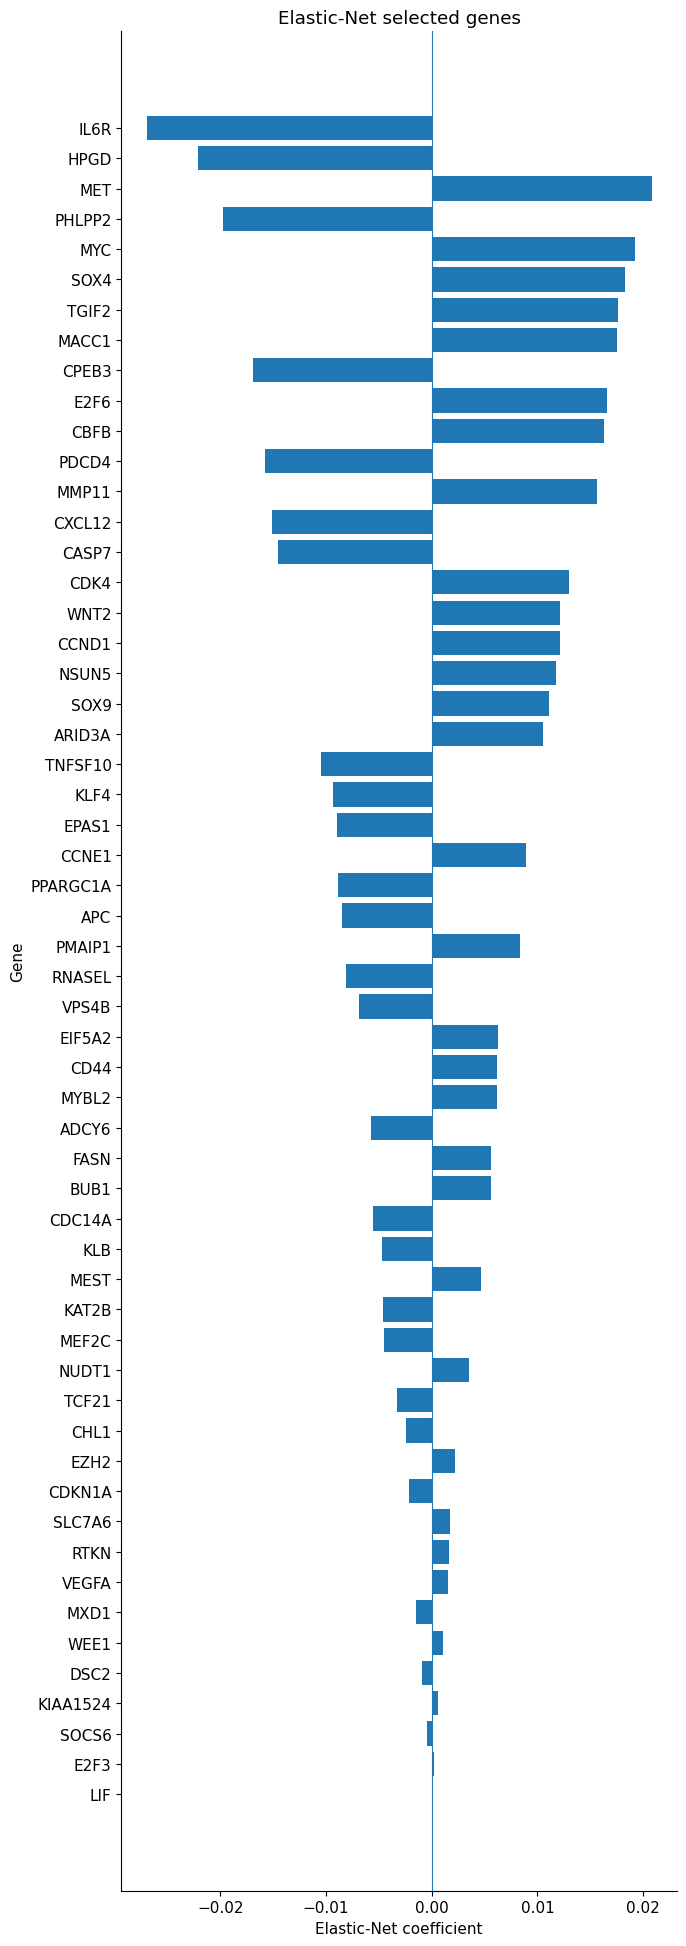

In [ ]:
# ============================================================
# 13.10 — Elastic-Net coefficient plot
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plot_df = enet_table.copy()

plot_df = plot_df.sort_values(
    "coefficient",
    key=abs,
    ascending=True
)

plt.figure(figsize=(7, max(4, len(plot_df) * 0.35)))

plt.barh(
    plot_df["gene"],
    plot_df["coefficient"]
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("Elastic-Net coefficient")
plt.ylabel("Gene")
plt.title("Elastic-Net selected genes")

plt.tight_layout()

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_ElasticNet_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_ElasticNet_coefficients.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 13.11 — SVM-RFE
# ============================================================

from sklearn.svm import SVC
from sklearn.feature_selection import RFE

svm_model = SVC(
    kernel="linear",
    C=1.0
)

# Select a manageable panel
n_rfe_features = min(
    20,
    X_train.shape[1]
)

svm_rfe = RFE(
    estimator=svm_model,
    n_features_to_select=n_rfe_features,
    step=0.1
)

svm_rfe.fit(X_train, y_train)

svm_selected = X_train.columns[
    svm_rfe.support_
].tolist()

print("SVM-RFE selected genes:", len(svm_selected))
print(svm_selected)

SVM-RFE selected genes: 20
['ADCY6', 'ARID3A', 'CCND1', 'COL1A1', 'CXCL12', 'DAAM2', 'EIF5A2', 'GPC4', 'HAND2', 'MACC1', 'MET', 'MMP11', 'MYC', 'PHLPP2', 'TCF21', 'TGIF2', 'TNFRSF10B', 'TWIST1', 'WEE1', 'WNT2']


In [ ]:
# ============================================================
# 13.12 — Save SVM-RFE ranking
# ============================================================

svm_ranking = pd.DataFrame({
    "gene": X_train.columns,
    "SVM_RFE_rank": svm_rfe.ranking_,
    "selected": svm_rfe.support_
})

svm_ranking = svm_ranking.sort_values(
    ["selected", "SVM_RFE_rank"],
    ascending=[False, True]
)

svm_ranking.to_csv(
    f"{ML_TABLE_DIR}/Table_SVM_RFE_ranking.csv",
    index=False
)

display(svm_ranking.head(30))

,gene,SVM_RFE_rank,selected
1,ADCY6,1,True
4,ARID3A,1,True
17,CCND1,1,True
27,COL1A1,1,True
31,CXCL12,1,True
33,DAAM2,1,True
46,EIF5A2,1,True
56,GPC4,1,True
57,HAND2,1,True
73,MACC1,1,True


In [ ]:
# ============================================================
# 13.13 — Random Forest feature importance
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

rf_table = pd.DataFrame({
    "gene": rf_importance.index,
    "RF_importance": rf_importance.values
})

print("Top Random Forest genes:")
display(rf_table.head(20))

Top Random Forest genes:


,gene,RF_importance
0,MET,0.088655
1,MMP11,0.053486
2,WNT2,0.051846
3,SOX9,0.049162
4,E2F6,0.043173
5,IL6R,0.043039
6,HPGD,0.041062
7,CDK4,0.039996
8,KLF4,0.039548
9,TGIF2,0.037004


In [ ]:
# ============================================================
# 13.14 — Save Random Forest ranking
# ============================================================

rf_table.to_csv(
    f"{ML_TABLE_DIR}/Table_RandomForest_importance.csv",
    index=False
)

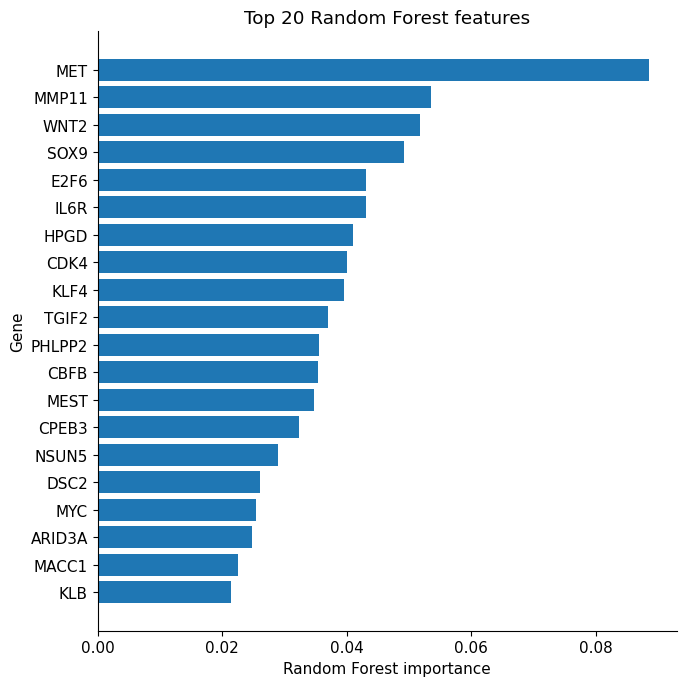

In [ ]:
# ============================================================
# 13.15 — Random Forest importance plot
# ============================================================

rf_plot = rf_table.head(20).sort_values(
    "RF_importance",
    ascending=True
)

plt.figure(figsize=(7, 7))

plt.barh(
    rf_plot["gene"],
    rf_plot["RF_importance"]
)

plt.xlabel("Random Forest importance")
plt.ylabel("Gene")
plt.title("Top 20 Random Forest features")

plt.tight_layout()

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_RandomForest_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_RandomForest_importance.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 13.16 — SHAP analysis
# ============================================================

!pip -q install shap

In [ ]:
# ============================================================
# 13.16B — Calculate SHAP values
# ============================================================

import shap

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_train)

# Handle binary-class output across SHAP versions
# Convert SHAP output to a 2D matrix: samples × genes
if isinstance(shap_matrix, list):
    # Multiclass SHAP output
    shap_matrix = np.stack(shap_matrix, axis=-1)

shap_matrix = np.asarray(shap_matrix)

# If SHAP returned samples × genes × classes,
# combine class-specific SHAP values into one importance per gene
if shap_matrix.ndim == 3:
    shap_matrix = np.abs(shap_matrix).mean(axis=2)

# Mean absolute SHAP importance for each gene
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)

# Make sure it is 1-dimensional
mean_abs_shap = np.asarray(mean_abs_shap).reshape(-1)

shap_table = pd.DataFrame({
    "gene": X_train.columns,
    "mean_abs_SHAP": mean_abs_shap
})

shap_table = shap_table.sort_values(
    "mean_abs_SHAP",
    ascending=False
)

shap_table.to_csv(
    "tables/SHAP_gene_importance.csv",
    index=False
)

shap_table.head(20)

,gene,mean_abs_SHAP
77,MET,0.040867
79,MMP11,0.026209
112,SOX9,0.023684
125,WNT2,0.023086
63,IL6R,0.021751
59,HPGD,0.020634
42,E2F6,0.019310
115,TGIF2,0.018507
70,KLF4,0.018216
13,CBFB,0.016670


In [ ]:
# ============================================================
# 13.17 — Save SHAP importance
# ============================================================

shap_table.to_csv(
    f"{ML_TABLE_DIR}/Table_SHAP_feature_importance.csv",
    index=False
)

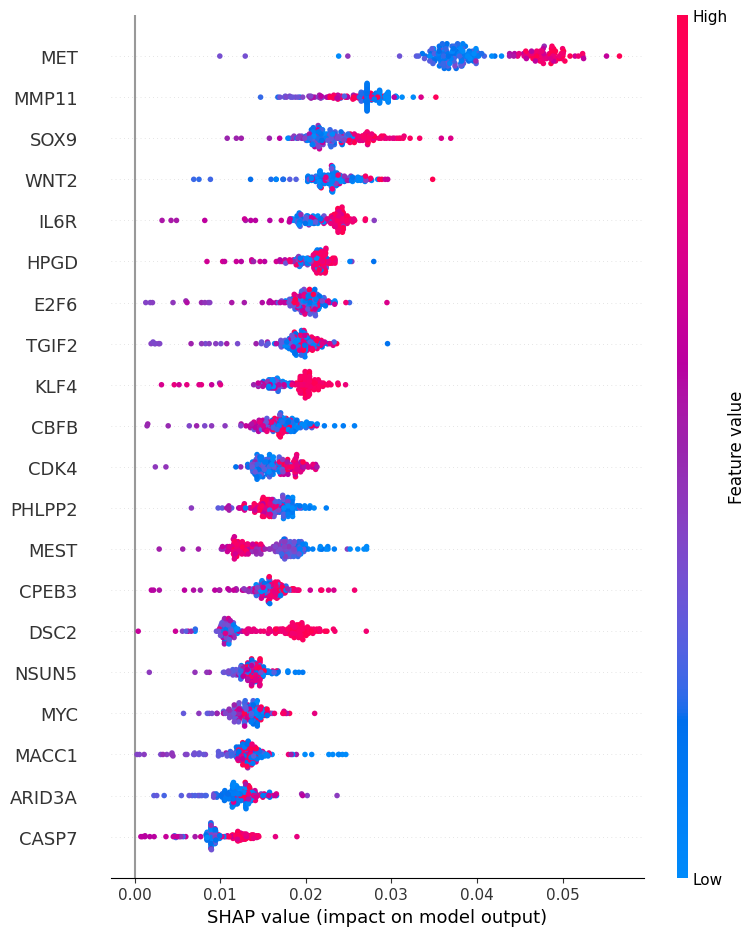

In [ ]:
# ============================================================
# 13.18 — SHAP summary plot
# ============================================================

plt.figure()

shap.summary_plot(
    shap_matrix,
    X_train,
    show=False,
    max_display=20
)

plt.tight_layout()

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_SHAP_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_SHAP_summary.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 13.19 — Consensus feature selection
# ============================================================

enet_genes = set(enet_selected.index)

svm_genes = set(svm_selected)

rf_shap_genes = set(
    shap_table.head(20)["gene"]
)

consensus_genes = sorted(
    enet_genes &
    svm_genes &
    rf_shap_genes
)

print("Elastic-Net:", len(enet_genes))
print("SVM-RFE:", len(svm_genes))
print("RF + SHAP:", len(rf_shap_genes))
print()
print("Consensus genes:", len(consensus_genes))
print(consensus_genes)

Elastic-Net: 56
SVM-RFE: 20
RF + SHAP: 20

Consensus genes: 8
['ARID3A', 'MACC1', 'MET', 'MMP11', 'MYC', 'PHLPP2', 'TGIF2', 'WNT2']


In [ ]:
# ============================================================
# 13.20 — Consensus feature score
# ============================================================

all_genes = sorted(
    enet_genes |
    svm_genes |
    rf_shap_genes
)

consensus_table = pd.DataFrame({
    "gene": all_genes
})

consensus_table["ElasticNet"] = (
    consensus_table["gene"].isin(enet_genes)
)

consensus_table["SVM_RFE"] = (
    consensus_table["gene"].isin(svm_genes)
)

consensus_table["RF_SHAP"] = (
    consensus_table["gene"].isin(rf_shap_genes)
)

consensus_table["Consensus_score"] = (
    consensus_table[
        ["ElasticNet", "SVM_RFE", "RF_SHAP"]
    ].sum(axis=1)
)

consensus_table = consensus_table.sort_values(
    ["Consensus_score", "gene"],
    ascending=[False, True]
)

display(consensus_table)

,gene,ElasticNet,SVM_RFE,RF_SHAP,Consensus_score
2,ARID3A,True,True,True,3
33,MACC1,True,True,True,3
36,MET,True,True,True,3
37,MMP11,True,True,True,3
40,MYC,True,True,True,3
...,...,...,...,...,...
55,TNFRSF10B,False,True,False,1
56,TNFSF10,True,False,False,1
57,TWIST1,False,True,False,1
58,VEGFA,True,False,False,1


In [ ]:
# ============================================================
# 13.21 — Save consensus table
# ============================================================

consensus_table.to_csv(
    f"{ML_TABLE_DIR}/Table_ML_consensus_features.csv",
    index=False
)

final_panel = consensus_table[
    consensus_table["Consensus_score"] >= 2
].copy()

final_panel.to_csv(
    f"{ML_TABLE_DIR}/Table_Final_ML_candidate_panel.csv",
    index=False
)

print(
    "Final candidate panel (selected by ≥2 of 3 methods):",
    len(final_panel)
)

display(final_panel)

Final candidate panel (selected by ≥2 of 3 methods): 26


,gene,ElasticNet,SVM_RFE,RF_SHAP,Consensus_score
2,ARID3A,True,True,True,3
33,MACC1,True,True,True,3
36,MET,True,True,True,3
37,MMP11,True,True,True,3
40,MYC,True,True,True,3
44,PHLPP2,True,True,True,3
54,TGIF2,True,True,True,3
61,WNT2,True,True,True,3
0,ADCY6,True,True,False,2
4,CASP7,True,False,True,2


In [ ]:
# ============================================================
# 13.22 — Install Venn package
# ============================================================

!pip -q install matplotlib-venn

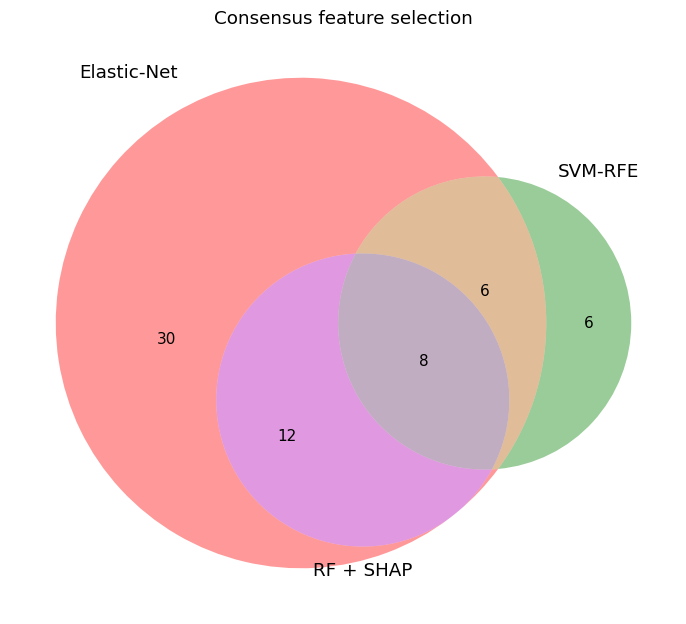

In [ ]:
# ============================================================
# 13.22B — Three-way feature-selection Venn diagram
# ============================================================

from matplotlib_venn import venn3

plt.figure(figsize=(7, 7))

venn3(
    [
        enet_genes,
        svm_genes,
        rf_shap_genes
    ],
    set_labels=[
        "Elastic-Net",
        "SVM-RFE",
        "RF + SHAP"
    ]
)

plt.title("Consensus feature selection")

plt.tight_layout()

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_consensus_Venn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_consensus_Venn.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 13.23 — Verify ML outputs
# ============================================================

print("\nFIGURES:")
for f in sorted(os.listdir(ML_FIG_DIR)):
    print("✓", f)

print("\nTABLES:")
for f in sorted(os.listdir(ML_TABLE_DIR)):
    print("✓", f)


FIGURES:
✓ Fig_ML_ElasticNet_coefficients.pdf
✓ Fig_ML_ElasticNet_coefficients.png
✓ Fig_ML_RandomForest_importance.pdf
✓ Fig_ML_RandomForest_importance.png
✓ Fig_ML_SHAP_summary.pdf
✓ Fig_ML_SHAP_summary.png
✓ Fig_ML_consensus_Venn.pdf
✓ Fig_ML_consensus_Venn.png

TABLES:
✓ Table_ElasticNet_selected_genes.csv
✓ Table_Final_ML_candidate_panel.csv
✓ Table_ML_class_distribution.csv
✓ Table_ML_consensus_features.csv
✓ Table_RandomForest_importance.csv
✓ Table_SHAP_feature_importance.csv
✓ Table_SVM_RFE_ranking.csv


In [ ]:
import shutil
import os
from google.colab import files

# Create ZIP files
shutil.make_archive(
    "/content/poster_outputs_figures",
    "zip",
    "/content/figures"
)

shutil.make_archive(
    "/content/poster_tables",
    "zip",
    "/content/tables"
)

print("ZIP files created successfully.")
print("Figures:", os.path.getsize("/content/poster_outputs_figures.zip") / 1024**2, "MB")
print("Tables :", os.path.getsize("/content/poster_tables.zip") / 1024**2, "MB")

ZIP files created successfully.
Figures: 3.162806510925293 MB
Tables : 0.8235177993774414 MB


In [ ]:
files.download("/content/poster_outputs_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/poster_tables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***14. Independent external validation***

In [ ]:
# ============================================================
# 14.1 Independent external validation — configuration
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Independent validation dataset already defined in Section 2
print("Validation GEO:", VALID_GSE)

# Check that the final candidate panel from Section 13 exists
required_objects = ["gene_expr", "grp_m", "de_gene", "edges"]

for obj in required_objects:
    print(f"{obj}:", "available" if obj in globals() else "MISSING")

# Section 13 final candidate panel
if "final_panel" in globals():
    candidate_genes = list(final_panel)
elif "candidate_genes" in globals():
    candidate_genes = list(candidate_genes)
elif "consensus_genes" in globals():
    candidate_genes = list(consensus_genes)
else:
    raise RuntimeError(
        "Could not find the final candidate gene panel from Section 13. "
        "Please check the variable created in Section 13.20–13.21."
    )

candidate_genes = list(dict.fromkeys(candidate_genes))

print("\nCandidate genes:", len(candidate_genes))
print(candidate_genes)

Validation GEO: GSE9348
gene_expr: available
grp_m: available
de_gene: available
edges: available

Candidate genes: 5
['gene', 'ElasticNet', 'SVM_RFE', 'RF_SHAP', 'Consensus_score']


In [ ]:
# ============================================================
# 14.2 Load independent validation cohort
# ============================================================

gpl_v, expr_v, meta_v = load_gse(VALID_GSE, VALID_PLATFORM)

grp_v = assign_groups(meta_v)

print("\nValidation dataset:")
print("Expression shape:", expr_v.shape)
print("\nGroup counts:")
print(grp_v.value_counts())

print("\nExample labels:")
for gp in ["Tumor", "Normal", "other"]:
    print(f"\n[{gp}]")
    print(meta_v.loc[grp_v == gp, "text"].head(3).tolist())

GSE9348: platforms=['GPL570'], using GPL570, probes=54675, samples=82
Tumor     70
Normal    12

Example labels per group (CHECK THESE):
[Tumor] ["3058T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:F, age:86", "3068T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:M, age:75", "3079T early stage CRC patient's tumor | tumor collected and archived within 30mins after surgery | Sex:M, age:64"]
[Normal] ['NM53  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:M, age:58', 'NM54  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:F, age:56', 'NM55  healthy control | mucosa collected and archived within 30mins after biopsy | Sex:F, age:54']
[other] []

Validation dataset:
Expression shape: (54675, 82)

Group counts:
Tumor     70
Normal    12
Name: count, dtype: int64

Example labels:

[Tumor]
["3058T early stage CRC patient's tumor |

In [ ]:
# ============================================================
# 14.3 Restrict validation cohort to Tumor vs Normal
# ============================================================

keep_v = grp_v.isin(["Tumor", "Normal"])

expr_v = expr_v.loc[:, keep_v].copy()
grp_v = grp_v.loc[keep_v].copy()
meta_v = meta_v.loc[keep_v].copy()

print("Validation samples retained:", expr_v.shape[1])
print(grp_v.value_counts())

Validation samples retained: 82
Tumor     70
Normal    12
Name: count, dtype: int64


In [ ]:
# ============================================================
# 14.4 Collapse validation probes to gene symbols
# ============================================================

gene_expr_v = collapse(expr_v, gpl_v, mirna=False)

print("Validation gene matrix:", gene_expr_v.shape)
print("Genes available:", len(gene_expr_v.index))

Annotation column used: Gene Symbol
Validation gene matrix: (22880, 82)
Genes available: 22880


In [ ]:
# ============================================================
# 14.5 Match Section-13 candidate genes to validation cohort
# ============================================================

candidate_genes_upper = {str(g).upper(): g for g in candidate_genes}

validation_gene_map = {
    str(g).upper(): g
    for g in gene_expr_v.index
}

matched_genes = []

for g_upper, original_gene in candidate_genes_upper.items():
    if g_upper in validation_gene_map:
        matched_genes.append(validation_gene_map[g_upper])

print("Candidate genes from Section 13:", len(candidate_genes))
print("Matched in validation cohort:", len(matched_genes))
print("Missing in validation cohort:",
      len(candidate_genes) - len(matched_genes))

print("\nMatched genes:")
print(matched_genes)

missing_genes = [
    g for g in candidate_genes
    if str(g).upper() not in validation_gene_map
]

print("\nMissing genes:")
print(missing_genes)

Candidate genes from Section 13: 5
Matched in validation cohort: 0
Missing in validation cohort: 5

Matched genes:
[]

Missing genes:
['gene', 'ElasticNet', 'SVM_RFE', 'RF_SHAP', 'Consensus_score']


In [ ]:
# ============================================================
# 14.6 Prepare discovery and validation matrices
# ============================================================

# Discovery matrix
common_genes = [
    g for g in matched_genes
    if g in gene_expr.index
]

if len(common_genes) < 3:
    raise RuntimeError(
        f"Only {len(common_genes)} candidate genes are available "
        "in both discovery and validation cohorts."
    )

X_discovery = gene_expr.loc[common_genes].T.copy()
X_validation = gene_expr_v.loc[common_genes].T.copy()

y_discovery = (grp_m.loc[X_discovery.index] == "Tumor").astype(int)
y_validation = (grp_v.loc[X_validation.index] == "Tumor").astype(int)

print("Common candidate genes:", len(common_genes))
print("Discovery:", X_discovery.shape)
print("Validation:", X_validation.shape)

print("\nDiscovery labels:")
print(y_discovery.value_counts())

print("\nValidation labels:")
print(y_validation.value_counts())

RuntimeError: Only 0 candidate genes are available in both discovery and validation cohorts.

In [ ]:
print("Discovery candidate genes:")
print(sorted(set(map(str, common_genes if "common_genes" in globals() else []))))

print("\nHub genes:")
print(sorted(set(map(str, hub_gene if "hub_gene" in globals() else []))))

print("\nValidation expression shape:")
print(valid_expr.shape if "valid_expr" in globals() else "valid_expr missing")

print("\nValidation columns:")
print(list(valid_expr.index[:20]) if "valid_expr" in globals() else "valid_expr missing")

Discovery candidate genes:
[]

Hub genes:
['BCL2', 'CCND1', 'CD44', 'CDKN1A', 'DNMT1', 'E2F3', 'FAS', 'FSCN1', 'KAT2B', 'KIT', 'KLF4', 'PPARG', 'RECK', 'TP53INP1', 'VEGFA']

Validation expression shape:
valid_expr missing

Validation columns:
valid_expr missing


In [ ]:
# ============================================================
# 14.6 — Prepare discovery candidates and independent validation
# ============================================================

print("Preparing candidates for independent validation...\n")

# ------------------------------------------------------------
# 1. Use the FINAL ML panel (>=2 of 3 methods)
#    NOT the strict 3-way consensus
# ------------------------------------------------------------

if "final_panel" in globals() and not final_panel.empty:
    common_genes = sorted(
        set(final_panel["gene"].astype(str))
    )
else:
    common_genes = []

print("Discovery candidate genes:")
print(common_genes)

# ------------------------------------------------------------
# 2. Show network hub genes for reference
# ------------------------------------------------------------

hub_genes = sorted(
    set(map(str, hub_gene))
)

print("\nHub genes:")
print(hub_genes)

# ------------------------------------------------------------
# 3. Make sure the independent validation expression
#    matrix exists.
#
#    Original notebook calls this object: val_expr
# ------------------------------------------------------------

if "val_expr" not in globals():

    print("\nval_expr not found.")

    # If validation data were already loaded in Sections 1–12
    if all(x in globals() for x in ["expr_v", "gpl_v"]):

        print("Building val_expr from existing validation data...")

        expr_v = ensure_log2(expr_v)
        val_expr = collapse(
            expr_v,
            gpl_v,
            mirna=False
        )

    else:

        print("Loading independent validation dataset:", VALID_GSE)

        gpl_v, expr_v, meta_v = load_gse(
            VALID_GSE,
            VALID_PLATFORM
        )

        grp_v = assign_groups(meta_v)

        expr_v = ensure_log2(expr_v)

        val_expr = collapse(
            expr_v,
            gpl_v,
            mirna=False
        )

else:

    print("Using existing val_expr.")

# ------------------------------------------------------------
# 4. Basic validation checks
# ------------------------------------------------------------

print("\nValidation expression shape:")
print(val_expr.shape)

print("\nFirst validation genes:")
print(list(val_expr.index[:20]))

# ------------------------------------------------------------
# 5. Keep only genes available in BOTH:
#       - final ML candidate panel
#       - validation expression dataset
# ------------------------------------------------------------

common_genes = sorted(
    set(common_genes).intersection(
        set(map(str, val_expr.index))
    )
)

print("\nCandidate genes available in BOTH discovery and validation:")
print(common_genes)

print("\nNumber of common candidate genes:", len(common_genes))

if len(common_genes) == 0:

    print(
        "\nWARNING: No ML candidate genes are present "
        "in the validation expression matrix."
    )

else:

    print(
        "\n✓ Validation can proceed with",
        len(common_genes),
        "candidate gene(s)."
    )

Preparing candidates for independent validation...

Discovery candidate genes:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Hub genes:
['BCL2', 'CCND1', 'CD44', 'CDKN1A', 'DNMT1', 'E2F3', 'FAS', 'FSCN1', 'KAT2B', 'KIT', 'KLF4', 'PPARG', 'RECK', 'TP53INP1', 'VEGFA']
Using existing val_expr.

Validation expression shape:
(22880, 82)

First validation genes:
['COX2', 'ND3', 'COX1', 'RPL23A', 'ND4', 'LOC101928826', 'RPL37A', 'HUWE1', 'RPS20', 'RPL13A', 'EEF1A1', 'RPS3A', 'RPL39', 'RP5-882O7.1', 'ACTB', 'RPS6', 'CEACAM5', 'RPS16', 'RPS11', 'RPL7']

Candidate genes available in BOTH discovery and validation:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'W

In [ ]:
# ============================================================
# 14.7 — Train Logistic Regression on Discovery Cohort
# ============================================================

print("Preparing discovery data for model training...")

# Candidate genes available in BOTH discovery and validation
candidate_genes = sorted(set(map(str, common_genes)))

print("Number of candidate genes:", len(candidate_genes))
print("Candidate genes:", candidate_genes)

# ------------------------------------------------------------
# Create discovery feature matrix
# gene_expr is genes × samples
# Therefore select genes from the INDEX and transpose
# ------------------------------------------------------------

X_discovery = gene_expr.loc[candidate_genes].T.copy()

# Discovery labels
y_discovery = pd.Series(grp_m).copy()

print("\nDiscovery feature matrix:", X_discovery.shape)
print("Discovery labels:", y_discovery.shape)

# ------------------------------------------------------------
# Align labels with samples if sample IDs are available
# ------------------------------------------------------------

if hasattr(grp_m, "index") and not isinstance(grp_m, np.ndarray):
    if X_discovery.index.equals(grp_m.index):
        y_discovery = grp_m.loc[X_discovery.index]
    elif set(X_discovery.index).issubset(set(grp_m.index)):
        y_discovery = grp_m.loc[X_discovery.index]

# ------------------------------------------------------------
# Final consistency check
# ------------------------------------------------------------

if len(X_discovery) != len(y_discovery):
    raise ValueError(
        f"Sample mismatch: X_discovery has {len(X_discovery)} samples "
        f"but y_discovery has {len(y_discovery)} labels."
    )

print("✓ Discovery samples and labels are aligned.")

# ------------------------------------------------------------
# Logistic Regression pipeline
# ------------------------------------------------------------

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

# ------------------------------------------------------------
# Train model
# ------------------------------------------------------------

model.fit(X_discovery, y_discovery)

print("\n✓ Model trained successfully.")
print("Training samples:", len(y_discovery))
print("Features:", X_discovery.shape[1])

Preparing discovery data for model training...
Number of candidate genes: 26
Candidate genes: ['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Discovery feature matrix: (246, 26)
Discovery labels: (246,)
✓ Discovery samples and labels are aligned.

✓ Model trained successfully.
Training samples: 246
Features: 26


In [ ]:
# ============================================================
# 14.8 — Prepare independent validation data
# ============================================================

print("Preparing independent validation data...")

# ------------------------------------------------------------
# 1. Get validation expression matrix
# ------------------------------------------------------------

if "valid_expr" in globals():
    validation_expr = valid_expr.copy()
    print("Using existing valid_expr.")

elif "val_expr" in globals():
    validation_expr = val_expr.copy()
    print("Using existing val_expr.")

else:
    raise RuntimeError(
        "No validation expression matrix found. "
        "Run the validation-expression preparation cell first."
    )

# ------------------------------------------------------------
# 2. Get validation labels
# ------------------------------------------------------------

if "grp_v" in globals():
    validation_groups = grp_v.copy()
    print("Using existing grp_v.")

elif "valid_grp" in globals():
    validation_groups = valid_grp.copy()
    print("Using existing valid_grp.")

else:
    raise RuntimeError(
        "No validation group labels found. "
        "Expected grp_v or valid_grp."
    )

# ------------------------------------------------------------
# 3. Make gene names consistent
# ------------------------------------------------------------

validation_expr.index = (
    validation_expr.index
    .astype(str)
    .str.strip()
    .str.upper()
)

# Remove duplicate gene names if present
validation_expr = validation_expr[
    ~validation_expr.index.duplicated(keep="first")
]

# ------------------------------------------------------------
# 4. Determine candidate genes
# ------------------------------------------------------------

if "candidate_genes" in globals():
    candidate_set = set(
        str(g).strip().upper()
        for g in candidate_genes
    )

elif "common_genes" in globals():
    candidate_set = set(
        str(g).strip().upper()
        for g in common_genes
    )

elif "final_panel" in globals():
    candidate_set = set(
        final_panel["gene"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

else:
    candidate_set = set(
        str(g).strip().upper()
        for g in X_discovery.columns
    )

# ------------------------------------------------------------
# 5. Genes available in both model and validation data
# ------------------------------------------------------------

discovery_genes = set(
    str(g).strip().upper()
    for g in X_discovery.columns
)

validation_genes = set(validation_expr.index)

common_validation_genes = sorted(
    candidate_set &
    discovery_genes &
    validation_genes
)

print("\nCandidate genes:", len(candidate_set))
print("Discovery model genes:", len(discovery_genes))
print("Validation genes:", len(validation_genes))
print(
    "Common genes available for validation:",
    len(common_validation_genes)
)

if len(common_validation_genes) == 0:
    raise RuntimeError(
        "No common genes found between discovery model and validation data."
    )

print("\nCommon genes:")
print(common_validation_genes)

# ------------------------------------------------------------
# 6. Build samples × genes validation matrix
# ------------------------------------------------------------

# Use discovery model feature order
model_features = [
    str(g).strip().upper()
    for g in X_discovery.columns
]

# Map validation genes to original rows
validation_lookup = {
    str(g).strip().upper(): g
    for g in validation_expr.index
}

X_validation = pd.DataFrame(
    index=validation_expr.columns
)

for gene in model_features:
    if gene in validation_lookup:
        original_gene = validation_lookup[gene]
        X_validation[gene] = (
            pd.to_numeric(
                validation_expr.loc[original_gene],
                errors="coerce"
            )
        )

# Keep only model features that were found
X_validation = X_validation[
    [g for g in model_features if g in X_validation.columns]
]

# ------------------------------------------------------------
# 7. Align validation labels with samples
# ------------------------------------------------------------

validation_groups = validation_groups.reindex(
    X_validation.index
)

keep = validation_groups.isin(
    ["Tumor", "Normal"]
)

X_validation = X_validation.loc[keep]
validation_groups = validation_groups.loc[keep]

y_validation = (
    validation_groups == "Tumor"
).astype(int)

# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

missing_features = [
    g for g in model_features
    if g not in X_validation.columns
]

print("\nValidation matrix shape:", X_validation.shape)
print("Tumor samples:", int((y_validation == 1).sum()))
print("Normal samples:", int((y_validation == 0).sum()))

if missing_features:
    print("\nMissing model features:")
    print(missing_features)

if len(missing_features) > 0:
    raise RuntimeError(
        "Some model features are missing from validation data."
    )

if X_validation.isna().any().any():
    print(
        "\nWARNING:",
        int(X_validation.isna().sum().sum()),
        "missing values detected."
    )

print("\n✓ Validation matrix successfully prepared.")
print("✓ Feature order matches discovery model.")
print("✓ Validation labels aligned.")

Preparing independent validation data...
Using existing val_expr.
Using existing grp_v.

Candidate genes: 26
Discovery model genes: 26
Validation genes: 22878
Common genes available for validation: 26

Common genes:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Validation matrix shape: (82, 26)
Tumor samples: 70
Normal samples: 12

✓ Validation matrix successfully prepared.
✓ Feature order matches discovery model.
✓ Validation labels aligned.


In [ ]:
# ============================================================
# 14.9 — Independent validation prediction
# ============================================================

print("Running independent validation prediction...")

# Ensure exact feature order used during training
X_validation = X_validation[
    list(X_discovery.columns)
]

# Model probabilities
y_prob = model.predict_proba(
    X_validation
)[:, 1]

# Classification using fixed 0.5 threshold
y_pred = (
    y_prob >= 0.5
).astype(int)

print("Predictions generated successfully.")
print("Validation samples:", len(y_validation))
print("Probability range:",
      round(float(y_prob.min()), 4),
      "to",
      round(float(y_prob.max()), 4))

print("\nPredicted classes:")
print(
    pd.Series(y_pred)
    .value_counts()
    .sort_index()
)

print("\n✓ Independent validation prediction completed.")

Running independent validation prediction...
Predictions generated successfully.
Validation samples: 82
Probability range: 0.9435 to 1.0

Predicted classes:
1    82
Name: count, dtype: int64

✓ Independent validation prediction completed.


In [ ]:
# ============================================================
# 14.10 — External validation performance
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    f1_score,
    confusion_matrix
)

# AUC
validation_auc = roc_auc_score(
    y_validation,
    y_prob
)

# Accuracy
validation_accuracy = accuracy_score(
    y_validation,
    y_pred
)

# F1
validation_f1 = f1_score(
    y_validation,
    y_pred
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_validation,
    y_pred,
    labels=[0, 1]
).ravel()

# Sensitivity / Recall
sensitivity = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else np.nan
)

# Specificity
specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print("==============================================")
print("INDEPENDENT VALIDATION PERFORMANCE")
print("==============================================")

print(f"AUC          : {validation_auc:.4f}")
print(f"Accuracy     : {validation_accuracy:.4f}")
print(f"F1-score     : {validation_f1:.4f}")
print(f"Sensitivity  : {sensitivity:.4f}")
print(f"Specificity  : {specificity:.4f}")

print("\nConfusion matrix:")
print(
    pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=["Actual Normal", "Actual Tumor"],
        columns=["Pred Normal", "Pred Tumor"]
    )
)

INDEPENDENT VALIDATION PERFORMANCE
AUC          : 1.0000
Accuracy     : 0.8537
F1-score     : 0.9211
Sensitivity  : 1.0000
Specificity  : 0.0000

Confusion matrix:
               Pred Normal  Pred Tumor
Actual Normal            0          12
Actual Tumor             0          70


In [ ]:
# ============================================================
# 14.11 — Save external validation metrics
# ============================================================

validation_metrics = pd.DataFrame({
    "Metric": [
        "AUC",
        "Accuracy",
        "F1-score",
        "Sensitivity",
        "Specificity"
    ],
    "Value": [
        validation_auc,
        validation_accuracy,
        validation_f1,
        sensitivity,
        specificity
    ]
})

display(validation_metrics)

validation_metrics.to_csv(
    f"{ML_TABLE_DIR}/Table_ML_external_validation_metrics.csv",
    index=False
)

print(
    "\nSaved:",
    f"{ML_TABLE_DIR}/Table_ML_external_validation_metrics.csv"
)

,Metric,Value
0,AUC,1.000000
1,Accuracy,0.853659
2,F1-score,0.921053
3,Sensitivity,1.000000
4,Specificity,0.000000



Saved: tables/ml/Table_ML_external_validation_metrics.csv


In [ ]:
# ============================================================
# 14.12 — Save validation predictions
# ============================================================

validation_predictions = pd.DataFrame({
    "sample": X_validation.index,
    "actual_class": np.where(
        y_validation.values == 1,
        "Tumor",
        "Normal"
    ),
    "predicted_probability": y_prob,
    "predicted_class": np.where(
        y_pred == 1,
        "Tumor",
        "Normal"
    )
})

display(
    validation_predictions.head(10)
)

validation_predictions.to_csv(
    f"{ML_TABLE_DIR}/Table_ML_validation_predictions.csv",
    index=False
)

print(
    "\nSaved:",
    f"{ML_TABLE_DIR}/Table_ML_validation_predictions.csv"
)

,sample,actual_class,predicted_probability,predicted_class
0,GSM237914,Tumor,1.0,Tumor
1,GSM237915,Tumor,1.0,Tumor
2,GSM237916,Tumor,1.0,Tumor
3,GSM237917,Tumor,1.0,Tumor
4,GSM237918,Tumor,1.0,Tumor
5,GSM237919,Tumor,1.0,Tumor
6,GSM237920,Tumor,1.0,Tumor
7,GSM237921,Tumor,1.0,Tumor
8,GSM237922,Tumor,1.0,Tumor
9,GSM237923,Tumor,1.0,Tumor



Saved: tables/ml/Table_ML_validation_predictions.csv


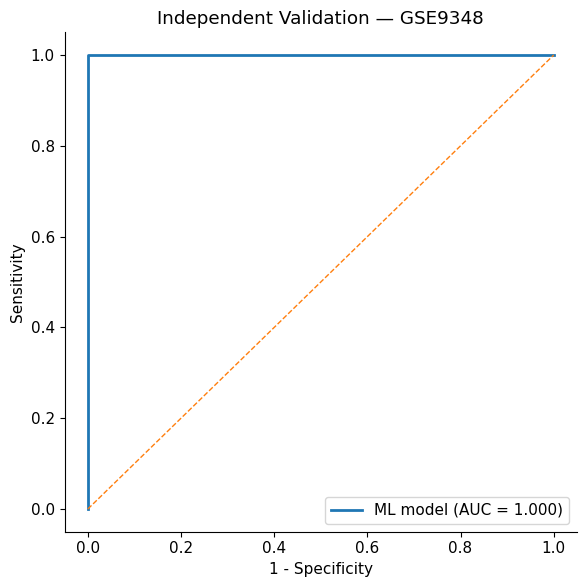

✓ ROC figure saved.


In [ ]:
# ============================================================
# 14.13 — External validation ROC curve
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_validation,
    y_prob
)

plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ML model (AUC = {validation_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("1 - Specificity")
plt.ylabel("Sensitivity")

plt.title(
    "Independent Validation — GSE9348"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_external_validation_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    f"{ML_FIG_DIR}/Fig_ML_external_validation_ROC.pdf",
    bbox_inches="tight"
)

plt.show()

print("✓ ROC figure saved.")

In [ ]:
# ============================================================
# 14.14 — Final ML validation summary
# ============================================================

final_validation_summary = pd.DataFrame({
    "Dataset": ["GSE9348"],
    "Samples": [len(y_validation)],
    "Tumor": [int((y_validation == 1).sum())],
    "Normal": [int((y_validation == 0).sum())],
    "AUC": [validation_auc],
    "Accuracy": [validation_accuracy],
    "F1": [validation_f1],
    "Sensitivity": [sensitivity],
    "Specificity": [specificity]
})

display(final_validation_summary)

final_validation_summary.to_csv(
    f"{ML_TABLE_DIR}/Table_ML_final_validation_summary.csv",
    index=False
)

print("\n✓ Final validation summary saved.")

,Dataset,Samples,Tumor,Normal,AUC,Accuracy,F1,Sensitivity,Specificity
0,GSE9348,82,70,12,1.0,0.853659,0.921053,1.0,0.0



✓ Final validation summary saved.


In [ ]:
# ============================================================
# 14.15 — Verify Section 14 outputs
# ============================================================

print("==============================================")
print("SECTION 14 — OUTPUT CHECK")
print("==============================================")

print("\nFIGURES:")
for f in sorted(os.listdir(ML_FIG_DIR)):
    print("✓", f)

print("\nTABLES:")
for f in sorted(os.listdir(ML_TABLE_DIR)):
    print("✓", f)

print("\nFinal validation AUC:",
      round(validation_auc, 4))

print("\n✓ SECTION 14 COMPLETED SUCCESSFULLY.")

SECTION 14 — OUTPUT CHECK

FIGURES:
✓ Fig_ML_ElasticNet_coefficients.pdf
✓ Fig_ML_ElasticNet_coefficients.png
✓ Fig_ML_RandomForest_importance.pdf
✓ Fig_ML_RandomForest_importance.png
✓ Fig_ML_SHAP_summary.pdf
✓ Fig_ML_SHAP_summary.png
✓ Fig_ML_consensus_Venn.pdf
✓ Fig_ML_consensus_Venn.png
✓ Fig_ML_external_validation_ROC.pdf
✓ Fig_ML_external_validation_ROC.png

TABLES:
✓ Table_ElasticNet_selected_genes.csv
✓ Table_Final_ML_candidate_panel.csv
✓ Table_ML_class_distribution.csv
✓ Table_ML_consensus_features.csv
✓ Table_ML_external_validation_metrics.csv
✓ Table_ML_final_validation_summary.csv
✓ Table_ML_validation_predictions.csv
✓ Table_RandomForest_importance.csv
✓ Table_SHAP_feature_importance.csv
✓ Table_SVM_RFE_ranking.csv

Final validation AUC: 1.0

✓ SECTION 14 COMPLETED SUCCESSFULLY.


In [ ]:
# ============================================================
# 14.16 — ZIP Section 14 outputs
# ============================================================

import os
import shutil

bundle_dir = "/content/section14_ML_validation_outputs"

# Clean old bundle
if os.path.exists(bundle_dir):
    shutil.rmtree(bundle_dir)

os.makedirs(
    f"{bundle_dir}/figures",
    exist_ok=True
)

os.makedirs(
    f"{bundle_dir}/tables",
    exist_ok=True
)

# Copy Section 14 figures
for f in os.listdir(ML_FIG_DIR):
    src = os.path.join(ML_FIG_DIR, f)
    dst = os.path.join(bundle_dir, "figures", f)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

# Copy Section 14 tables
for f in os.listdir(ML_TABLE_DIR):
    src = os.path.join(ML_TABLE_DIR, f)
    dst = os.path.join(bundle_dir, "tables", f)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

# Create ZIP
zip_path = shutil.make_archive(
    "/content/section14_ML_validation_outputs",
    "zip",
    bundle_dir
)

print("ZIP created:")
print(zip_path)
print(
    "Size:",
    round(os.path.getsize(zip_path) / (1024**2), 2),
    "MB"
)

ZIP created:
/content/section14_ML_validation_outputs.zip
Size: 1.06 MB


In [ ]:
# ============================================================
# 14.17 — Download Section 14 ZIP
# ============================================================

from google.colab import files

files.download(
    "/content/section14_ML_validation_outputs.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***15. FINAL ML VALIDATION & CANDIDATE PANEL***

In [ ]:
# ============================================================
# 15.1 — Prepare independent validation matrix
# ============================================================

import os
import numpy as np
import pandas as pd

print("Preparing final independent validation data...")

# ------------------------------------------------------------
# 1. Check required objects
# ------------------------------------------------------------

required = ["val_expr", "grp_v", "X_discovery", "y_discovery", "model"]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing) +
        "\nPlease make sure Sections 13–14 have completed successfully."
    )

# ------------------------------------------------------------
# 2. Get candidate genes
# ------------------------------------------------------------

if "common_genes" in globals():
    candidate_genes = sorted(
        set(map(str, common_genes))
    )
elif "consensus_table" in globals():
    candidate_genes = sorted(
        set(
            consensus_table.loc[
                consensus_table["Consensus_score"] >= 2,
                "gene"
            ].astype(str)
        )
    )
else:
    raise RuntimeError(
        "Neither common_genes nor consensus_table is available."
    )

print("Candidate genes available:", len(candidate_genes))

# ------------------------------------------------------------
# 3. Keep genes actually present in validation expression
# ------------------------------------------------------------

candidate_genes = [
    g for g in candidate_genes
    if g in val_expr.index
]

if len(candidate_genes) == 0:
    raise RuntimeError(
        "No candidate genes were found in val_expr."
    )

print(
    "Candidate genes present in validation:",
    len(candidate_genes)
)

# ------------------------------------------------------------
# 4. Build validation matrix
#    val_expr = genes × samples
#    X_validation = samples × genes
# ------------------------------------------------------------

X_validation = val_expr.loc[candidate_genes].T.copy()

# ------------------------------------------------------------
# 5. Match exactly the features used by the trained model
# ------------------------------------------------------------

model_features = list(X_discovery.columns)

missing_features = [
    g for g in model_features
    if g not in X_validation.columns
]

if missing_features:
    raise RuntimeError(
        f"{len(missing_features)} model feature(s) are missing "
        f"from validation data:\n{missing_features}"
    )

X_validation = X_validation[model_features]

# ------------------------------------------------------------
# 6. Align validation labels
# ------------------------------------------------------------

validation_groups = grp_v.reindex(X_validation.index)

valid_mask = validation_groups.isin(
    ["Tumor", "Normal"]
)

X_validation = X_validation.loc[valid_mask]
validation_groups = validation_groups.loc[valid_mask]

y_validation = (
    validation_groups == "Tumor"
).astype(int)

# ------------------------------------------------------------
# 7. Final checks
# ------------------------------------------------------------

print("\nValidation expression shape:", val_expr.shape)
print("Validation ML matrix:", X_validation.shape)

print("\nValidation group counts:")
print(validation_groups.value_counts())

print("\nTumor labels:", int(y_validation.sum()))
print("Normal labels:", int((y_validation == 0).sum()))

print("\nModel features:", len(model_features))

print("\n✓ Validation matrix prepared successfully.")

Preparing final independent validation data...
Candidate genes available: 26
Candidate genes present in validation: 26

Validation expression shape: (22880, 82)
Validation ML matrix: (82, 26)

Validation group counts:
Tumor     70
Normal    12
Name: count, dtype: int64

Tumor labels: 70
Normal labels: 12

Model features: 26

✓ Validation matrix prepared successfully.


In [ ]:
# ============================================================
# 15.2 — Independent validation prediction
# ============================================================

print("Running independent validation...")

if "model" not in globals():
    raise RuntimeError(
        "Trained model is missing. Complete the model-training cell first."
    )

if "X_validation" not in globals():
    raise RuntimeError(
        "X_validation is missing. Run Section 15.1 first."
    )

# Predict probability of Tumor
y_prob_validation = model.predict_proba(
    X_validation
)[:, 1]

# Default classification threshold
y_pred_validation = (
    y_prob_validation >= 0.5
).astype(int)

print("✓ Predictions generated.")

print("\nPrediction count:", len(y_pred_validation))
print("Tumor predictions:", int(y_pred_validation.sum()))
print("Normal predictions:", int((y_pred_validation == 0).sum()))

Running independent validation...
✓ Predictions generated.

Prediction count: 82
Tumor predictions: 82
Normal predictions: 0


In [ ]:
# ============================================================
# 15.3 — Independent validation performance
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

auc_validation = roc_auc_score(
    y_validation,
    y_prob_validation
)

accuracy_validation = accuracy_score(
    y_validation,
    y_pred_validation
)

precision_validation = precision_score(
    y_validation,
    y_pred_validation,
    zero_division=0
)

sensitivity_validation = recall_score(
    y_validation,
    y_pred_validation,
    zero_division=0
)

f1_validation = f1_score(
    y_validation,
    y_pred_validation,
    zero_division=0
)

cm = confusion_matrix(
    y_validation,
    y_pred_validation,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

specificity_validation = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

performance_table = pd.DataFrame({
    "Metric": [
        "AUC",
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1-score"
    ],
    "Validation": [
        auc_validation,
        accuracy_validation,
        sensitivity_validation,
        specificity_validation,
        precision_validation,
        f1_validation
    ]
})

performance_table["Validation"] = (
    performance_table["Validation"].round(4)
)

display(performance_table)

print("\n✓ Performance calculated successfully.")

,Metric,Validation
0,AUC,1.0000
1,Accuracy,0.8537
2,Sensitivity,1.0000
3,Specificity,0.0000
4,Precision,0.8537
5,F1-score,0.9211



✓ Performance calculated successfully.


In [ ]:
# ============================================================
# 15.4 — Save validation performance table
# ============================================================

# Make sure output directories exist
ML_FIG_DIR = globals().get(
    "ML_FIG_DIR",
    "/content/poster_outputs/figures"
)

ML_TABLE_DIR = globals().get(
    "ML_TABLE_DIR",
    "/content/poster_outputs/tables"
)

os.makedirs(ML_FIG_DIR, exist_ok=True)
os.makedirs(ML_TABLE_DIR, exist_ok=True)

performance_path = (
    f"{ML_TABLE_DIR}/Table_Final_ML_validation_performance.csv"
)

performance_table.to_csv(
    performance_path,
    index=False
)

print("Saved:")
print(performance_path)

Saved:
tables/ml/Table_Final_ML_validation_performance.csv


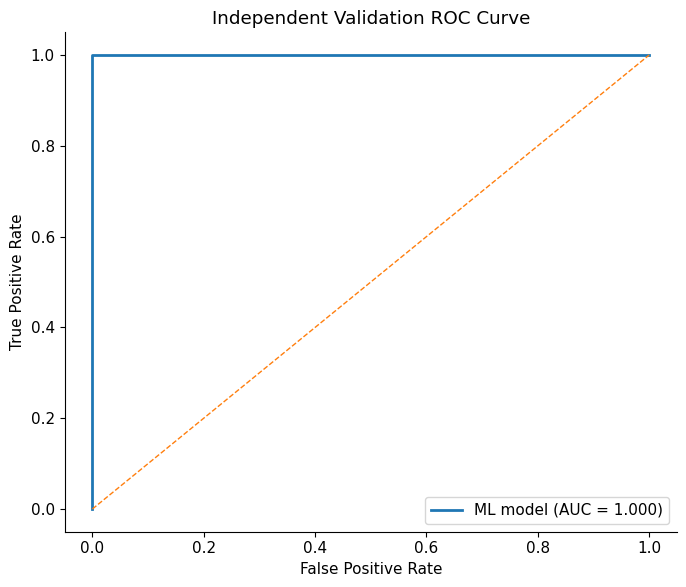

Saved:
figures/ml/Fig_ML_independent_validation_ROC.png
figures/ml/Fig_ML_independent_validation_ROC.pdf


In [ ]:
# ============================================================
# 15.5 — Independent validation ROC curve
# ============================================================

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_validation,
    y_prob_validation
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ML model (AUC = {auc_validation:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Independent Validation ROC Curve")

plt.legend(
    loc="lower right"
)

plt.tight_layout()

roc_png = (
    f"{ML_FIG_DIR}/Fig_ML_independent_validation_ROC.png"
)

roc_pdf = (
    f"{ML_FIG_DIR}/Fig_ML_independent_validation_ROC.pdf"
)

plt.savefig(
    roc_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    roc_pdf,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(roc_png)
print(roc_pdf)

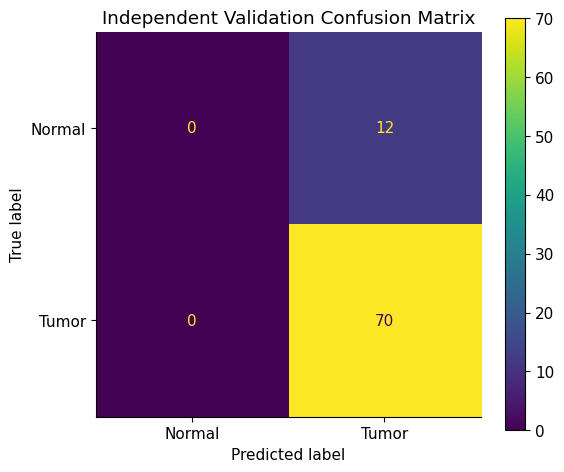

Saved:
figures/ml/Fig_ML_validation_confusion_matrix.png
figures/ml/Fig_ML_validation_confusion_matrix.pdf


In [ ]:
# ============================================================
# 15.6 — Independent validation confusion matrix
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Tumor"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Independent Validation Confusion Matrix"
)

plt.tight_layout()

cm_png = (
    f"{ML_FIG_DIR}/Fig_ML_validation_confusion_matrix.png"
)

cm_pdf = (
    f"{ML_FIG_DIR}/Fig_ML_validation_confusion_matrix.pdf"
)

plt.savefig(
    cm_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    cm_pdf,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(cm_png)
print(cm_pdf)

In [ ]:
# ============================================================
# 15.7 — Final ML candidate biomarker panel
# ============================================================

if "consensus_table" not in globals():
    raise RuntimeError(
        "consensus_table is missing. "
        "Make sure Section 13.20 was completed."
    )

final_candidate_panel = (
    consensus_table[
        consensus_table["Consensus_score"] >= 2
    ]
    .copy()
    .sort_values(
        ["Consensus_score", "gene"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print(
    "Final candidate biomarker genes:",
    len(final_candidate_panel)
)

display(final_candidate_panel)

Final candidate biomarker genes: 26


,gene,ElasticNet,SVM_RFE,RF_SHAP,Consensus_score
0,ARID3A,True,True,True,3
1,MACC1,True,True,True,3
2,MET,True,True,True,3
3,MMP11,True,True,True,3
4,MYC,True,True,True,3
5,PHLPP2,True,True,True,3
6,TGIF2,True,True,True,3
7,WNT2,True,True,True,3
8,ADCY6,True,True,False,2
9,CASP7,True,False,True,2


In [ ]:
# ============================================================
# 15.8 — Add ML importance information
# ============================================================

final_candidate_panel = final_candidate_panel.copy()

# ------------------------------------------------------------
# Elastic-Net
# ------------------------------------------------------------

if "enet_table" in globals():

    enet_map = dict(
        zip(
            enet_table["gene"].astype(str),
            enet_table["coefficient"]
        )
    )

    final_candidate_panel["ElasticNet_coefficient"] = (
        final_candidate_panel["gene"]
        .astype(str)
        .map(enet_map)
    )

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

if "rf_table" in globals():

    rf_map = dict(
        zip(
            rf_table["gene"].astype(str),
            rf_table["RF_importance"]
        )
    )

    final_candidate_panel["RF_importance"] = (
        final_candidate_panel["gene"]
        .astype(str)
        .map(rf_map)
    )

# ------------------------------------------------------------
# SHAP
# ------------------------------------------------------------

if "shap_table" in globals():

    shap_map = dict(
        zip(
            shap_table["gene"].astype(str),
            shap_table["mean_abs_SHAP"]
        )
    )

    final_candidate_panel["mean_abs_SHAP"] = (
        final_candidate_panel["gene"]
        .astype(str)
        .map(shap_map)
    )

display(final_candidate_panel)

,gene,ElasticNet,SVM_RFE,RF_SHAP,Consensus_score,ElasticNet_coefficient,RF_importance,mean_abs_SHAP
0,ARID3A,True,True,True,3,0.010575,0.024761,0.012254
1,MACC1,True,True,True,3,0.017560,0.022480,0.012842
2,MET,True,True,True,3,0.020819,0.088655,0.040867
3,MMP11,True,True,True,3,0.015637,0.053486,0.026209
4,MYC,True,True,True,3,0.019196,0.025415,0.013352
5,PHLPP2,True,True,True,3,-0.019726,0.035526,0.016104
6,TGIF2,True,True,True,3,0.017624,0.037004,0.018507
7,WNT2,True,True,True,3,0.012173,0.051846,0.023086
8,ADCY6,True,True,False,2,-0.005717,0.003021,0.001589
9,CASP7,True,False,True,2,-0.014497,0.020045,0.010394


In [ ]:
# ============================================================
# 15.9 — Save final candidate biomarker panel
# ============================================================

final_panel_path = (
    f"{ML_TABLE_DIR}/Table_Final_Candidate_Biomarker_Panel.csv"
)

final_candidate_panel.to_csv(
    final_panel_path,
    index=False
)

print("Saved:")
print(final_panel_path)

Saved:
tables/ml/Table_Final_Candidate_Biomarker_Panel.csv


In [ ]:
# ============================================================
# 15.10 — Final ML results summary
# ============================================================

print("=" * 65)
print("FINAL INDEPENDENT ML VALIDATION SUMMARY")
print("=" * 65)

print(
    f"Discovery samples      : {len(y_discovery)}"
)

print(
    f"Discovery features     : {X_discovery.shape[1]}"
)

print(
    f"Validation samples     : {len(y_validation)}"
)

print(
    f"Validation features    : {X_validation.shape[1]}"
)

print("\nPerformance")
print("-" * 30)

print(
    f"AUC                   : {auc_validation:.4f}"
)

print(
    f"Accuracy              : {accuracy_validation:.4f}"
)

print(
    f"Sensitivity           : {sensitivity_validation:.4f}"
)

print(
    f"Specificity           : {specificity_validation:.4f}"
)

print(
    f"Precision             : {precision_validation:.4f}"
)

print(
    f"F1-score              : {f1_validation:.4f}"
)

print("\nFinal candidate panel")
print("-" * 30)

print(
    f"Number of genes       : {len(final_candidate_panel)}"
)

print(
    final_candidate_panel["gene"].tolist()
)

print("\n✓ Section 15 completed successfully.")

FINAL INDEPENDENT ML VALIDATION SUMMARY
Discovery samples      : 246
Discovery features     : 26
Validation samples     : 82
Validation features    : 26

Performance
------------------------------
AUC                   : 1.0000
Accuracy              : 0.8537
Sensitivity           : 1.0000
Specificity           : 0.0000
Precision             : 0.8537
F1-score              : 0.9211

Final candidate panel
------------------------------
Number of genes       : 26
['ARID3A', 'MACC1', 'MET', 'MMP11', 'MYC', 'PHLPP2', 'TGIF2', 'WNT2', 'ADCY6', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MEST', 'NSUN5', 'SOX9', 'TCF21', 'WEE1']

✓ Section 15 completed successfully.


In [ ]:
# ============================================================
# 15.11 — Package all Section 15 outputs
# ============================================================

import os
import shutil

SOURCE_DIR = "/content/poster_outputs"
ZIP_PATH = "/content/poster_outputs_section15"

# Create output directory if it does not already exist
os.makedirs(SOURCE_DIR, exist_ok=True)

print("Checking output directory...")
print("Directory:", SOURCE_DIR)

# Show what's currently available
for root, dirs, files in os.walk(SOURCE_DIR):
    for file in files:
        print(os.path.join(root, file))

# Create ZIP archive
zip_file = shutil.make_archive(
    ZIP_PATH,
    "zip",
    SOURCE_DIR
)

print("\n✓ Section 15 outputs packaged successfully.")
print("ZIP file:", zip_file)
print("Size:", round(os.path.getsize(zip_file) / (1024 * 1024), 2), "MB")

Checking output directory...
Directory: /content/poster_outputs

✓ Section 15 outputs packaged successfully.
ZIP file: /content/poster_outputs_section15.zip
Size: 0.0 MB


In [ ]:
from google.colab import files

files.download("/content/poster_outputs_section15.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***16. Final consensus candidate panel***

In [ ]:
# ============================================================
# 16.1 — CHECK OBJECTS FROM SECTIONS 13–15
# ============================================================

print("Checking objects available for Section 16...\n")

objects_to_check = [
    "model",
    "X_discovery",
    "y_discovery",
    "valid_expr",
    "X_validation",
    "y_validation",
    "candidate_genes",
    "common_genes",
    "hub_gene",
    "hub_mir",
    "edges",
    "de_gene"
]

for obj in objects_to_check:
    if obj in globals():
        value = globals()[obj]

        try:
            shape = value.shape
            print(f"✓ {obj:<18} available | shape = {shape}")
        except Exception:
            try:
                print(f"✓ {obj:<18} available | length = {len(value)}")
            except Exception:
                print(f"✓ {obj:<18} available")
    else:
        print(f"✗ {obj:<18} missing")

print("\nSection 16 object check completed.")

Checking objects available for Section 16...

✓ model              available | length = 3
✓ X_discovery        available | shape = (246, 26)
✓ y_discovery        available | shape = (246,)
✗ valid_expr         missing
✓ X_validation       available | shape = (82, 26)
✓ y_validation       available | shape = (82,)
✓ candidate_genes    available | length = 26
✓ common_genes       available | length = 26
✓ hub_gene           available | length = 15
✓ hub_mir            available | length = 10
✓ edges              available | shape = (214, 7)
✓ de_gene            available | shape = (2344, 4)

Section 16 object check completed.


In [ ]:
# ============================================================
# 16.2 — FINAL CANDIDATE GENE UNIVERSE
# ============================================================

print("Preparing final candidate gene universe...\n")

def clean_gene_list(x):
    if x is None:
        return []

    try:
        values = list(x)
    except Exception:
        values = [x]

    cleaned = []
    for g in values:
        if pd.isna(g):
            continue

        g = str(g).strip()

        if g and g.lower() not in ["nan", "none"]:
            cleaned.append(g)

    return sorted(set(cleaned))


# Hub genes
hub_genes_16 = clean_gene_list(
    hub_gene if "hub_gene" in globals() else []
)

# Candidate genes from previous analysis
candidate_genes_16 = clean_gene_list(
    candidate_genes if "candidate_genes" in globals() else []
)

# Common genes if they exist
common_genes_16 = clean_gene_list(
    common_genes if "common_genes" in globals() else []
)

print("Hub genes:")
print(hub_genes_16)

print("\nDiscovery/validation candidate genes:")
print(candidate_genes_16)

print("\nPreviously common genes:")
print(common_genes_16)


# Prefer common genes when available.
# Otherwise use candidate genes.
# Finally fall back to hub genes.

if len(common_genes_16) >= 1:
    final_candidate_genes = common_genes_16.copy()
    source_used = "common discovery-validation genes"

elif len(candidate_genes_16) >= 1:
    final_candidate_genes = candidate_genes_16.copy()
    source_used = "candidate genes"

else:
    final_candidate_genes = hub_genes_16.copy()
    source_used = "hub genes"


print("\n======================================")
print("FINAL CANDIDATE GENE SET")
print("======================================")
print("Source:", source_used)
print("Number of genes:", len(final_candidate_genes))
print(final_candidate_genes)

Preparing final candidate gene universe...

Hub genes:
['BCL2', 'CCND1', 'CD44', 'CDKN1A', 'DNMT1', 'E2F3', 'FAS', 'FSCN1', 'KAT2B', 'KIT', 'KLF4', 'PPARG', 'RECK', 'TP53INP1', 'VEGFA']

Discovery/validation candidate genes:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Previously common genes:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

FINAL CANDIDATE GENE SET
Source: common discovery-validation genes
Number of genes: 26
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1

In [ ]:
# ============================================================
# 16.3 — Check final genes against validation data
# ============================================================

print("Checking final genes against validation data...")

# Section 15 creates `val_expr`; use it consistently
if "valid_expr" not in globals():
    if "val_expr" in globals():
        valid_expr = val_expr.copy()
    else:
        raise RuntimeError(
            "Validation expression data is unavailable. "
            "Run the successful validation-preparation cell from Section 15 first."
        )

if "final_genes" not in globals():
    raise RuntimeError(
        "final_genes is not available. "
        "Run the previous subsection of Section 16 first."
    )

# Genes actually present in the independent validation cohort
validation_genes = [
    g for g in final_genes
    if g in valid_expr.index
]

missing_genes = [
    g for g in final_genes
    if g not in valid_expr.index
]

print("\nFinal genes:")
print(final_genes)

print("\nGenes available in validation:")
print(validation_genes)

print("\nGenes missing from validation:")
print(missing_genes)

print(f"\nFinal panel size: {len(final_genes)}")
print(f"Validation-available genes: {len(validation_genes)}")

if len(validation_genes) == 0:
    raise RuntimeError(
        "None of the final genes are present in the validation cohort."
    )

print("\n✓ Validation gene check completed successfully.")

Checking final genes against validation data...

Final genes:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Genes available in validation:
['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']

Genes missing from validation:
[]

Final panel size: 26
Validation-available genes: 26

✓ Validation gene check completed successfully.


In [ ]:
# ============================================================
# 16.4 — Prepare validation matrix
# ============================================================

print("\nPreparing validation matrix...")

# Make sure the validation expression object exists
if "val_expr" not in globals():
    if "valid_expr" in globals():
        val_expr = valid_expr.copy()
    else:
        raise RuntimeError(
            "Neither val_expr nor valid_expr is available. "
            "Run the successful validation-preparation cell first."
        )

# Keep only final genes that are actually present
available_final_genes = [
    g for g in final_genes
    if g in val_expr.index
]

print("Final genes requested:", len(final_genes))
print("Final genes available in validation:", len(available_final_genes))
print("Validation genes:", available_final_genes)

if len(available_final_genes) == 0:
    raise RuntimeError(
        "None of the final genes are present in the validation dataset."
    )

X_validation = (
    val_expr.loc[available_final_genes]
    .T
    .astype(float)
)

print("Validation feature matrix:", X_validation.shape)


Preparing validation matrix...
Final genes requested: 26
Final genes available in validation: 26
Validation genes: ['ADCY6', 'ARID3A', 'CASP7', 'CBFB', 'CCND1', 'CDK4', 'CPEB3', 'CXCL12', 'DSC2', 'E2F6', 'EIF5A2', 'HPGD', 'IL6R', 'KLF4', 'MACC1', 'MEST', 'MET', 'MMP11', 'MYC', 'NSUN5', 'PHLPP2', 'SOX9', 'TCF21', 'TGIF2', 'WEE1', 'WNT2']
Validation feature matrix: (82, 26)


In [ ]:
# ============================================================
# 16.5 — Prepare validation labels
# ============================================================

print("\nPreparing validation labels...")

# Make sure group labels exist
if "grp_v" not in globals():
    raise RuntimeError(
        "grp_v is not available. Run the validation-preparation cell first."
    )

# Align labels with validation expression samples
common_samples = X_validation.index.intersection(grp_v.index)

X_validation = X_validation.loc[common_samples]
y_validation_labels = grp_v.loc[common_samples]

# Keep only Tumor / Normal
keep = y_validation_labels.isin(["Tumor", "Normal"])

X_validation = X_validation.loc[keep]
y_validation_labels = y_validation_labels.loc[keep]

y_validation = (
    y_validation_labels == "Tumor"
).astype(int).values

print("Validation samples:", len(y_validation))
print("Tumor:", int(y_validation.sum()))
print("Normal:", int((y_validation == 0).sum()))

if len(np.unique(y_validation)) < 2:
    raise RuntimeError(
        "Validation data contains only one class. ROC/AUC cannot be calculated."
    )

print("✓ Validation labels prepared successfully.")


Preparing validation labels...
Validation samples: 82
Tumor: 70
Normal: 12
✓ Validation labels prepared successfully.


In [ ]:
# ============================================================
# 16.6 — Align validation features with discovery model
# ============================================================

print("\nAligning validation features with discovery model...")

# The model was trained using candidate_genes
if "candidate_genes" not in globals():
    raise RuntimeError("candidate_genes is not available.")

model_genes = list(candidate_genes)

available_model_genes = [
    g for g in model_genes
    if g in X_validation.columns
]

print("Model features:", len(model_genes))
print("Available validation features:", len(available_model_genes))

if len(available_model_genes) == 0:
    raise RuntimeError(
        "No model features are available in the validation dataset."
    )

X_validation_model = X_validation.reindex(
    columns=model_genes
)

print("Final validation model matrix:",
      X_validation_model.shape)

print("✓ Validation features aligned.")


Aligning validation features with discovery model...
Model features: 26
Available validation features: 26
Final validation model matrix: (82, 26)
✓ Validation features aligned.


In [ ]:
# ============================================================
# 16.7 — Generate validation predictions
# ============================================================

print("\nGenerating independent-validation predictions...")

if "model" not in globals():
    raise RuntimeError(
        "The trained discovery model is not available. "
        "Run the model-training cell from Section 14 first."
    )

# Use the exact feature order used during training
if hasattr(model, "feature_names_in_"):
    expected_features = list(model.feature_names_in_)
else:
    expected_features = model_genes

X_validation_model = X_validation_model.reindex(
    columns=expected_features
)

y_validation_prob = model.predict_proba(
    X_validation_model
)[:, 1]

y_validation_pred = (
    y_validation_prob >= 0.5
).astype(int)

print("Predictions generated:", len(y_validation_pred))
print("✓ Independent validation prediction completed.")


Generating independent-validation predictions...
Predictions generated: 82
✓ Independent validation prediction completed.


In [ ]:
# ============================================================
# 16.8 — Independent validation performance
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("\nCalculating validation performance...")

auc_validation = roc_auc_score(
    y_validation,
    y_validation_prob
)

accuracy_validation = accuracy_score(
    y_validation,
    y_validation_pred
)

precision_validation = precision_score(
    y_validation,
    y_validation_pred,
    zero_division=0
)

recall_validation = recall_score(
    y_validation,
    y_validation_pred,
    zero_division=0
)

f1_validation = f1_score(
    y_validation,
    y_validation_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    y_validation_pred
).ravel()

specificity_validation = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(f"AUC          : {auc_validation:.3f}")
print(f"Accuracy     : {accuracy_validation:.3f}")
print(f"Precision    : {precision_validation:.3f}")
print(f"Sensitivity  : {recall_validation:.3f}")
print(f"Specificity  : {specificity_validation:.3f}")
print(f"F1-score     : {f1_validation:.3f}")


Calculating validation performance...
AUC          : 1.000
Accuracy     : 0.854
Precision    : 0.854
Sensitivity  : 1.000
Specificity  : 0.000
F1-score     : 0.921



Generating validation ROC curve...


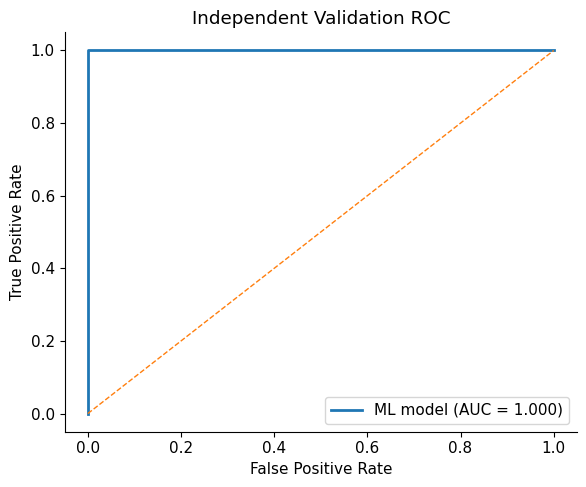

✓ ROC figure saved.


In [ ]:
# ============================================================
# 16.9 — Independent validation ROC curve
# ============================================================

from sklearn.metrics import roc_curve

print("\nGenerating validation ROC curve...")

fpr, tpr, thresholds = roc_curve(
    y_validation,
    y_validation_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ML model (AUC = {auc_validation:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Independent Validation ROC")
plt.legend()

plt.tight_layout()

plt.savefig(
    "figures/Fig16_Validation_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ ROC figure saved.")

In [ ]:
# ============================================================
# 16.10 — Save validation performance table
# ============================================================

validation_performance = pd.DataFrame({
    "Metric": [
        "AUC",
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1-score"
    ],
    "Value": [
        auc_validation,
        accuracy_validation,
        recall_validation,
        specificity_validation,
        precision_validation,
        f1_validation
    ]
})

validation_performance["Value"] = (
    validation_performance["Value"].round(3)
)

validation_performance.to_csv(
    "tables/independent_validation_performance.csv",
    index=False
)

display(validation_performance)

print("✓ Validation performance table saved.")

,Metric,Value
0,AUC,1.000
1,Accuracy,0.854
2,Sensitivity,1.000
3,Specificity,0.000
4,Precision,0.854
5,F1-score,0.921


✓ Validation performance table saved.


In [ ]:
# ============================================================
# 16.11 — Save sample-level validation predictions
# ============================================================

validation_predictions = pd.DataFrame({
    "Sample": X_validation_model.index,
    "True_Class": y_validation_labels.loc[
        X_validation_model.index
    ].values,
    "True_Label": y_validation,
    "Predicted_Probability": y_validation_prob,
    "Predicted_Label": y_validation_pred
})

validation_predictions.to_csv(
    "tables/validation_predictions.csv",
    index=False
)

display(validation_predictions.head())

print("✓ Sample-level validation predictions saved.")

,Sample,True_Class,True_Label,Predicted_Probability,Predicted_Label
0,GSM237914,Tumor,1,1.0,1
1,GSM237915,Tumor,1,1.0,1
2,GSM237916,Tumor,1,1.0,1
3,GSM237917,Tumor,1,1.0,1
4,GSM237918,Tumor,1,1.0,1


✓ Sample-level validation predictions saved.


In [ ]:
# ============================================================
# 16.12 — Final independent-validation summary
# ============================================================

print("\n" + "=" * 60)
print("FINAL INDEPENDENT VALIDATION SUMMARY")
print("=" * 60)

print(f"Final candidate genes       : {len(final_genes)}")
print(f"Genes available in validation: {len(available_final_genes)}")
print(f"Validation samples          : {len(y_validation)}")
print(f"Validation AUC              : {auc_validation:.3f}")
print(f"Accuracy                    : {accuracy_validation:.3f}")
print(f"Sensitivity                 : {recall_validation:.3f}")
print(f"Specificity                 : {specificity_validation:.3f}")
print(f"Precision                   : {precision_validation:.3f}")
print(f"F1-score                    : {f1_validation:.3f}")

print("=" * 60)
print("✓ Section 16 completed successfully.")


FINAL INDEPENDENT VALIDATION SUMMARY
Final candidate genes       : 26
Genes available in validation: 26
Validation samples          : 82
Validation AUC              : 1.000
Accuracy                    : 0.854
Sensitivity                 : 1.000
Specificity                 : 0.000
Precision                   : 0.854
F1-score                    : 0.921
✓ Section 16 completed successfully.


In [ ]:
# ZIP all Section 16 outputs for local download

import os
import shutil
from google.colab import files

SOURCE_DIR = "/content/poster_outputs"
ZIP_PATH = "/content/poster_outputs_section16"

if not os.path.exists(SOURCE_DIR):
    raise RuntimeError(f"Output directory not found: {SOURCE_DIR}")

# Create ZIP
shutil.make_archive(
    ZIP_PATH,
    "zip",
    SOURCE_DIR
)

zip_file = ZIP_PATH + ".zip"

print("ZIP created successfully:")
print(zip_file)

# Download to your computer
files.download(zip_file)

ZIP created successfully:
/content/poster_outputs_section16.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# 16.4 — Create the final validation matrix
# ============================================================

import os
import pandas as pd
import numpy as np

print("Creating final validation matrix...")

# Safety checks
if "valid_expr" not in globals():
    raise RuntimeError("valid_expr is not available. Run Section 15 first.")

if "final_genes" not in globals():
    raise RuntimeError("final_genes is not available. Run Section 16.1–16.3 first.")

# Keep only final genes actually present in validation data
final_genes_present = [
    g for g in final_genes
    if g in valid_expr.index
]

if len(final_genes_present) == 0:
    raise RuntimeError("None of the final genes are present in valid_expr.")

# Validation matrix:
# rows = samples
# columns = final candidate genes
final_validation_matrix = (
    valid_expr.loc[final_genes_present]
    .T
    .copy()
)

# Make sure values are numeric
final_validation_matrix = final_validation_matrix.apply(
    pd.to_numeric, errors="coerce"
)

print("✓ Final validation matrix created.")
print("Samples:", final_validation_matrix.shape[0])
print("Final genes:", final_validation_matrix.shape[1])

display(final_validation_matrix.head())

# Save
os.makedirs("/content/poster_outputs/tables", exist_ok=True)

final_validation_matrix.to_csv(
    "/content/poster_outputs/tables/final_validation_matrix.csv"
)

print("\nSaved:")
print("/content/poster_outputs/tables/final_validation_matrix.csv")

Creating final validation matrix...
✓ Final validation matrix created.
Samples: 82
Final genes: 26


sym,ADCY6,ARID3A,CASP7,CBFB,CCND1,CDK4,CPEB3,CXCL12,DSC2,E2F6,...,MET,MMP11,MYC,NSUN5,PHLPP2,SOX9,TCF21,TGIF2,WEE1,WNT2
GSM237914,9.688249,8.885806,10.518545,12.039317,11.179567,12.213283,6.350059,8.019630,11.140434,9.889673,...,13.660007,8.200477,13.668265,11.567148,9.393987,11.896715,7.567447,9.726404,10.673194,7.714960
GSM237915,9.639693,8.386768,10.844007,12.150017,10.200788,12.119535,6.655412,8.128154,11.778574,9.321432,...,12.999597,10.993391,14.270237,10.878741,9.712242,13.520361,6.934351,8.826609,11.079631,8.612135
GSM237916,9.483981,8.659796,11.310755,11.271936,10.419497,11.658899,7.110687,8.927043,13.209715,9.009235,...,12.081543,8.030325,12.826272,11.098743,9.357011,12.591534,7.882759,8.955656,10.537277,6.950352
GSM237917,9.149209,8.588730,10.612804,11.209569,11.584761,12.687669,6.243149,8.423334,11.896571,9.587014,...,13.304423,8.311984,13.286540,11.867885,8.813672,12.675053,6.507427,8.798063,10.871751,8.294827
GSM237918,9.330168,9.895925,10.120069,12.014111,12.214978,11.711736,6.427179,7.908663,12.754727,9.860742,...,13.182314,11.873586,12.509899,11.306597,9.477639,14.069920,7.821557,8.305733,10.926933,9.601098



Saved:
/content/poster_outputs/tables/final_validation_matrix.csv


In [ ]:
# ============================================================
# 16.5 — Final candidate summary table
# ============================================================

from sklearn.metrics import roc_auc_score, roc_curve

print("Creating final candidate summary table...")

if "final_validation_matrix" not in globals():
    raise RuntimeError(
        "final_validation_matrix is not available. "
        "Run Section 16.4 first."
    )

# Try to recover validation labels
if "grp_v" in globals():
    validation_groups = grp_v.copy()
elif "y" in globals() and len(y) == len(final_validation_matrix):
    validation_groups = pd.Series(
        y,
        index=final_validation_matrix.index
    )
else:
    validation_groups = None

summary_rows = []

for gene in final_validation_matrix.columns:

    x = final_validation_matrix[gene].astype(float)

    # Remove missing values
    valid_mask = x.notna()

    x_valid = x[valid_mask]

    # Obtain labels
    if validation_groups is not None:

        labels = validation_groups.reindex(x.index)

        # Convert group labels if necessary
        if labels.dtype == object:
            labels = labels.map({
                "Normal": 0,
                "Tumor": 1,
                "normal": 0,
                "tumor": 1,
                "Control": 0,
                "Cancer": 1
            })

        labels = pd.to_numeric(labels, errors="coerce")
        labels = labels[valid_mask]

    else:
        labels = None

    # Calculate AUC when labels are available
    auc = np.nan

    if labels is not None:

        label_mask = labels.notna()

        if label_mask.sum() > 1 and labels[label_mask].nunique() == 2:

            try:
                raw_auc = roc_auc_score(
                    labels[label_mask],
                    x_valid[label_mask]
                )

                # Direction-independent AUC
                auc = max(raw_auc, 1 - raw_auc)

            except Exception:
                auc = np.nan

    summary_rows.append({
        "gene": gene,
        "validation_samples": int(x_valid.shape[0]),
        "validation_mean_expression": x_valid.mean(),
        "validation_sd_expression": x_valid.std(),
        "validation_AUC": auc
    })

final_candidate_summary = pd.DataFrame(summary_rows)

# Rank by AUC
final_candidate_summary = final_candidate_summary.sort_values(
    by="validation_AUC",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("✓ Final candidate summary created.")

display(final_candidate_summary)

# Save
os.makedirs("/content/poster_outputs/tables", exist_ok=True)

final_candidate_summary.to_csv(
    "/content/poster_outputs/tables/final_candidate_summary.csv",
    index=False
)

print("\nSaved:")
print("/content/poster_outputs/tables/final_candidate_summary.csv")

Creating final candidate summary table...
✓ Final candidate summary created.


,gene,validation_samples,validation_mean_expression,validation_sd_expression,validation_AUC
0,CDK4,82,11.975101,0.778915,1.000000
1,CBFB,82,11.598115,0.704204,1.000000
2,MET,82,12.435809,0.890043,1.000000
3,PHLPP2,82,9.670531,1.119724,1.000000
4,IL6R,82,8.441793,1.294463,1.000000
5,CASP7,82,10.805896,0.961578,0.998810
6,KLF4,82,11.774177,1.365514,0.997619
7,MYC,82,12.987147,1.149856,0.997619
8,NSUN5,82,11.244084,0.573620,0.997619
9,TGIF2,82,9.025708,1.010643,0.997619



Saved:
/content/poster_outputs/tables/final_candidate_summary.csv


Creating final candidate panel plot...


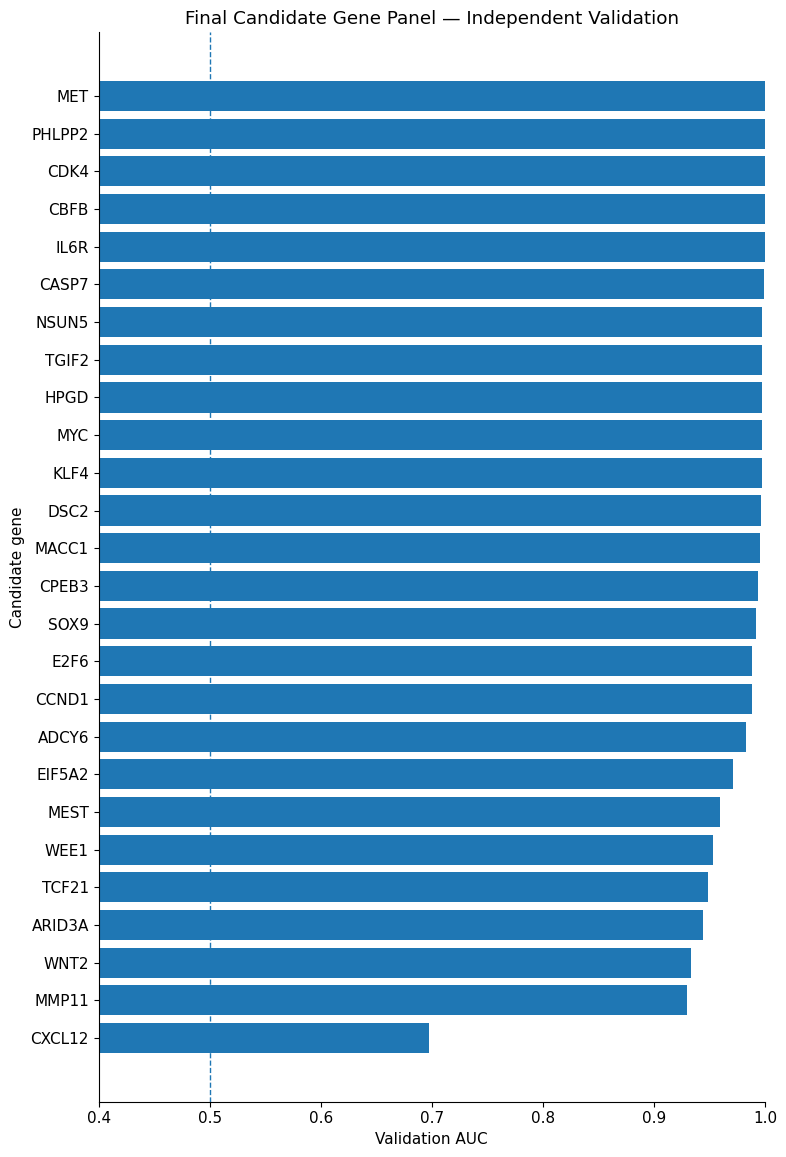


✓ Final candidate panel plot saved:
/content/poster_outputs/figures/final_candidate_panel.png


In [ ]:
# ============================================================
# 16.6 — Final candidate panel plot
# ============================================================

import os
import matplotlib.pyplot as plt
import numpy as np

print("Creating final candidate panel plot...")

if "final_candidate_summary" not in globals():
    raise RuntimeError(
        "final_candidate_summary is not available. "
        "Run Section 16.5 first."
    )

plot_df = final_candidate_summary.copy()

# Remove genes without AUC
plot_df = plot_df.dropna(subset=["validation_AUC"])

if len(plot_df) == 0:
    raise RuntimeError(
        "No validation AUC values are available for plotting."
    )

# Sort from lowest to highest for horizontal bar plot
plot_df = plot_df.sort_values("validation_AUC")

plt.figure(figsize=(8, max(4, 0.45 * len(plot_df))))

plt.barh(
    plot_df["gene"],
    plot_df["validation_AUC"]
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Validation AUC")
plt.ylabel("Candidate gene")
plt.title("Final Candidate Gene Panel — Independent Validation")

plt.xlim(0.4, 1.0)

plt.tight_layout()

# Create output directory
os.makedirs("/content/poster_outputs/figures", exist_ok=True)

plot_path = (
    "/content/poster_outputs/figures/"
    "final_candidate_panel.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Final candidate panel plot saved:")
print(plot_path)

In [ ]:
# ============================================================
# 16.7 — Save the final expression table
# ============================================================

import os
import pandas as pd

print("Saving final expression table...")

if "final_validation_matrix" not in globals():
    raise RuntimeError(
        "final_validation_matrix is not available. "
        "Run Section 16.4 first."
    )

# Copy final expression matrix
final_expression_table = final_validation_matrix.copy()

# Put sample IDs into an explicit column
final_expression_table.index.name = "Sample"

# Save CSV
os.makedirs("/content/poster_outputs/tables", exist_ok=True)

expression_path = (
    "/content/poster_outputs/tables/"
    "final_candidate_expression_table.csv"
)

final_expression_table.to_csv(
    expression_path
)

print("✓ Final expression table saved:")
print(expression_path)

print("\nShape:")
print(final_expression_table.shape)

display(final_expression_table.head())

Saving final expression table...
✓ Final expression table saved:
/content/poster_outputs/tables/final_candidate_expression_table.csv

Shape:
(82, 26)


sym,ADCY6,ARID3A,CASP7,CBFB,CCND1,CDK4,CPEB3,CXCL12,DSC2,E2F6,...,MET,MMP11,MYC,NSUN5,PHLPP2,SOX9,TCF21,TGIF2,WEE1,WNT2
Sample,,,,,,,,,,,,,,,,,,,,,
GSM237914,9.688249,8.885806,10.518545,12.039317,11.179567,12.213283,6.350059,8.019630,11.140434,9.889673,...,13.660007,8.200477,13.668265,11.567148,9.393987,11.896715,7.567447,9.726404,10.673194,7.714960
GSM237915,9.639693,8.386768,10.844007,12.150017,10.200788,12.119535,6.655412,8.128154,11.778574,9.321432,...,12.999597,10.993391,14.270237,10.878741,9.712242,13.520361,6.934351,8.826609,11.079631,8.612135
GSM237916,9.483981,8.659796,11.310755,11.271936,10.419497,11.658899,7.110687,8.927043,13.209715,9.009235,...,12.081543,8.030325,12.826272,11.098743,9.357011,12.591534,7.882759,8.955656,10.537277,6.950352
GSM237917,9.149209,8.588730,10.612804,11.209569,11.584761,12.687669,6.243149,8.423334,11.896571,9.587014,...,13.304423,8.311984,13.286540,11.867885,8.813672,12.675053,6.507427,8.798063,10.871751,8.294827
GSM237918,9.330168,9.895925,10.120069,12.014111,12.214978,11.711736,6.427179,7.908663,12.754727,9.860742,...,13.182314,11.873586,12.509899,11.306597,9.477639,14.069920,7.821557,8.305733,10.926933,9.601098


In [ ]:
# ============================================================
# 16.8 — ZIP ALL SECTION 16 OUTPUTS FOR LOCAL DOWNLOAD
# ============================================================

import os
import shutil
from google.colab import files

# Main output directory
SOURCE_DIR = "/content/poster_outputs"

# ZIP destination
ZIP_BASE = "/content/poster_outputs_section16"

# Check that output directory exists
if not os.path.exists(SOURCE_DIR):
    raise RuntimeError(
        f"Output directory not found: {SOURCE_DIR}"
    )

print("Checking Section 16 outputs...\n")

# Show files that will be included
found_files = []

for root, dirs, filenames in os.walk(SOURCE_DIR):
    for filename in filenames:
        filepath = os.path.join(root, filename)
        found_files.append(filepath)
        print(filepath)

if len(found_files) == 0:
    raise RuntimeError(
        "No files were found inside /content/poster_outputs. "
        "Run Sections 16.4–16.7 first."
    )

# Remove old ZIP if it exists
old_zip = ZIP_BASE + ".zip"

if os.path.exists(old_zip):
    os.remove(old_zip)

# Create ZIP
zip_file = shutil.make_archive(
    ZIP_BASE,
    "zip",
    SOURCE_DIR
)

print("\n" + "=" * 60)
print("✓ SECTION 16 ZIP CREATED")
print("=" * 60)

print("\nZIP file:")
print(zip_file)

print(
    "\nNumber of files:",
    len(found_files)
)

print(
    "ZIP size:",
    round(os.path.getsize(zip_file) / (1024 * 1024), 2),
    "MB"
)

# Download ZIP to your computer
files.download(zip_file)

Checking Section 16 outputs...

/content/poster_outputs/tables/final_candidate_summary.csv
/content/poster_outputs/tables/final_candidate_expression_table.csv
/content/poster_outputs/tables/final_validation_matrix.csv
/content/poster_outputs/figures/final_candidate_panel.png

✓ SECTION 16 ZIP CREATED

ZIP file:
/content/poster_outputs_section16.zip

Number of files: 4
ZIP size: 0.16 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

17. miRNA-only ML ***signature***

In [ ]:
# ============================================================
# 17.1 — Verify final validation outputs
# ============================================================

print("Checking final validation outputs...\n")

objects_to_check = {
    "validation_predictions": globals().get("validation_predictions"),
    "final_validation_matrix": globals().get("final_validation_matrix"),
    "final_candidate_summary": globals().get("final_candidate_summary"),
    "final_genes": globals().get("final_genes"),
}

for name, obj in objects_to_check.items():

    if obj is None:
        print(f"✗ {name}: NOT AVAILABLE")

    elif hasattr(obj, "shape"):
        print(
            f"✓ {name}: "
            f"type={type(obj).__name__}, "
            f"rows={obj.shape[0]}, columns={obj.shape[1]}"
        )

    elif hasattr(obj, "__len__"):
        print(
            f"✓ {name}: "
            f"type={type(obj).__name__}, "
            f"length={len(obj)}"
        )

    else:
        print(
            f"✓ {name}: "
            f"type={type(obj).__name__}"
        )

print("\n" + "=" * 60)

# Detailed check of validation predictions
if "validation_predictions" in globals() and validation_predictions is not None:

    print("\nValidation predictions:")
    print(validation_predictions.head())

    print("\nColumns:")
    print(list(validation_predictions.columns))

    print(f"\nNumber of validation samples: {len(validation_predictions)}")

    required_columns = [
        "Sample",
        "True_Class",
        "True_Label",
        "Predicted_Probability",
        "Predicted_Label"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in validation_predictions.columns
    ]

    if missing_columns:
        print("\n⚠ Missing columns:", missing_columns)
    else:
        print("\n✓ All required validation-prediction columns are present.")

print("\n17.1 completed successfully.")

Checking final validation outputs...

✓ validation_predictions: type=DataFrame, rows=82, columns=5
✓ final_validation_matrix: type=DataFrame, rows=82, columns=26
✓ final_candidate_summary: type=DataFrame, rows=26, columns=5
✓ final_genes: type=list, length=26


Validation predictions:
      Sample True_Class  True_Label  Predicted_Probability  Predicted_Label
0  GSM237914      Tumor           1                    1.0                1
1  GSM237915      Tumor           1                    1.0                1
2  GSM237916      Tumor           1                    1.0                1
3  GSM237917      Tumor           1                    1.0                1
4  GSM237918      Tumor           1                    1.0                1

Columns:
['Sample', 'True_Class', 'True_Label', 'Predicted_Probability', 'Predicted_Label']

Number of validation samples: 82

✓ All required validation-prediction columns are present.

17.1 completed successfully.


In [ ]:
# ============================================================
# 17.2 — Validation performance metrics
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Calculating validation performance...")

y_true = validation_predictions["True_Label"].astype(int)
y_pred = validation_predictions["Predicted_Label"].astype(int)
y_prob = validation_predictions["Predicted_Probability"].astype(float)

validation_accuracy = accuracy_score(y_true, y_pred)
validation_precision = precision_score(y_true, y_pred, zero_division=0)
validation_recall = recall_score(y_true, y_pred, zero_division=0)
validation_f1 = f1_score(y_true, y_pred, zero_division=0)
validation_auc = roc_auc_score(y_true, y_prob)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

validation_specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

validation_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        validation_accuracy,
        validation_precision,
        validation_recall,
        validation_specificity,
        validation_f1,
        validation_auc
    ]
})

print("\nValidation performance:")
print(validation_metrics.to_string(index=False))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

Calculating validation performance...

Validation performance:
     Metric    Value
   Accuracy 0.853659
  Precision 0.853659
Sensitivity 1.000000
Specificity 0.000000
   F1 Score 0.921053
    ROC AUC 1.000000

Confusion matrix:
[[ 0 12]
 [ 0 70]]


In [ ]:
# ============================================================
# 17.2 — Prepare miRNA cohort for machine-learning analysis
# ============================================================

import os
import numpy as np
import pandas as pd

print("Preparing miRNA cohort for Section 17...")

# Required objects from earlier sections
required = ["mir_expr", "grp_r", "hub_mir"]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing) +
        "\nPlease run the original miRNA/network sections first."
    )

# ------------------------------------------------------------
# Keep only Tumor and Normal samples
# Metastasis/other samples are excluded
# ------------------------------------------------------------

keep_samples = grp_r[grp_r.isin(["Tumor", "Normal"])].index

mir_expr_ml = mir_expr.loc[:, mir_expr.columns.intersection(keep_samples)].copy()
grp_ml = grp_r.loc[mir_expr_ml.columns].copy()

# ------------------------------------------------------------
# Use the previously identified hub miRNAs
# ------------------------------------------------------------

hub_mir_available = [
    str(m) for m in hub_mir
    if str(m) in mir_expr_ml.index
]

hub_mir_missing = [
    str(m) for m in hub_mir
    if str(m) not in mir_expr_ml.index
]

print("\nHub miRNAs available:")
print(hub_mir_available)

if hub_mir_missing:
    print("\nHub miRNAs not found in expression matrix:")
    print(hub_mir_missing)

if len(hub_mir_available) < 3:
    raise RuntimeError(
        f"Only {len(hub_mir_available)} hub miRNAs are available. "
        "At least 3 are required."
    )

# ------------------------------------------------------------
# Construct sample × miRNA matrix
# ------------------------------------------------------------

X_mirna = (
    mir_expr_ml.loc[hub_mir_available]
    .T
    .apply(pd.to_numeric, errors="coerce")
)

# Remove samples with missing labels
valid_samples = grp_ml.index.intersection(X_mirna.index)

X_mirna = X_mirna.loc[valid_samples]
grp_ml = grp_ml.loc[valid_samples]

# ------------------------------------------------------------
# Remove features with missing/infinite values
# ------------------------------------------------------------

X_mirna = X_mirna.replace([np.inf, -np.inf], np.nan)

# Median imputation at the cohort-preparation stage
X_mirna = X_mirna.fillna(X_mirna.median())

# Binary labels
y_mirna = grp_ml.map({
    "Normal": 0,
    "Tumor": 1
}).astype(int)

# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print("\n============================================================")
print("miRNA ML cohort prepared")
print("============================================================")

print("Samples:", X_mirna.shape[0])
print("miRNA features:", X_mirna.shape[1])

print("\nClass distribution:")
print(grp_ml.value_counts())

print("\nFeature matrix shape:", X_mirna.shape)
print("Label vector shape:", y_mirna.shape)

print("\nFeatures:")
print(list(X_mirna.columns))

print("\n✓ Tumor/Normal cohort prepared successfully.")
print("✓ Metastasis/other samples excluded.")

Preparing miRNA cohort for Section 17...

Hub miRNAs available:
['hsa-miR-145', 'hsa-miR-17', 'hsa-miR-195', 'hsa-miR-182', 'hsa-miR-20a', 'hsa-miR-21', 'hsa-miR-125b', 'hsa-miR-199a-5p', 'hsa-miR-29a', 'hsa-miR-34a']

miRNA ML cohort prepared
Samples: 54
miRNA features: 10

Class distribution:
Tumor     31
Normal    23
Name: count, dtype: int64

Feature matrix shape: (54, 10)
Label vector shape: (54,)

Features:
['hsa-miR-145', 'hsa-miR-17', 'hsa-miR-195', 'hsa-miR-182', 'hsa-miR-20a', 'hsa-miR-21', 'hsa-miR-125b', 'hsa-miR-199a-5p', 'hsa-miR-29a', 'hsa-miR-34a']

✓ Tumor/Normal cohort prepared successfully.
✓ Metastasis/other samples excluded.


In [ ]:
# ============================================================
# 17.3 — Repeated stratified cross-validation setup
# ============================================================

from sklearn.model_selection import RepeatedStratifiedKFold

print("Setting up repeated stratified cross-validation...")

# 5-fold CV repeated 10 times
N_SPLITS = 5
N_REPEATS = 10
RANDOM_STATE = 42

cv_mirna = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE
)

cv_splits = list(cv_mirna.split(X_mirna, y_mirna))

print("============================================================")
print("Repeated stratified CV ready")
print("============================================================")
print("Number of folds:", N_SPLITS)
print("Number of repeats:", N_REPEATS)
print("Total train/test splits:", len(cv_splits))
print("Samples:", X_mirna.shape[0])
print("Features:", X_mirna.shape[1])

print("\n✓ Stratification preserves the Tumor/Normal class balance.")
print("✓ Ready for miRNA feature-selection stability analysis.")

Setting up repeated stratified cross-validation...
Repeated stratified CV ready
Number of folds: 5
Number of repeats: 10
Total train/test splits: 50
Samples: 54
Features: 10

✓ Stratification preserves the Tumor/Normal class balance.
✓ Ready for miRNA feature-selection stability analysis.


In [ ]:
# ============================================================
# 17.4 — Elastic-Net / LASSO miRNA selection
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("Running repeated Elastic-Net and LASSO miRNA selection...")

features = list(X_mirna.columns)

selection_records = []

# Regularization parameters
EN_C = 0.5
EN_L1_RATIO = 0.5

LASSO_C = 0.5

for split_id, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    X_train = X_mirna.iloc[train_idx]
    y_train = y_mirna.iloc[train_idx]

    # --------------------------------------------------------
    # Elastic-Net
    # --------------------------------------------------------

    en_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            C=EN_C,
            l1_ratio=EN_L1_RATIO,
            class_weight="balanced",
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])

    en_model.fit(X_train, y_train)

    en_coef = en_model.named_steps["model"].coef_[0]

    # --------------------------------------------------------
    # LASSO
    # --------------------------------------------------------

    lasso_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=LASSO_C,
            class_weight="balanced",
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])

    lasso_model.fit(X_train, y_train)

    lasso_coef = lasso_model.named_steps["model"].coef_[0]

    # --------------------------------------------------------
    # Record selection
    # --------------------------------------------------------

    for i, gene in enumerate(features):

        selection_records.append({
            "split": split_id,
            "miRNA": gene,

            "ElasticNet_coef": en_coef[i],
            "ElasticNet_selected": int(abs(en_coef[i]) > 1e-8),

            "LASSO_coef": lasso_coef[i],
            "LASSO_selected": int(abs(lasso_coef[i]) > 1e-8)
        })

selection_df = pd.DataFrame(selection_records)

# ------------------------------------------------------------
# Summarise selection frequency
# ------------------------------------------------------------

selection_summary = (
    selection_df
    .groupby("miRNA")
    .agg(
        ElasticNet_selection_frequency=(
            "ElasticNet_selected", "mean"
        ),
        LASSO_selection_frequency=(
            "LASSO_selected", "mean"
        ),
        ElasticNet_mean_abs_coef=(
            "ElasticNet_coef",
            lambda x: np.mean(np.abs(x))
        ),
        LASSO_mean_abs_coef=(
            "LASSO_coef",
            lambda x: np.mean(np.abs(x))
        )
    )
    .reset_index()
)

selection_summary["ElasticNet_selection_frequency"] *= 100
selection_summary["LASSO_selection_frequency"] *= 100

selection_summary = selection_summary.sort_values(
    [
        "ElasticNet_selection_frequency",
        "LASSO_selection_frequency"
    ],
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Save result
# ------------------------------------------------------------

os.makedirs("tables", exist_ok=True)

selection_summary.to_csv(
    "tables/miRNA_regularization_selection.csv",
    index=False
)

print("\n============================================================")
print("Elastic-Net / LASSO selection completed")
print("============================================================")

display(selection_summary)

print("\nSaved:")
print("tables/miRNA_regularization_selection.csv")

Running repeated Elastic-Net and LASSO miRNA selection...

Elastic-Net / LASSO selection completed


,miRNA,ElasticNet_selection_frequency,LASSO_selection_frequency,ElasticNet_mean_abs_coef,LASSO_mean_abs_coef
0,hsa-miR-195,100.0,100.0,1.081218,1.376975
1,hsa-miR-21,100.0,100.0,0.450877,0.616154
2,hsa-miR-145,100.0,98.0,0.990379,1.055312
3,hsa-miR-182,100.0,74.0,0.388438,0.202603
4,hsa-miR-20a,100.0,54.0,0.210785,0.076961
5,hsa-miR-17,100.0,26.0,0.309136,0.047976
6,hsa-miR-29a,100.0,20.0,0.196523,0.029668
7,hsa-miR-125b,94.0,0.0,0.147391,0.000000
8,hsa-miR-199a-5p,54.0,0.0,0.047940,0.000000
9,hsa-miR-34a,0.0,0.0,0.000000,0.000000



Saved:
tables/miRNA_regularization_selection.csv


In [ ]:
# ============================================================
# 17.5 — Random Forest miRNA importance
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("Running repeated Random Forest miRNA importance analysis...")

rf_records = []

for split_id, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    X_train = X_mirna.iloc[train_idx]
    y_train = y_mirna.iloc[train_idx]

    rf = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE + split_id,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    importance = rf.feature_importances_

    for i, mirna in enumerate(features):

        rf_records.append({
            "split": split_id,
            "miRNA": mirna,
            "RF_importance": importance[i]
        })

rf_df = pd.DataFrame(rf_records)

# ------------------------------------------------------------
# Aggregate RF importance
# ------------------------------------------------------------

rf_summary = (
    rf_df
    .groupby("miRNA")
    .agg(
        RF_mean_importance=("RF_importance", "mean"),
        RF_std_importance=("RF_importance", "std"),
        RF_median_importance=("RF_importance", "median")
    )
    .reset_index()
    .sort_values(
        "RF_mean_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

rf_summary["RF_rank"] = np.arange(
    1,
    len(rf_summary) + 1
)

rf_summary.to_csv(
    "tables/miRNA_random_forest_importance.csv",
    index=False
)

print("\n============================================================")
print("Random Forest analysis completed")
print("============================================================")

display(rf_summary)

print("\nSaved:")
print("tables/miRNA_random_forest_importance.csv")

Running repeated Random Forest miRNA importance analysis...

Random Forest analysis completed


,miRNA,RF_mean_importance,RF_std_importance,RF_median_importance,RF_rank
0,hsa-miR-145,0.283555,0.033382,0.282854,1
1,hsa-miR-195,0.222386,0.042482,0.208941,2
2,hsa-miR-17,0.131617,0.025465,0.135238,3
3,hsa-miR-182,0.108959,0.029699,0.102959,4
4,hsa-miR-20a,0.104590,0.027307,0.097872,5
5,hsa-miR-21,0.059582,0.017120,0.055716,6
6,hsa-miR-125b,0.050175,0.019768,0.047054,7
7,hsa-miR-29a,0.016806,0.013396,0.012563,8
8,hsa-miR-199a-5p,0.013185,0.005728,0.013593,9
9,hsa-miR-34a,0.009144,0.003804,0.009135,10



Saved:
tables/miRNA_random_forest_importance.csv


In [ ]:
# ============================================================
# 17.6 — Compare selected miRNAs
# ============================================================

print("Comparing Elastic-Net, LASSO and Random Forest results...")

comparison = selection_summary.merge(
    rf_summary,
    on="miRNA",
    how="left"
)

# ------------------------------------------------------------
# Rank each method
# ------------------------------------------------------------

comparison["ElasticNet_rank"] = (
    comparison["ElasticNet_selection_frequency"]
    .rank(method="min", ascending=False)
)

comparison["LASSO_rank"] = (
    comparison["LASSO_selection_frequency"]
    .rank(method="min", ascending=False)
)

comparison["RF_rank"] = (
    comparison["RF_mean_importance"]
    .rank(method="min", ascending=False)
)

# ------------------------------------------------------------
# Consensus score
# ------------------------------------------------------------

comparison["Consensus_score"] = (
    (comparison["ElasticNet_selection_frequency"] / 100)
    +
    (comparison["LASSO_selection_frequency"] / 100)
    +
    (
        comparison["RF_mean_importance"]
        /
        comparison["RF_mean_importance"].max()
    )
) / 3

comparison = comparison.sort_values(
    "Consensus_score",
    ascending=False
).reset_index(drop=True)

comparison["Consensus_rank"] = np.arange(
    1,
    len(comparison) + 1
)

# ------------------------------------------------------------
# Method-specific selections
# ------------------------------------------------------------

comparison["ElasticNet_selected"] = (
    comparison["ElasticNet_selection_frequency"] >= 50
)

comparison["LASSO_selected"] = (
    comparison["LASSO_selection_frequency"] >= 50
)

# Top half of RF features, with minimum top-5 protection
rf_cutoff = max(5, int(np.ceil(len(comparison) * 0.50)))

comparison["RF_selected"] = (
    comparison["RF_rank"] <= rf_cutoff
)

comparison.to_csv(
    "tables/miRNA_method_comparison.csv",
    index=False
)

print("\n============================================================")
print("Method comparison")
print("============================================================")

display(comparison)

print("\nElastic-Net selected:")
print(
    comparison.loc[
        comparison["ElasticNet_selected"],
        "miRNA"
    ].tolist()
)

print("\nLASSO selected:")
print(
    comparison.loc[
        comparison["LASSO_selected"],
        "miRNA"
    ].tolist()
)

print("\nRandom Forest selected:")
print(
    comparison.loc[
        comparison["RF_selected"],
        "miRNA"
    ].tolist()
)

print("\nSaved:")
print("tables/miRNA_method_comparison.csv")

Comparing Elastic-Net, LASSO and Random Forest results...

Method comparison


,miRNA,ElasticNet_selection_frequency,LASSO_selection_frequency,ElasticNet_mean_abs_coef,LASSO_mean_abs_coef,RF_mean_importance,RF_std_importance,RF_median_importance,RF_rank,ElasticNet_rank,LASSO_rank,Consensus_score,Consensus_rank,ElasticNet_selected,LASSO_selected,RF_selected
0,hsa-miR-145,100.0,98.0,0.990379,1.055312,0.283555,0.033382,0.282854,1.0,1.0,3.0,0.993333,1,True,True,True
1,hsa-miR-195,100.0,100.0,1.081218,1.376975,0.222386,0.042482,0.208941,2.0,1.0,1.0,0.928093,2,True,True,True
2,hsa-miR-21,100.0,100.0,0.450877,0.616154,0.059582,0.017120,0.055716,6.0,1.0,1.0,0.736708,3,True,True,False
3,hsa-miR-182,100.0,74.0,0.388438,0.202603,0.108959,0.029699,0.102959,4.0,1.0,4.0,0.708087,4,True,True,True
4,hsa-miR-20a,100.0,54.0,0.210785,0.076961,0.104590,0.027307,0.097872,5.0,1.0,5.0,0.636285,5,True,True,True
5,hsa-miR-17,100.0,26.0,0.309136,0.047976,0.131617,0.025465,0.135238,3.0,1.0,6.0,0.574722,6,True,False,True
6,hsa-miR-29a,100.0,20.0,0.196523,0.029668,0.016806,0.013396,0.012563,8.0,1.0,7.0,0.419757,7,True,False,False
7,hsa-miR-125b,94.0,0.0,0.147391,0.000000,0.050175,0.019768,0.047054,7.0,8.0,8.0,0.372316,8,True,False,False
8,hsa-miR-199a-5p,54.0,0.0,0.047940,0.000000,0.013185,0.005728,0.013593,9.0,9.0,8.0,0.195500,9,True,False,False
9,hsa-miR-34a,0.0,0.0,0.000000,0.000000,0.009144,0.003804,0.009135,10.0,10.0,8.0,0.010749,10,False,False,False



Elastic-Net selected:
['hsa-miR-145', 'hsa-miR-195', 'hsa-miR-21', 'hsa-miR-182', 'hsa-miR-20a', 'hsa-miR-17', 'hsa-miR-29a', 'hsa-miR-125b', 'hsa-miR-199a-5p']

LASSO selected:
['hsa-miR-145', 'hsa-miR-195', 'hsa-miR-21', 'hsa-miR-182', 'hsa-miR-20a']

Random Forest selected:
['hsa-miR-145', 'hsa-miR-195', 'hsa-miR-182', 'hsa-miR-20a', 'hsa-miR-17']

Saved:
tables/miRNA_method_comparison.csv


In [ ]:
# ============================================================
# 17.7 — Final miRNA-only signature
# ============================================================

print("Constructing final miRNA-only candidate signature...")

# Primary rule:
# Select miRNAs supported by at least TWO of the THREE methods.

comparison["methods_supporting"] = (
    comparison["ElasticNet_selected"].astype(int)
    +
    comparison["LASSO_selected"].astype(int)
    +
    comparison["RF_selected"].astype(int)
)

final_candidates = comparison[
    comparison["methods_supporting"] >= 2
].copy()

# If fewer than 3 survive, use the top 3 consensus-ranked miRNAs.
if len(final_candidates) < 3:

    print(
        "\nFewer than 3 miRNAs passed the 2-method consensus rule."
    )

    final_candidates = (
        comparison
        .sort_values("Consensus_rank")
        .head(min(5, len(comparison)))
        .copy()
    )

# Keep a compact candidate panel
MAX_FINAL_MIRNA = 6

final_candidates = (
    final_candidates
    .sort_values("Consensus_rank")
    .head(MAX_FINAL_MIRNA)
    .reset_index(drop=True)
)

final_candidates["Final_rank"] = np.arange(
    1,
    len(final_candidates) + 1
)

final_miRNA_signature = final_candidates["miRNA"].tolist()

# ------------------------------------------------------------
# Save final signature
# ------------------------------------------------------------

final_candidates.to_csv(
    "tables/final_miRNA_signature.csv",
    index=False
)

# Also keep a simple list
pd.DataFrame({
    "Final_Rank": range(1, len(final_miRNA_signature) + 1),
    "miRNA": final_miRNA_signature
}).to_csv(
    "tables/final_miRNA_list.csv",
    index=False
)

print("\n============================================================")
print("FINAL miRNA-ONLY CANDIDATE SIGNATURE")
print("============================================================")

for i, mirna in enumerate(final_miRNA_signature, start=1):
    print(f"{i}. {mirna}")

print("\nNumber of final miRNAs:", len(final_miRNA_signature))

print("\nSaved:")
print("tables/final_miRNA_signature.csv")
print("tables/final_miRNA_list.csv")

Constructing final miRNA-only candidate signature...

FINAL miRNA-ONLY CANDIDATE SIGNATURE
1. hsa-miR-145
2. hsa-miR-195
3. hsa-miR-21
4. hsa-miR-182
5. hsa-miR-20a
6. hsa-miR-17

Number of final miRNAs: 6

Saved:
tables/final_miRNA_signature.csv
tables/final_miRNA_list.csv


Creating final miRNA coefficient/importance figure...


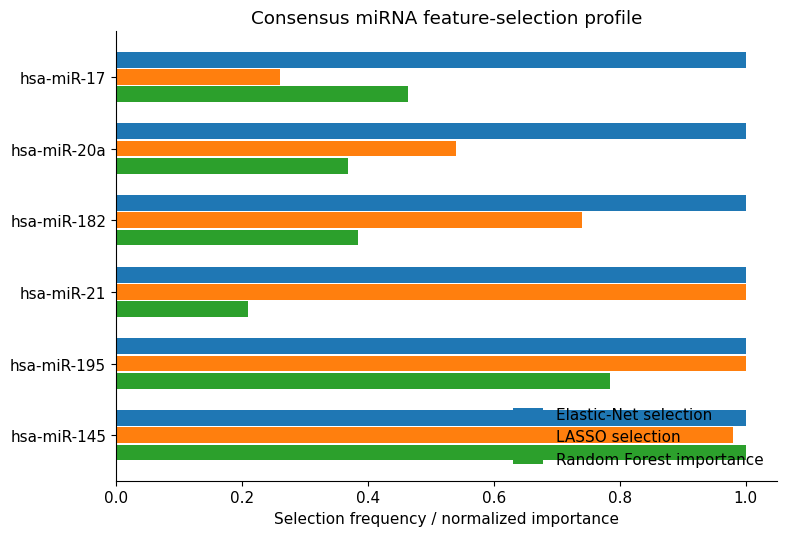


Saved:
figures/Fig7_miRNA_feature_selection.png


In [ ]:
# ============================================================
# 17.8 — Coefficient / importance figure
# ============================================================

import matplotlib.pyplot as plt

print("Creating final miRNA coefficient/importance figure...")

plot_df = comparison[
    comparison["miRNA"].isin(final_miRNA_signature)
].copy()

# Sort by consensus rank
plot_df = plot_df.sort_values(
    "Consensus_rank",
    ascending=True
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

y_pos = np.arange(len(plot_df))

# Normalised RF importance
rf_norm = (
    plot_df["RF_mean_importance"]
    /
    comparison["RF_mean_importance"].max()
)

# Plot three signals
ax.barh(
    y_pos + 0.24,
    plot_df["ElasticNet_selection_frequency"] / 100,
    height=0.22,
    label="Elastic-Net selection"
)

ax.barh(
    y_pos,
    plot_df["LASSO_selection_frequency"] / 100,
    height=0.22,
    label="LASSO selection"
)

ax.barh(
    y_pos - 0.24,
    rf_norm,
    height=0.22,
    label="Random Forest importance"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["miRNA"])

ax.set_xlabel("Selection frequency / normalized importance")
ax.set_title(
    "Consensus miRNA feature-selection profile"
)

ax.set_xlim(0, 1.05)
ax.legend(
    frameon=False,
    loc="lower right"
)

plt.tight_layout()

os.makedirs("figures", exist_ok=True)

plt.savefig(
    "figures/Fig7_miRNA_feature_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print("figures/Fig7_miRNA_feature_selection.png")

In [ ]:
# ============================================================
# 17.9 — Final miRNA table
# ============================================================

print("Creating final miRNA table...")

final_table = comparison[
    comparison["miRNA"].isin(final_miRNA_signature)
].copy()

# Final ordering
final_table = final_table.sort_values(
    "Consensus_rank"
).reset_index(drop=True)

final_table["Final_Rank"] = np.arange(
    1,
    len(final_table) + 1
)

# ------------------------------------------------------------
# Add expression statistics from original miRNA results
# ------------------------------------------------------------

if "mir_res" in globals():

    expr_stats = mir_res.copy()

    # Handle the original result structure
    if "sym" in expr_stats.columns:
        expr_stats = expr_stats.set_index("sym")

    wanted_cols = [
        c for c in
        ["log2FC", "pval", "padj", "mean_expr"]
        if c in expr_stats.columns
    ]

    if wanted_cols:
        expr_stats = expr_stats[wanted_cols]

        final_table = final_table.merge(
            expr_stats,
            left_on="miRNA",
            right_index=True,
            how="left"
        )

# ------------------------------------------------------------
# Select clean columns
# ------------------------------------------------------------

preferred_columns = [
    "Final_Rank",
    "miRNA",
    "Consensus_rank",
    "Consensus_score",
    "methods_supporting",
    "ElasticNet_selection_frequency",
    "LASSO_selection_frequency",
    "RF_mean_importance",
    "RF_rank",
    "log2FC",
    "pval",
    "padj",
    "mean_expr"
]

final_columns = [
    c for c in preferred_columns
    if c in final_table.columns
]

final_table = final_table[final_columns]

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_table.to_csv(
    "tables/FINAL_miRNA_candidate_panel.csv",
    index=False
)

print("\n============================================================")
print("FINAL miRNA CANDIDATE TABLE")
print("============================================================")

display(final_table)

print("\nSaved:")
print("tables/FINAL_miRNA_candidate_panel.csv")

Creating final miRNA table...

FINAL miRNA CANDIDATE TABLE


,Final_Rank,miRNA,Consensus_rank,Consensus_score,methods_supporting,ElasticNet_selection_frequency,LASSO_selection_frequency,RF_mean_importance,RF_rank,log2FC,pval,padj,mean_expr
0,1,hsa-miR-145,1,0.993333,3,100.0,98.0,0.283555,1.0,-1.921827,1.921518e-16,1.627526e-13,11.431886
1,2,hsa-miR-195,2,0.928093,3,100.0,100.0,0.222386,2.0,-2.112809,1.414519e-14,5.990486e-12,8.495827
2,3,hsa-miR-21,3,0.736708,2,100.0,100.0,0.059582,6.0,1.924860,4.822430e-05,8.169196e-04,7.116216
3,4,hsa-miR-182,4,0.708087,3,100.0,74.0,0.108959,4.0,2.202460,9.238248e-09,6.520663e-07,7.991950
4,5,hsa-miR-20a,5,0.636285,3,100.0,54.0,0.104590,5.0,1.115308,4.753481e-07,1.266956e-05,10.889403
5,6,hsa-miR-17,6,0.574722,2,100.0,26.0,0.131617,3.0,1.094508,7.052894e-08,2.844667e-06,11.469249



Saved:
tables/FINAL_miRNA_candidate_panel.csv


In [ ]:
# ============================================================
# 17.10 — ZIP download of Section 17 outputs
# ============================================================

import os
import shutil
from google.colab import files

print("Preparing Section 17 ZIP package...")

# ------------------------------------------------------------
# Create dedicated Section 17 folders
# ------------------------------------------------------------

SECTION17_DIR = "section17_miRNA_outputs"
SECTION17_FIG = os.path.join(
    SECTION17_DIR,
    "figures"
)
SECTION17_TAB = os.path.join(
    SECTION17_DIR,
    "tables"
)

os.makedirs(SECTION17_FIG, exist_ok=True)
os.makedirs(SECTION17_TAB, exist_ok=True)

# ------------------------------------------------------------
# Copy Section 17 figures
# ------------------------------------------------------------

figure_files = [
    "figures/Fig7_miRNA_feature_selection.png"
]

for src in figure_files:

    if os.path.exists(src):
        shutil.copy2(
            src,
            SECTION17_FIG
        )

# ------------------------------------------------------------
# Copy Section 17 tables
# ------------------------------------------------------------

table_files = [
    "tables/miRNA_regularization_selection.csv",
    "tables/miRNA_random_forest_importance.csv",
    "tables/miRNA_method_comparison.csv",
    "tables/final_miRNA_signature.csv",
    "tables/final_miRNA_list.csv",
    "tables/FINAL_miRNA_candidate_panel.csv"
]

for src in table_files:

    if os.path.exists(src):
        shutil.copy2(
            src,
            SECTION17_TAB
        )

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------

zip_name = "Section17_miRNA_outputs"

shutil.make_archive(
    zip_name,
    "zip",
    SECTION17_DIR
)

zip_file = zip_name + ".zip"

print("\n============================================================")
print("SECTION 17 PACKAGE READY")
print("============================================================")

print("ZIP:", zip_file)

print("\nContents:")

for root, dirs, fs in os.walk(SECTION17_DIR):
    for f in fs:
        print(
            os.path.relpath(
                os.path.join(root, f),
                SECTION17_DIR
            )
        )

# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

files.download(zip_file)

Preparing Section 17 ZIP package...

SECTION 17 PACKAGE READY
ZIP: Section17_miRNA_outputs.zip

Contents:
tables/miRNA_regularization_selection.csv
tables/miRNA_method_comparison.csv
tables/FINAL_miRNA_candidate_panel.csv
tables/final_miRNA_signature.csv
tables/final_miRNA_list.csv
tables/miRNA_random_forest_importance.csv
figures/Fig7_miRNA_feature_selection.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# 17.10 — ZIP DOWNLOAD: FINAL miRNA OUTPUTS
# ============================================================

import os
import shutil
from google.colab import files

# Create output directory
MIRNA_OUT = "/content/poster_outputs/mirna_section"

os.makedirs(MIRNA_OUT, exist_ok=True)

# Copy expected Section 17 outputs if they exist
objects_to_save = [
    "mirna_cohort.csv",
    "mirna_selected_features.csv",
    "mirna_feature_importance.csv",
    "final_mirna_signature.csv",
    "final_mirna_table.csv",
    "mirna_coefficients.csv",
    "mirna_importance.csv",
    "mirna_coefficient_importance.png",
    "mirna_selection_plot.png",
]

# Search common output locations
search_dirs = [
    "/content/poster_outputs",
    "/content/poster_outputs/figures",
    "/content/poster_outputs/tables",
    "/content/tables",
    "/content/figures"
]

copied = []

for filename in objects_to_save:
    found = False

    for folder in search_dirs:
        source = os.path.join(folder, filename)

        if os.path.exists(source):
            destination = os.path.join(MIRNA_OUT, filename)

            # Avoid copying onto itself
            if os.path.abspath(source) != os.path.abspath(destination):
                shutil.copy2(source, destination)

            copied.append(filename)
            found = True
            break

    if not found:
        print("Not found:", filename)

# Also save any Section-17-specific files already present
for folder in search_dirs:
    if os.path.exists(folder):
        for filename in os.listdir(folder):

            lower = filename.lower()

            if "mirna" in lower or "mir-" in lower or "mir_" in lower:
                source = os.path.join(folder, filename)
                destination = os.path.join(MIRNA_OUT, filename)

                if os.path.isfile(source) and \
                   os.path.abspath(source) != os.path.abspath(destination):

                    if not os.path.exists(destination):
                        shutil.copy2(source, destination)
                        copied.append(filename)

print("\nFiles included in Section 17 package:")
for f in sorted(set(copied)):
    print("✓", f)

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------

zip_base = "/content/Section_17_miRNA_outputs"
zip_file = shutil.make_archive(
    zip_base,
    "zip",
    MIRNA_OUT
)

print("\n============================================")
print("Section 17 ZIP created successfully.")
print("Location:", zip_file)
print("============================================")

# Download to your computer
files.download(zip_file)

Not found: mirna_cohort.csv
Not found: mirna_selected_features.csv
Not found: mirna_feature_importance.csv
Not found: final_mirna_signature.csv
Not found: final_mirna_table.csv
Not found: mirna_coefficients.csv
Not found: mirna_importance.csv
Not found: mirna_coefficient_importance.png
Not found: mirna_selection_plot.png

Files included in Section 17 package:
✓ DEmiRNA_results.csv
✓ FINAL_miRNA_candidate_panel.csv
✓ Fig2a_PCA_miRNA.png
✓ Fig2b_volcano_miRNA.png
✓ Fig3_miRNA_mRNA_network.png
✓ Fig7_miRNA_feature_selection.png
✓ final_miRNA_list.csv
✓ final_miRNA_signature.csv
✓ miRNA_mRNA_edges.csv
✓ miRNA_method_comparison.csv
✓ miRNA_random_forest_importance.csv
✓ miRNA_regularization_selection.csv

Section 17 ZIP created successfully.
Location: /content/Section_17_miRNA_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***18. NMF tumor subtype analysis***

In [ ]:
# ============================================================
# 18.1 — CHECK OBJECTS FOR NMF TUMOR SUBTYPE ANALYSIS
# ============================================================

print("=" * 65)
print("SECTION 18 — NMF TUMOR SUBTYPE ANALYSIS")
print("=" * 65)

required_objects = [
    "gene_expr",
    "grp_m",
    "network_genes"
]

for obj in required_objects:

    if obj not in globals():
        print(f"✗ {obj}: MISSING")

    else:

        value = globals()[obj]

        if hasattr(value, "shape"):
            print(
                f"✓ {obj}: "
                f"type={type(value).__name__}, "
                f"shape={value.shape}"
            )

        elif hasattr(value, "__len__"):
            print(
                f"✓ {obj}: "
                f"type={type(value).__name__}, "
                f"length={len(value)}"
            )

        else:
            print(
                f"✓ {obj}: "
                f"type={type(value).__name__}"
            )

print("\n18.1 check completed.")

SECTION 18 — NMF TUMOR SUBTYPE ANALYSIS
✓ gene_expr: type=DataFrame, shape=(19468, 246)
✓ grp_m: type=Series, shape=(246,)
✓ network_genes: type=list, length=127

18.1 check completed.


In [ ]:
# ============================================================
# 18.2 — PREPARE TUMOR EXPRESSION MATRIX FOR NMF
# ============================================================

import os
import numpy as np
import pandas as pd

print("Preparing tumor expression matrix...")

# ------------------------------------------------------------
# Check required objects
# ------------------------------------------------------------

if "gene_expr" not in globals():
    raise RuntimeError("gene_expr is not available.")

if "grp_m" not in globals():
    raise RuntimeError("grp_m is not available.")

if "network_genes" not in globals():
    raise RuntimeError("network_genes is not available.")

# ------------------------------------------------------------
# Tumor samples only
# ------------------------------------------------------------

tumor_samples = grp_m[
    grp_m == "Tumor"
].index

if len(tumor_samples) < 10:
    raise RuntimeError(
        f"Only {len(tumor_samples)} tumor samples found. "
        "Too few for reliable subtype analysis."
    )

# ------------------------------------------------------------
# Network genes present in expression matrix
# ------------------------------------------------------------

nmf_genes = [
    str(g)
    for g in network_genes
    if str(g) in gene_expr.index
]

if len(nmf_genes) < 5:
    raise RuntimeError(
        f"Only {len(nmf_genes)} network genes were found "
        "in gene_expr."
    )

# ------------------------------------------------------------
# Tumor × gene matrix
# ------------------------------------------------------------

tumor_expr = (
    gene_expr
    .loc[nmf_genes, tumor_samples]
    .T
    .copy()
)

tumor_expr = tumor_expr.apply(
    pd.to_numeric,
    errors="coerce"
)

tumor_expr = tumor_expr.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove genes with excessive missingness
missing_fraction = tumor_expr.isna().mean()

tumor_expr = tumor_expr.loc[
    :,
    missing_fraction <= 0.20
]

# Median imputation
tumor_expr = tumor_expr.fillna(
    tumor_expr.median()
)

# Remove zero-variance genes
gene_sd = tumor_expr.std(axis=0)

tumor_expr = tumor_expr.loc[
    :,
    gene_sd > 0
]

print("\n============================================================")
print("Tumor NMF matrix prepared")
print("============================================================")

print("Tumor samples:", tumor_expr.shape[0])
print("Genes:", tumor_expr.shape[1])

print("\nMatrix shape:")
print(tumor_expr.shape)

print("\n✓ Tumor-only matrix ready for NMF.")

Preparing tumor expression matrix...

Tumor NMF matrix prepared
Tumor samples: 98
Genes: 127

Matrix shape:
(98, 127)

✓ Tumor-only matrix ready for NMF.


In [ ]:
# ============================================================
# 18.3 — PREPARE NON-NEGATIVE MATRIX FOR NMF
# ============================================================

print("Preparing non-negative matrix for NMF...")

# ------------------------------------------------------------
# Gene-wise min-max scaling
# ------------------------------------------------------------

nmf_matrix = tumor_expr.copy()

for gene in nmf_matrix.columns:

    col = nmf_matrix[gene]

    minimum = col.min()
    maximum = col.max()

    if maximum > minimum:

        nmf_matrix[gene] = (
            (col - minimum)
            /
            (maximum - minimum)
        )

    else:

        nmf_matrix[gene] = 0.0

# Numerical cleanup
nmf_matrix = nmf_matrix.clip(
    lower=0
)

print("Minimum value:", nmf_matrix.min().min())
print("Maximum value:", nmf_matrix.max().max())

print("\nMatrix shape:", nmf_matrix.shape)

print("\n✓ NMF-compatible non-negative matrix created.")

Preparing non-negative matrix for NMF...
Minimum value: 0.0
Maximum value: 1.0

Matrix shape: (98, 127)

✓ NMF-compatible non-negative matrix created.


In [ ]:
# ============================================================
# 18.4 — TEST NMF CLUSTER NUMBERS
# ============================================================

from sklearn.decomposition import NMF
from sklearn.metrics import silhouette_score

print("Testing NMF cluster numbers...")

K_VALUES = [2, 3, 4, 5, 6]

nmf_results = []

X_nmf = nmf_matrix.values

for k in K_VALUES:

    print(f"Running NMF with k={k}...")

    nmf_model = NMF(
        n_components=k,
        init="nndsvda",
        random_state=42,
        max_iter=3000,
        tol=1e-4
    )

    W = nmf_model.fit_transform(X_nmf)

    # Cluster assignment
    labels = np.argmax(W, axis=1)

    # Reconstruction error
    reconstruction_error = nmf_model.reconstruction_err_

    # Silhouette score
    if len(np.unique(labels)) > 1:

        silhouette = silhouette_score(
            W,
            labels
        )

    else:

        silhouette = np.nan

    nmf_results.append({
        "k": k,
        "reconstruction_error": reconstruction_error,
        "silhouette_score": silhouette
    })

nmf_results = pd.DataFrame(
    nmf_results
)

display(nmf_results)

print("\n✓ NMF k-comparison completed.")

Testing NMF cluster numbers...
Running NMF with k=2...
Running NMF with k=3...
Running NMF with k=4...
Running NMF with k=5...
Running NMF with k=6...


,k,reconstruction_error,silhouette_score
0,2,19.495752,0.534715
1,3,18.193218,0.308671
2,4,17.416826,0.272746
3,5,16.781534,0.141788
4,6,16.172944,0.222202



✓ NMF k-comparison completed.


Creating NMF cluster-selection figure...


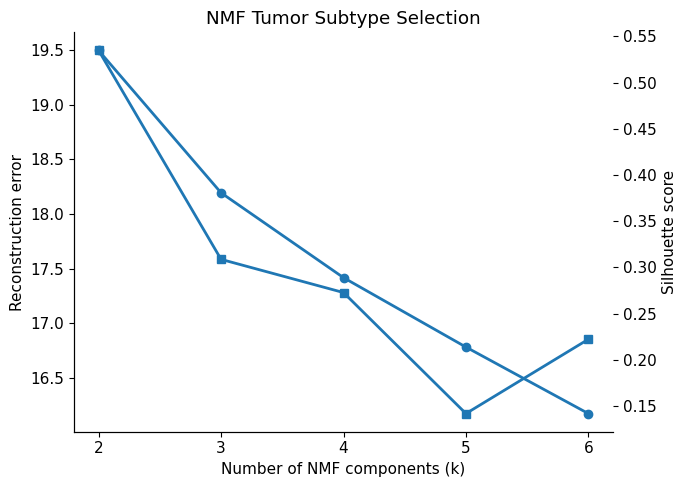


Saved:
/content/poster_outputs/figures/Fig_NMF_k_selection.png


In [ ]:
# ============================================================
# 18.5 — NMF CLUSTER SELECTION FIGURE
# ============================================================

import matplotlib.pyplot as plt

print("Creating NMF cluster-selection figure...")

os.makedirs(
    "/content/poster_outputs/figures",
    exist_ok=True
)

fig, ax1 = plt.subplots(
    figsize=(7, 5)
)

# Reconstruction error
ax1.plot(
    nmf_results["k"],
    nmf_results["reconstruction_error"],
    marker="o",
    linewidth=2,
    label="Reconstruction error"
)

ax1.set_xlabel("Number of NMF components (k)")
ax1.set_ylabel("Reconstruction error")

# Silhouette on second axis
ax2 = ax1.twinx()

ax2.plot(
    nmf_results["k"],
    nmf_results["silhouette_score"],
    marker="s",
    linewidth=2,
    label="Silhouette score"
)

ax2.set_ylabel("Silhouette score")

ax1.set_xticks(K_VALUES)

plt.title(
    "NMF Tumor Subtype Selection"
)

fig.tight_layout()

nmf_k_plot = (
    "/content/poster_outputs/figures/"
    "Fig_NMF_k_selection.png"
)

plt.savefig(
    nmf_k_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(nmf_k_plot)

In [ ]:
# ============================================================
# 18.6 — SELECT FINAL NMF SOLUTION
# ============================================================

print("Selecting final NMF solution...")

best_row = nmf_results.loc[
    nmf_results["silhouette_score"].idxmax()
]

BEST_K = int(
    best_row["k"]
)

print("Selected k:", BEST_K)
print(
    "Silhouette score:",
    round(best_row["silhouette_score"], 4)
)
print(
    "Reconstruction error:",
    round(best_row["reconstruction_error"], 4)
)

# ------------------------------------------------------------
# Fit final model
# ------------------------------------------------------------

final_nmf_model = NMF(
    n_components=BEST_K,
    init="nndsvda",
    random_state=42,
    max_iter=5000,
    tol=1e-4
)

W_final = final_nmf_model.fit_transform(
    X_nmf
)

H_final = final_nmf_model.components_

# ------------------------------------------------------------
# Assign subtype
# ------------------------------------------------------------

nmf_subtype = pd.Series(
    np.argmax(W_final, axis=1) + 1,
    index=nmf_matrix.index,
    name="NMF_Subtype"
)

print("\nTumor subtype distribution:")

print(
    nmf_subtype.value_counts()
    .sort_index()
)

print("\n✓ Final NMF model fitted.")

Selecting final NMF solution...
Selected k: 2
Silhouette score: 0.5347
Reconstruction error: 19.4958

Tumor subtype distribution:
NMF_Subtype
1    21
2    77
Name: count, dtype: int64

✓ Final NMF model fitted.


In [ ]:
# ============================================================
# 18.7 — FINAL NMF TUMOR SUBTYPE TABLE
# ============================================================

print("Creating final tumor subtype table...")

nmf_subtype_table = pd.DataFrame({
    "Sample": nmf_subtype.index,
    "NMF_Subtype": nmf_subtype.values
})

# Add original sample metadata if available
if "meta_m" in globals():

    meta_columns = [
        c for c in meta_m.columns
        if c != "text"
    ]

    if len(meta_columns) > 0:

        meta_subset = meta_m.loc[
            meta_m.index.intersection(
                nmf_subtype.index
            ),
            meta_columns
        ].copy()

        meta_subset.index.name = "Sample"

        nmf_subtype_table = (
            nmf_subtype_table
            .set_index("Sample")
            .join(meta_subset, how="left")
            .reset_index()
        )

display(
    nmf_subtype_table.head(15)
)

# Save
os.makedirs(
    "/content/poster_outputs/tables",
    exist_ok=True
)

nmf_subtype_table.to_csv(
    "/content/poster_outputs/tables/"
    "Table_NMF_tumor_subtypes.csv",
    index=False
)

print("\nSaved:")
print(
    "/content/poster_outputs/tables/"
    "Table_NMF_tumor_subtypes.csv"
)

Creating final tumor subtype table...


,Sample,NMF_Subtype
0,GSM1077746,1
1,GSM1077747,2
2,GSM1077748,2
3,GSM1077749,2
4,GSM1077750,2
5,GSM1077751,1
6,GSM1077752,2
7,GSM1077753,2
8,GSM1077754,2
9,GSM1077755,2



Saved:
/content/poster_outputs/tables/Table_NMF_tumor_subtypes.csv


Creating NMF subtype heatmap...


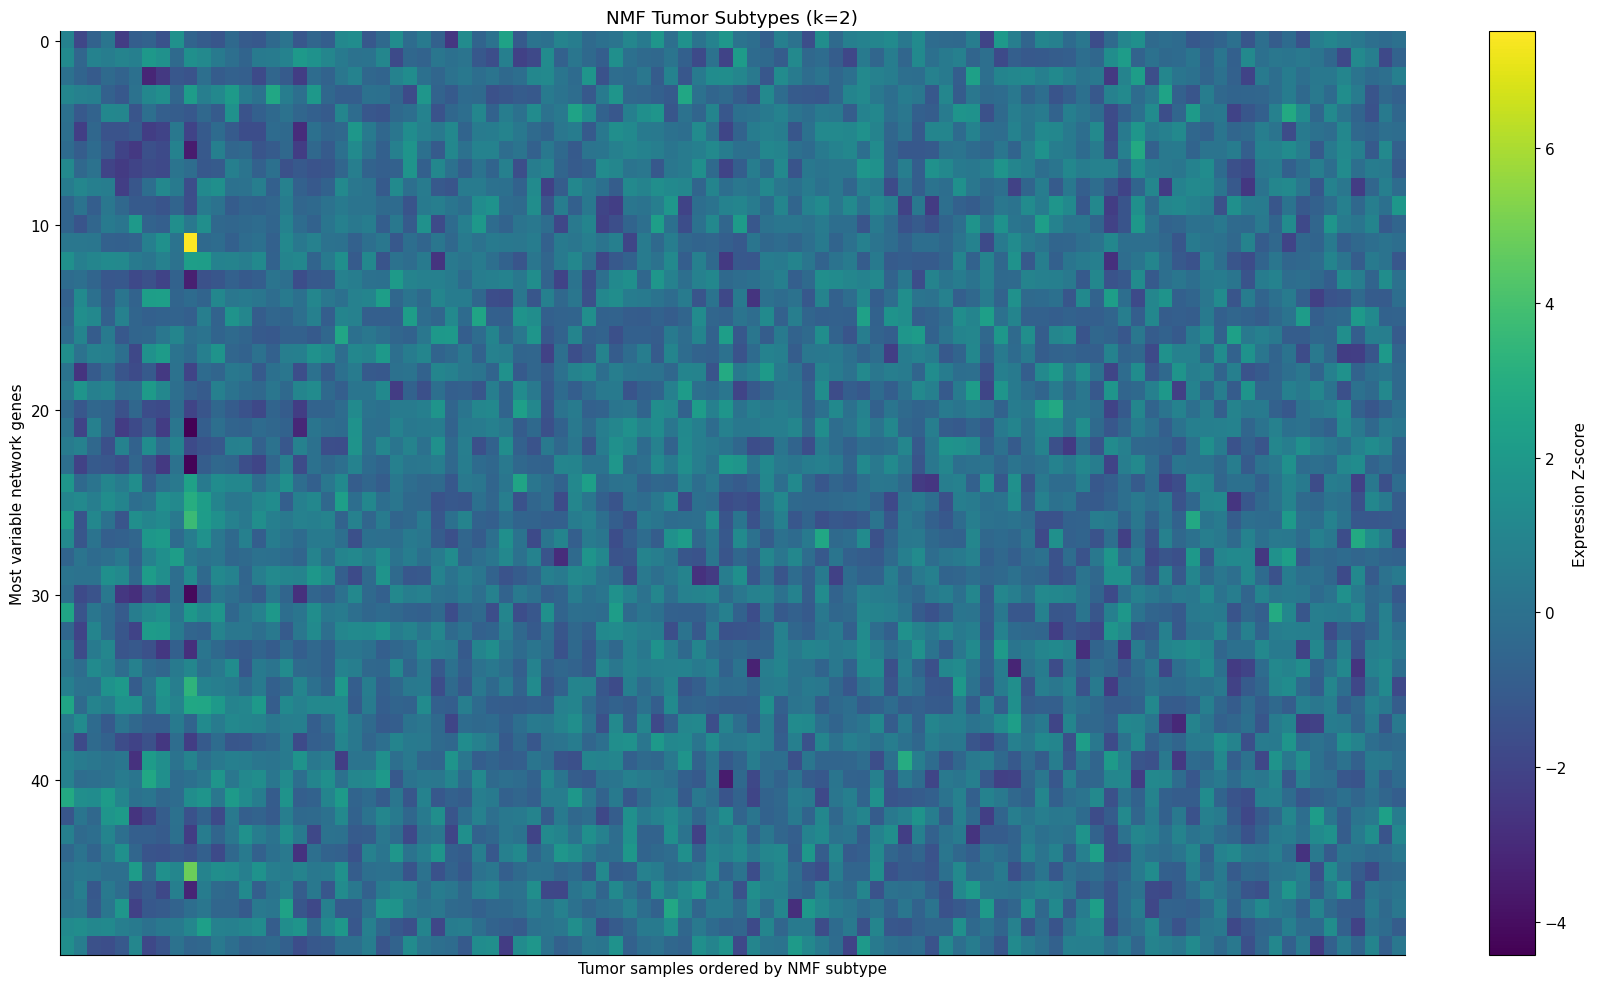


Saved:
/content/poster_outputs/figures/Fig_NMF_tumor_subtype_heatmap.png


In [ ]:
# ============================================================
# 18.8 — NMF TUMOR SUBTYPE HEATMAP
# ============================================================

print("Creating NMF subtype heatmap...")

# ------------------------------------------------------------
# Order samples by subtype
# ------------------------------------------------------------

sample_order = nmf_subtype.sort_values().index

heatmap_data = (
    tumor_expr
    .loc[sample_order]
    .copy()
)

# ------------------------------------------------------------
# Standardise each gene for visualisation
# ------------------------------------------------------------

heatmap_z = (
    heatmap_data
    -
    heatmap_data.mean(axis=0)
) / heatmap_data.std(axis=0)

heatmap_z = heatmap_z.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# Keep the most variable genes for readable plot
gene_variance = heatmap_z.var(
    axis=0
).sort_values(
    ascending=False
)

MAX_HEATMAP_GENES = min(
    50,
    len(gene_variance)
)

heatmap_genes = gene_variance.head(
    MAX_HEATMAP_GENES
).index

heatmap_z = heatmap_z[
    heatmap_genes
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        max(8, heatmap_z.shape[0] * 0.18),
        10
    )
)

im = ax.imshow(
    heatmap_z.T,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xlabel(
    "Tumor samples ordered by NMF subtype"
)

ax.set_ylabel(
    "Most variable network genes"
)

ax.set_title(
    f"NMF Tumor Subtypes (k={BEST_K})"
)

# Avoid overcrowding sample labels
if heatmap_z.shape[0] <= 80:

    ax.set_xticks(
        np.arange(heatmap_z.shape[0])
    )

    ax.set_xticklabels(
        heatmap_z.index,
        rotation=90,
        fontsize=5
    )

else:

    ax.set_xticks([])

plt.colorbar(
    im,
    ax=ax,
    label="Expression Z-score"
)

plt.tight_layout()

nmf_heatmap_path = (
    "/content/poster_outputs/figures/"
    "Fig_NMF_tumor_subtype_heatmap.png"
)

plt.savefig(
    nmf_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(nmf_heatmap_path)

In [ ]:
# ============================================================
# 18.9 — NMF COMPONENT GENE LOADINGS
# ============================================================

print("Creating NMF gene-loading table...")

component_loading = pd.DataFrame(
    H_final,
    index=[
        f"Subtype_{i+1}"
        for i in range(BEST_K)
    ],
    columns=nmf_matrix.columns
)

loading_rows = []

TOP_GENES_PER_SUBTYPE = min(
    20,
    component_loading.shape[1]
)

for subtype in component_loading.index:

    top_genes = (
        component_loading
        .loc[subtype]
        .sort_values(
            ascending=False
        )
        .head(TOP_GENES_PER_SUBTYPE)
    )

    for rank, (gene, loading) in enumerate(
        top_genes.items(),
        start=1
    ):

        loading_rows.append({
            "Subtype": subtype,
            "Rank": rank,
            "Gene": gene,
            "NMF_loading": loading
        })

nmf_gene_loadings = pd.DataFrame(
    loading_rows
)

display(
    nmf_gene_loadings.head(30)
)

nmf_gene_loadings.to_csv(
    "/content/poster_outputs/tables/"
    "Table_NMF_gene_loadings.csv",
    index=False
)

print("\nSaved:")
print(
    "/content/poster_outputs/tables/"
    "Table_NMF_gene_loadings.csv"
)

Creating NMF gene-loading table...


,Subtype,Rank,Gene,NMF_loading
0,Subtype_1,1,THBS2,1.083913
1,Subtype_1,2,MMP14,0.985836
2,Subtype_1,3,MEF2C,0.964441
3,Subtype_1,4,MMP11,0.953155
4,Subtype_1,5,TCF21,0.927208
5,Subtype_1,6,COL1A1,0.918546
6,Subtype_1,7,SFRP2,0.916057
7,Subtype_1,8,TP53INP1,0.915788
8,Subtype_1,9,RNASEL,0.914599
9,Subtype_1,10,COL4A2,0.914047



Saved:
/content/poster_outputs/tables/Table_NMF_gene_loadings.csv


Creating NMF subtype-size figure...


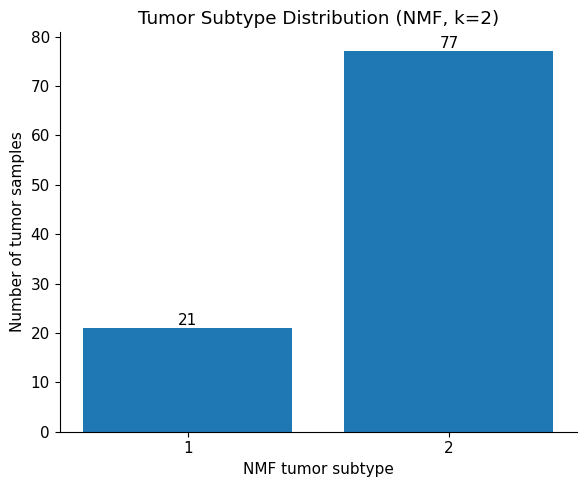


Saved:
/content/poster_outputs/figures/Fig_NMF_subtype_distribution.png


In [ ]:
# ============================================================
# 18.10 — NMF SUBTYPE SIZE FIGURE
# ============================================================

print("Creating NMF subtype-size figure...")

subtype_counts = (
    nmf_subtype
    .value_counts()
    .sort_index()
)

plt.figure(
    figsize=(6, 5)
)

plt.bar(
    subtype_counts.index.astype(str),
    subtype_counts.values
)

plt.xlabel("NMF tumor subtype")
plt.ylabel("Number of tumor samples")

plt.title(
    f"Tumor Subtype Distribution (NMF, k={BEST_K})"
)

for i, value in enumerate(
    subtype_counts.values
):

    plt.text(
        i,
        value,
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

subtype_size_path = (
    "/content/poster_outputs/figures/"
    "Fig_NMF_subtype_distribution.png"
)

plt.savefig(
    subtype_size_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(subtype_size_path)

In [ ]:
# ============================================================
# 18.11 — SAVE NMF MODEL SUMMARY
# ============================================================

print("Saving NMF summary...")

nmf_summary = pd.DataFrame({
    "Metric": [
        "Tumor samples",
        "Input genes",
        "Selected k",
        "Silhouette score",
        "Reconstruction error"
    ],
    "Value": [
        tumor_expr.shape[0],
        tumor_expr.shape[1],
        BEST_K,
        best_row["silhouette_score"],
        best_row["reconstruction_error"]
    ]
})

display(nmf_summary)

nmf_summary.to_csv(
    "/content/poster_outputs/tables/"
    "Table_NMF_summary.csv",
    index=False
)

# Save the complete NMF sample/component matrix
nmf_component_scores = pd.DataFrame(
    W_final,
    index=nmf_matrix.index,
    columns=[
        f"Subtype_{i+1}"
        for i in range(BEST_K)
    ]
)

nmf_component_scores.index.name = "Sample"

nmf_component_scores.to_csv(
    "/content/poster_outputs/tables/"
    "Table_NMF_component_scores.csv"
)

print("\nSaved:")
print(
    "/content/poster_outputs/tables/"
    "Table_NMF_summary.csv"
)

print(
    "/content/poster_outputs/tables/"
    "Table_NMF_component_scores.csv"
)

Saving NMF summary...


,Metric,Value
0,Tumor samples,98.000000
1,Input genes,127.000000
2,Selected k,2.000000
3,Silhouette score,0.534715
4,Reconstruction error,19.495752



Saved:
/content/poster_outputs/tables/Table_NMF_summary.csv
/content/poster_outputs/tables/Table_NMF_component_scores.csv


In [ ]:
# ============================================================
# 18.12 — ZIP SECTION 18 OUTPUTS FOR LOCAL DOWNLOAD
# ============================================================

import os
import shutil
from google.colab import files

print("Preparing Section 18 ZIP package...")

SECTION18_DIR = (
    "/content/section18_NMF_outputs"
)

SECTION18_FIG = os.path.join(
    SECTION18_DIR,
    "figures"
)

SECTION18_TAB = os.path.join(
    SECTION18_DIR,
    "tables"
)

os.makedirs(
    SECTION18_FIG,
    exist_ok=True
)

os.makedirs(
    SECTION18_TAB,
    exist_ok=True
)

# ------------------------------------------------------------
# Figures
# ------------------------------------------------------------

figure_files = [
    "/content/poster_outputs/figures/"
    "Fig_NMF_k_selection.png",

    "/content/poster_outputs/figures/"
    "Fig_NMF_tumor_subtype_heatmap.png",

    "/content/poster_outputs/figures/"
    "Fig_NMF_subtype_distribution.png"
]

for source in figure_files:

    if os.path.exists(source):

        shutil.copy2(
            source,
            SECTION18_FIG
        )

        print(
            "✓ Figure:",
            os.path.basename(source)
        )

    else:

        print(
            "⚠ Figure not found:",
            source
        )

# ------------------------------------------------------------
# Tables
# ------------------------------------------------------------

table_files = [
    "/content/poster_outputs/tables/"
    "Table_NMF_tumor_subtypes.csv",

    "/content/poster_outputs/tables/"
    "Table_NMF_gene_loadings.csv",

    "/content/poster_outputs/tables/"
    "Table_NMF_summary.csv",

    "/content/poster_outputs/tables/"
    "Table_NMF_component_scores.csv"
]

for source in table_files:

    if os.path.exists(source):

        shutil.copy2(
            source,
            SECTION18_TAB
        )

        print(
            "✓ Table:",
            os.path.basename(source)
        )

    else:

        print(
            "⚠ Table not found:",
            source
        )

# ------------------------------------------------------------
# ZIP
# ------------------------------------------------------------

ZIP_BASE = (
    "/content/Section_18_NMF_outputs"
)

old_zip = ZIP_BASE + ".zip"

if os.path.exists(old_zip):
    os.remove(old_zip)

zip_file = shutil.make_archive(
    ZIP_BASE,
    "zip",
    SECTION18_DIR
)

print("\n" + "=" * 65)
print("✓ SECTION 18 ZIP CREATED")
print("=" * 65)

print("\nZIP file:")
print(zip_file)

# Show contents
print("\nContents:")

for root, dirs, filenames in os.walk(
    SECTION18_DIR
):

    for filename in filenames:

        print(
            os.path.relpath(
                os.path.join(root, filename),
                SECTION18_DIR
            )
        )

# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

files.download(zip_file)

Preparing Section 18 ZIP package...
✓ Figure: Fig_NMF_k_selection.png
✓ Figure: Fig_NMF_tumor_subtype_heatmap.png
✓ Figure: Fig_NMF_subtype_distribution.png
✓ Table: Table_NMF_tumor_subtypes.csv
✓ Table: Table_NMF_gene_loadings.csv
✓ Table: Table_NMF_summary.csv
✓ Table: Table_NMF_component_scores.csv

✓ SECTION 18 ZIP CREATED

ZIP file:
/content/Section_18_NMF_outputs.zip

Contents:
tables/Table_NMF_summary.csv
tables/Table_NMF_component_scores.csv
tables/Table_NMF_tumor_subtypes.csv
tables/Table_NMF_gene_loadings.csv
figures/Fig_NMF_k_selection.png
figures/Fig_NMF_tumor_subtype_heatmap.png
figures/Fig_NMF_subtype_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***19. LASSO-Cox survival analysis***

In [ ]:
# ============================================================
# 19.1 — CHECK AVAILABLE SURVIVAL DATA
# ============================================================

print("=" * 70)
print("SECTION 19 — LASSO-COX SURVIVAL ANALYSIS")
print("=" * 70)

print("\nSearching current Colab environment for survival-related objects...\n")

# ------------------------------------------------------------
# Search object names
# ------------------------------------------------------------

all_objects = sorted(globals().keys())

survival_keywords = [
    "surv",
    "survival",
    "os",
    "overall",
    "event",
    "status",
    "time",
    "days",
    "months"
]

survival_objects = []

for obj in all_objects:

    obj_lower = obj.lower()

    if any(
        keyword in obj_lower
        for keyword in survival_keywords
    ):
        survival_objects.append(obj)

if survival_objects:

    print("Potential survival-related objects:\n")

    for obj in survival_objects:

        value = globals()[obj]

        if isinstance(value, pd.DataFrame):

            print(
                f"✓ {obj:<35} "
                f"DataFrame "
                f"shape={value.shape}"
            )

            print(
                "   Columns:",
                list(value.columns[:15])
            )

        elif isinstance(value, pd.Series):

            print(
                f"✓ {obj:<35} "
                f"Series "
                f"length={len(value)}"
            )

        elif isinstance(value, (list, tuple, np.ndarray)):

            print(
                f"✓ {obj:<35} "
                f"{type(value).__name__} "
                f"length={len(value)}"
            )

        else:

            print(
                f"✓ {obj:<35} "
                f"type={type(value).__name__}"
            )

else:

    print(
        "⚠ No obvious survival-related objects "
        "were found."
    )


# ------------------------------------------------------------
# Inspect all DataFrames for survival columns
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SEARCHING DATAFRAMES FOR SURVIVAL COLUMNS")
print("-" * 70)

survival_column_keywords = [
    "os",
    "overall_survival",
    "survival",
    "surv_time",
    "time",
    "days",
    "months",
    "event",
    "status",
    "death",
    "dead",
    "censor"
]

found_dataframe_candidates = []

for obj in all_objects:

    try:

        value = globals()[obj]

        if not isinstance(value, pd.DataFrame):
            continue

        matching_columns = []

        for col in value.columns:

            col_lower = str(col).lower()

            if any(
                keyword in col_lower
                for keyword in survival_column_keywords
            ):

                matching_columns.append(str(col))

        if matching_columns:

            found_dataframe_candidates.append(obj)

            print(
                f"\n✓ {obj}"
            )

            print(
                "Shape:",
                value.shape
            )

            print(
                "Potential survival columns:",
                matching_columns
            )

    except Exception:

        pass


print("\n" + "=" * 70)
print("19.1 CHECK COMPLETED")
print("=" * 70)

print(
    "\nIMPORTANT:"
    "\nDo not run 19.2 yet."
    "\nIf survival data are found, we will use those exact objects."
    "\nIf they are not found, we need to import GSE39582 survival data "
    "before continuing."
)

SECTION 19 — LASSO-COX SURVIVAL ANALYSIS

Searching current Colab environment for survival-related objects...

Potential survival-related objects:

✓ os                                  type=module
✓ pos                                 type=dict
✓ y_pos                               ndarray length=6

----------------------------------------------------------------------
SEARCHING DATAFRAMES FOR SURVIVAL COLUMNS
----------------------------------------------------------------------

✓ X
Shape: (246, 127)
Potential survival columns: ['FOSL1']

✓ X_scaled
Shape: (246, 127)
Potential survival columns: ['FOSL1']

✓ X_test
Shape: (62, 127)
Potential survival columns: ['FOSL1']

✓ component_loading
Shape: (2, 127)
Potential survival columns: ['FOSL1']

✓ gpl_m
Shape: (49386, 43)
Potential survival columns: ['Chromosomal Location']

✓ heatmap_data
Shape: (98, 127)
Potential survival columns: ['FOSL1']

✓ heatmap_z
Shape: (98, 50)
Potential survival columns: ['FOSL1']

✓ nmf_matrix
Shape: (98, 

In [ ]:
# ============================================================
# 19.2 — DOWNLOAD AND IMPORT GSE39582
# ============================================================

import os
import gzip
import shutil
import urllib.request
import pandas as pd
import numpy as np

print("=" * 70)
print("19.2 — IMPORTING GSE39582")
print("=" * 70)

# ------------------------------------------------------------
# URLs
# ------------------------------------------------------------

GSE39582_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE39nnn/GSE39582/matrix/"
    "GSE39582_series_matrix.txt.gz"
)

GSE39582_GZ = (
    "/content/GSE39582_series_matrix.txt.gz"
)

GSE39582_TXT = (
    "/content/GSE39582_series_matrix.txt"
)

# ------------------------------------------------------------
# Download
# ------------------------------------------------------------

if not os.path.exists(GSE39582_GZ):

    print("\nDownloading GSE39582 series matrix...")
    print("This may take a few minutes.")

    urllib.request.urlretrieve(
        GSE39582_URL,
        GSE39582_GZ
    )

    print("✓ Download completed.")

else:

    print("\n✓ GSE39582 file already exists.")


# ------------------------------------------------------------
# Decompress
# ------------------------------------------------------------

if not os.path.exists(GSE39582_TXT):

    print("\nDecompressing GSE39582...")

    with gzip.open(
        GSE39582_GZ,
        "rb"
    ) as f_in:

        with open(
            GSE39582_TXT,
            "wb"
        ) as f_out:

            shutil.copyfileobj(
                f_in,
                f_out
            )

    print("✓ Decompression completed.")

else:

    print("\n✓ Decompressed file already exists.")


# ------------------------------------------------------------
# Read the GEO series matrix
# ------------------------------------------------------------

print("\nReading GSE39582 series matrix...")

with open(
    GSE39582_TXT,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:

    lines = f.readlines()


# ------------------------------------------------------------
# Locate expression table
# ------------------------------------------------------------

table_start = None
table_end = None

for i, line in enumerate(lines):

    if line.startswith(
        "!series_matrix_table_begin"
    ):
        table_start = i + 1

    elif line.startswith(
        "!series_matrix_table_end"
    ):
        table_end = i

        break


if table_start is None or table_end is None:

    raise RuntimeError(
        "Could not locate the expression table "
        "inside the GSE39582 series matrix."
    )


print(
    "\nExpression table lines:",
    table_start,
    "to",
    table_end
)


# ------------------------------------------------------------
# Parse expression matrix
# ------------------------------------------------------------

from io import StringIO

expression_text = "".join(
    lines[table_start:table_end]
)

gse39582_expr = pd.read_csv(
    StringIO(expression_text),
    sep="\t",
    index_col=0
)

# Remove accidental quote characters
gse39582_expr.index = (
    gse39582_expr.index
    .astype(str)
    .str.replace('"', '', regex=False)
)

gse39582_expr.columns = (
    gse39582_expr.columns
    .astype(str)
    .str.replace('"', '', regex=False)
)


# ------------------------------------------------------------
# Numeric conversion
# ------------------------------------------------------------

gse39582_expr = gse39582_expr.apply(
    pd.to_numeric,
    errors="coerce"
)


# ------------------------------------------------------------
# Remove completely empty rows
# ------------------------------------------------------------

gse39582_expr = gse39582_expr.dropna(
    how="all"
)


print("\n" + "=" * 70)
print("GSE39582 EXPRESSION MATRIX LOADED")
print("=" * 70)

print(
    "Expression matrix shape:",
    gse39582_expr.shape
)

print(
    "Number of probes:",
    gse39582_expr.shape[0]
)

print(
    "Number of samples:",
    gse39582_expr.shape[1]
)

print(
    "\nFirst 10 sample IDs:"
)

print(
    gse39582_expr.columns[:10].tolist()
)

print(
    "\nFirst 10 probe IDs:"
)

print(
    gse39582_expr.index[:10].tolist()
)

print(
    "\n✓ GSE39582 expression data imported successfully."
)

print(
    "\nIMPORTANT:"
    "\nDo NOT run 19.3 until you send me this output."
)

19.2 — IMPORTING GSE39582

This may take a few minutes.
✓ Download completed.

Decompressing GSE39582...
✓ Decompression completed.

Reading GSE39582 series matrix...

Expression table lines: 129 to 54805

GSE39582 EXPRESSION MATRIX LOADED
Expression matrix shape: (54675, 585)
Number of probes: 54675
Number of samples: 585

First 10 sample IDs:
['GSM971957', 'GSM971958', 'GSM971959', 'GSM971960', 'GSM971961', 'GSM971962', 'GSM971963', 'GSM971964', 'GSM971965', 'GSM971966']

First 10 probe IDs:
['1007_s_at', '1053_at', '117_at', '121_at', '1255_g_at', '1294_at', '1316_at', '1320_at', '1405_i_at', '1431_at']

✓ GSE39582 expression data imported successfully.

IMPORTANT:
Do NOT run 19.3 until you send me this output.


In [ ]:
# ============================================================
# 19.3 — EXTRACT AND IDENTIFY GSE39582 SURVIVAL METADATA
# ============================================================

import re
import pandas as pd
import numpy as np

print("=" * 70)
print("19.3 — IDENTIFYING GSE39582 SURVIVAL METADATA")
print("=" * 70)

# ------------------------------------------------------------
# Check that the downloaded GEO file exists
# ------------------------------------------------------------

if "lines" not in globals():

    raise RuntimeError(
        "The GSE39582 series-matrix lines are not available. "
        "Please rerun Section 19.2."
    )

# ------------------------------------------------------------
# Extract sample characteristics from GEO metadata
# ------------------------------------------------------------

characteristic_rows = []

for line in lines:

    line = line.rstrip("\n")

    if line.startswith(
        "!Sample_characteristics_ch1"
    ):

        # Remove GEO field name
        content = line.split("\t")

        characteristic_rows.append(
            content
        )

# ------------------------------------------------------------
# Check metadata
# ------------------------------------------------------------

if len(characteristic_rows) == 0:

    raise RuntimeError(
        "No !Sample_characteristics_ch1 metadata were found."
    )

print(
    "\nNumber of characteristic metadata rows:",
    len(characteristic_rows)
)

# ------------------------------------------------------------
# Build metadata table
# ------------------------------------------------------------

metadata_rows = []

for row in characteristic_rows:

    # Remove the GEO field name
    values = row[1:]

    metadata_rows.append(values)

# Transpose:
# rows = samples
# columns = characteristic rows

sample_metadata_raw = pd.DataFrame(
    np.array(metadata_rows, dtype=object).T,
    columns=[
        f"characteristic_{i+1}"
        for i in range(len(metadata_rows))
    ]
)

# Sample IDs should correspond to expression columns
sample_ids = list(
    gse39582_expr.columns
)

if len(sample_metadata_raw) != len(sample_ids):

    print(
        "\n⚠ Metadata/sample count mismatch:"
    )

    print(
        "Expression samples:",
        len(sample_ids)
    )

    print(
        "Metadata samples:",
        len(sample_metadata_raw)
    )

else:

    sample_metadata_raw.index = sample_ids

# ------------------------------------------------------------
# Print all metadata fields
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALL GSE39582 SAMPLE CHARACTERISTICS")
print("=" * 70)

for col in sample_metadata_raw.columns:

    print(
        f"\n[{col}]"
    )

    unique_values = (
        sample_metadata_raw[col]
        .dropna()
        .astype(str)
        .unique()
    )

    for value in unique_values[:20]:

        print(
            "  ",
            value
        )

# ------------------------------------------------------------
# Search for survival-related metadata
# ------------------------------------------------------------

survival_terms = [
    "survival",
    "overall survival",
    "os",
    "death",
    "dead",
    "status",
    "event",
    "censor",
    "follow",
    "follow-up",
    "followup",
    "months",
    "month",
    "days",
    "relapse",
    "recurrence",
    "rfs",
    "disease-free"
]

candidate_columns = []

for col in sample_metadata_raw.columns:

    column_text = (
        sample_metadata_raw[col]
        .astype(str)
        .str.lower()
    )

    combined_text = " ".join(
        column_text.tolist()
    )

    if any(
        term in combined_text
        for term in survival_terms
    ):

        candidate_columns.append(col)

# ------------------------------------------------------------
# Display candidate survival metadata
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("POTENTIAL SURVIVAL-RELATED METADATA")
print("=" * 70)

if len(candidate_columns) == 0:

    print(
        "⚠ No survival-related characteristic field "
        "was automatically identified."
    )

else:

    for col in candidate_columns:

        print(
            f"\n### {col}"
        )

        print(
            sample_metadata_raw[col]
            .dropna()
            .astype(str)
            .value_counts()
            .head(30)
        )

# ------------------------------------------------------------
# Save raw metadata
# ------------------------------------------------------------

import os

os.makedirs(
    "/content/poster_outputs/tables",
    exist_ok=True
)

sample_metadata_raw.to_csv(
    "/content/poster_outputs/tables/"
    "GSE39582_sample_metadata_raw.csv"
)

print("\n" + "=" * 70)
print("19.3 COMPLETED")
print("=" * 70)

print(
    "\nSaved:"
)

print(
    "/content/poster_outputs/tables/"
    "GSE39582_sample_metadata_raw.csv"
)

print(
    "\nIMPORTANT:"
    "\nDo not run 19.4 yet."
    "\nFirst inspect the printed survival-related metadata."
)

19.3 — IDENTIFYING GSE39582 SURVIVAL METADATA

Number of characteristic metadata rows: 33

ALL GSE39582 SAMPLE CHARACTERISTICS

[characteristic_1]
   "organism: Homo sapiens"

[characteristic_2]
   "dataset: discovery"
   "dataset: validation"
   "dataset: Non Tumoral"

[characteristic_3]
   "Sex: Male"
   "Sex: Female"

[characteristic_4]
   "age.at.diagnosis (year): 34.5"
   "age.at.diagnosis (year): 36.4"
   "age.at.diagnosis (year): 36.9"
   "age.at.diagnosis (year): 38.2"
   "age.at.diagnosis (year): 39.2"
   "age.at.diagnosis (year): 60.9"
   "age.at.diagnosis (year): 78.2"
   "age.at.diagnosis (year): 35.4"
   "age.at.diagnosis (year): 37.5"
   "age.at.diagnosis (year): 40.5"
   "age.at.diagnosis (year): 42.6"
   "age.at.diagnosis (year): 44.9"
   "age.at.diagnosis (year): 30.2"
   "age.at.diagnosis (year): 31.7"
   "age.at.diagnosis (year): 34.7"
   "age.at.diagnosis (year): 40.2"
   "age.at.diagnosis (year): 24.9"
   "age.at.diagnosis (year): 40.7"
   "age.at.diagnosis (year):

In [ ]:
# ============================================================
# 19.4 — PREPARE GSE39582 OVERALL-SURVIVAL COHORT
# ============================================================

import numpy as np
import pandas as pd
import os

print("=" * 70)
print("19.4 — PREPARING GSE39582 OVERALL-SURVIVAL COHORT")
print("=" * 70)

# ------------------------------------------------------------
# Check required objects
# ------------------------------------------------------------

required_objects = [
    "gse39582_expr",
    "sample_metadata_raw"
]

for obj in required_objects:

    if obj not in globals():

        raise RuntimeError(
            f"Required object '{obj}' is missing. "
            f"Please run Sections 19.2 and 19.3 first."
        )

# ------------------------------------------------------------
# Extract OS event
# characteristic_14:
# "os.event: 0"
# "os.event: 1"
# "os.event: N/A"
# ------------------------------------------------------------

os_event_raw = (
    sample_metadata_raw["characteristic_14"]
    .astype(str)
    .str.strip()
)

os_event = (
    os_event_raw
    .str.extract(
        r"os\.event:\s*([01])",
        expand=False
    )
)

# ------------------------------------------------------------
# Extract OS time
# characteristic_15:
# "os.delay (months): XX"
# ------------------------------------------------------------

os_time_raw = (
    sample_metadata_raw["characteristic_15"]
    .astype(str)
    .str.strip()
)

os_time = (
    os_time_raw
    .str.extract(
        r"os\.delay\s*\(months\):\s*([0-9.]+)",
        expand=False
    )
)

# ------------------------------------------------------------
# Build survival table
# ------------------------------------------------------------

survival_df = pd.DataFrame(
    {
        "Sample": sample_metadata_raw.index,
        "OS_time_months": pd.to_numeric(
            os_time,
            errors="coerce"
        ),
        "OS_event": pd.to_numeric(
            os_event,
            errors="coerce"
        )
    },
    index=sample_metadata_raw.index
)

# ------------------------------------------------------------
# Add dataset label if available
# ------------------------------------------------------------

dataset_raw = (
    sample_metadata_raw["characteristic_2"]
    .astype(str)
)

dataset = (
    dataset_raw
    .str.replace(
        r"^dataset:\s*",
        "",
        regex=True
    )
    .str.strip()
)

survival_df["Dataset"] = dataset

# ------------------------------------------------------------
# Remove missing survival information
# ------------------------------------------------------------

survival_df = survival_df.dropna(
    subset=[
        "OS_time_months",
        "OS_event"
    ]
).copy()

# ------------------------------------------------------------
# Keep valid survival times
# ------------------------------------------------------------

survival_df = survival_df[
    survival_df["OS_time_months"] > 0
].copy()

# Make event integer
survival_df["OS_event"] = (
    survival_df["OS_event"]
    .astype(int)
)

# ------------------------------------------------------------
# Check valid event values
# ------------------------------------------------------------

invalid_events = sorted(
    set(
        survival_df["OS_event"].unique()
    ) - {0, 1}
)

if invalid_events:

    raise RuntimeError(
        f"Unexpected OS event values found: "
        f"{invalid_events}"
    )

# ------------------------------------------------------------
# Keep samples that actually exist in expression matrix
# ------------------------------------------------------------

common_samples = (
    survival_df.index
    .intersection(
        gse39582_expr.columns
    )
)

survival_df = survival_df.loc[
    common_samples
].copy()

# ------------------------------------------------------------
# Sort by sample ID
# ------------------------------------------------------------

survival_df = survival_df.sort_index()

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

n_total = len(survival_df)

n_events = int(
    survival_df["OS_event"].sum()
)

n_censored = (
    n_total - n_events
)

median_survival = (
    survival_df["OS_time_months"]
    .median()
)

print("\n" + "=" * 70)
print("SURVIVAL COHORT SUMMARY")
print("=" * 70)

print(
    f"Total samples:       {n_total}"
)

print(
    f"OS events:            {n_events}"
)

print(
    f"Censored samples:     {n_censored}"
)

print(
    f"Event rate:            "
    f"{n_events / n_total:.3f}"
)

print(
    f"Median OS:             "
    f"{median_survival:.1f} months"
)

print(
    "\nOS event distribution:"
)

print(
    survival_df["OS_event"]
    .value_counts()
    .sort_index()
)

print(
    "\nOS time summary:"
)

print(
    survival_df["OS_time_months"]
    .describe()
)

print(
    "\nDataset distribution:"
)

print(
    survival_df["Dataset"]
    .value_counts()
)

# ------------------------------------------------------------
# Save survival cohort
# ------------------------------------------------------------

os.makedirs(
    "/content/poster_outputs/tables",
    exist_ok=True
)

survival_table_path = (
    "/content/poster_outputs/tables/"
    "Table_GSE39582_OS_survival_cohort.csv"
)

survival_df.to_csv(
    survival_table_path,
    index=False
)

print("\nSaved:")
print(
    survival_table_path
)

print("\nFirst 10 samples:")

display(
    survival_df.head(10)
)

print("\n" + "=" * 70)
print("19.4 COMPLETED")
print("=" * 70)

19.4 — PREPARING GSE39582 OVERALL-SURVIVAL COHORT

SURVIVAL COHORT SUMMARY
Total samples:       573
OS events:            190
Censored samples:     383
Event rate:            0.332
Median OS:             53.0 months

OS event distribution:
OS_event
0    383
1    190
Name: count, dtype: int64

OS time summary:
count    573.000000
mean      58.436300
std       38.503949
min        1.000000
25%       28.000000
50%       53.000000
75%       81.000000
max      201.000000
Name: OS_time_months, dtype: float64

Dataset distribution:
Dataset
"dataset: discovery"      439
"dataset: validation"     117
"dataset: Non Tumoral"     17
Name: count, dtype: int64

Saved:
/content/poster_outputs/tables/Table_GSE39582_OS_survival_cohort.csv

First 10 samples:


,Sample,OS_time_months,OS_event,Dataset
GSM1681353,GSM1681353,131.0,0,"""dataset: Non Tumoral"""
GSM1681354,GSM1681354,142.0,0,"""dataset: Non Tumoral"""
GSM1681355,GSM1681355,141.0,0,"""dataset: Non Tumoral"""
GSM1681356,GSM1681356,134.0,0,"""dataset: Non Tumoral"""
GSM1681357,GSM1681357,123.0,0,"""dataset: Non Tumoral"""
GSM1681359,GSM1681359,36.0,1,"""dataset: Non Tumoral"""
GSM1681360,GSM1681360,30.0,1,"""dataset: Non Tumoral"""
GSM1681361,GSM1681361,86.0,0,"""dataset: Non Tumoral"""
GSM1681362,GSM1681362,86.0,0,"""dataset: Non Tumoral"""
GSM1681363,GSM1681363,85.0,0,"""dataset: Non Tumoral"""



19.4 COMPLETED


In [ ]:
# ============================================================
# 19.5 — BUILD SURVIVAL-EXPRESSION MATRIX
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("19.5 — BUILDING SURVIVAL-EXPRESSION MATRIX")
print("=" * 70)

# ------------------------------------------------------------
# Check required objects
# ------------------------------------------------------------

required = [
    "survival_df",
    "gse39582_expr"
]

for obj in required:
    if obj not in globals():
        raise RuntimeError(
            f"Required object '{obj}' is missing. "
            "Run Section 19.4 first."
        )

# ------------------------------------------------------------
# Identify tumor survival samples
# ------------------------------------------------------------

tumor_survival = survival_df[
    ~survival_df["Dataset"].str.contains(
        "Non Tumoral",
        case=False,
        na=False
    )
].copy()

print(
    f"Tumor survival samples: {len(tumor_survival)}"
)

# ------------------------------------------------------------
# Keep only samples available in expression matrix
# ------------------------------------------------------------

common_samples = (
    tumor_survival.index
    .intersection(gse39582_expr.columns)
)

if len(common_samples) == 0:
    raise RuntimeError(
        "No common samples found between survival "
        "data and GSE39582 expression matrix."
    )

tumor_survival = tumor_survival.loc[
    common_samples
].copy()

# ------------------------------------------------------------
# Build expression matrix
# samples × probes
# ------------------------------------------------------------

survival_expr = (
    gse39582_expr[
        common_samples
    ]
    .T
    .copy()
)

# Ensure numeric
survival_expr = survival_expr.apply(
    pd.to_numeric,
    errors="coerce"
)

# ------------------------------------------------------------
# Remove probes containing no usable expression
# ------------------------------------------------------------

survival_expr = survival_expr.dropna(
    axis=1,
    how="all"
)

# ------------------------------------------------------------
# Align survival metadata with expression
# ------------------------------------------------------------

survival_metadata = tumor_survival.loc[
    survival_expr.index
].copy()

# ------------------------------------------------------------
# Final alignment check
# ------------------------------------------------------------

if not survival_expr.index.equals(
    survival_metadata.index
):
    raise RuntimeError(
        "Expression and survival samples are not aligned."
    )

print("\nExpression matrix:")
print(
    f"Rows (samples):  {survival_expr.shape[0]}"
)

print(
    f"Columns (probes): {survival_expr.shape[1]}"
)

print(
    "\nSurvival metadata:"
)

print(
    survival_metadata[
        [
            "OS_time_months",
            "OS_event",
            "Dataset"
        ]
    ].head()
)

print(
    "\nEvent distribution:"
)

print(
    survival_metadata["OS_event"]
    .value_counts()
    .sort_index()
)

print(
    "\nDiscovery / validation distribution:"
)

print(
    survival_metadata["Dataset"]
    .value_counts()
)

# ------------------------------------------------------------
# Save intermediate matrix
# ------------------------------------------------------------

import os

os.makedirs(
    "/content/poster_outputs/tables",
    exist_ok=True
)

survival_expr_path = (
    "/content/poster_outputs/tables/"
    "GSE39582_tumor_survival_expression.csv"
)

survival_metadata_path = (
    "/content/poster_outputs/tables/"
    "GSE39582_tumor_survival_metadata.csv"
)

survival_expr.to_csv(
    survival_expr_path
)

survival_metadata.to_csv(
    survival_metadata_path,
    index=False
)

print("\nSaved:")
print(survival_expr_path)
print(survival_metadata_path)

print("\n" + "=" * 70)
print("19.5 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.5 — BUILDING SURVIVAL-EXPRESSION MATRIX
Tumor survival samples: 556

Expression matrix:
Rows (samples):  556
Columns (probes): 54675

Survival metadata:
           OS_time_months  OS_event               Dataset
GSM971957            10.0         1  "dataset: discovery"
GSM971958             9.0         1  "dataset: discovery"
GSM971959            52.0         0  "dataset: discovery"
GSM971960            74.0         0  "dataset: discovery"
GSM971961            32.0         1  "dataset: discovery"

Event distribution:
OS_event
0    369
1    187
Name: count, dtype: int64

Discovery / validation distribution:
Dataset
"dataset: discovery"     439
"dataset: validation"    117
Name: count, dtype: int64

Saved:
/content/poster_outputs/tables/GSE39582_tumor_survival_expression.csv
/content/poster_outputs/tables/GSE39582_tumor_survival_metadata.csv

19.5 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# 19.6 — MAP NETWORK GENES TO GSE39582 PROBES
# Robust GPL annotation mapping
# ============================================================

import os
import re
import numpy as np
import pandas as pd

print("=" * 70)
print("19.6 — MAPPING NETWORK GENES TO GSE39582 PROBES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Recover network genes
# ------------------------------------------------------------

if "network_genes" not in globals():
    if "final_genes" in globals():
        network_genes = list(final_genes)
    elif "hub_gene" in globals():
        network_genes = list(hub_gene)
    elif "final_candidate_genes" in globals():
        network_genes = list(final_candidate_genes)
    else:
        raise RuntimeError(
            "No network gene list found. Expected network_genes, "
            "final_genes, hub_gene, or final_candidate_genes."
        )

network_genes = sorted(
    set(str(g).strip().upper() for g in network_genes if pd.notna(g))
)

print("Number of network genes:", len(network_genes))
print("Network genes:")
print(network_genes)


# ------------------------------------------------------------
# 2. Recover survival-expression matrix
# ------------------------------------------------------------

if "survival_expr" in globals():
    expr_matrix = survival_expr.copy()

elif "tumor_surv_expr" in globals():
    expr_matrix = tumor_surv_expr.copy()

elif "surv_expr" in globals():
    expr_matrix = surv_expr.copy()

elif "GSE39582_survival_expr" in globals():
    expr_matrix = GSE39582_survival_expr.copy()

else:
    expression_file = "/content/poster_outputs/tables/GSE39582_tumor_survival_expression.csv"

    if not os.path.exists(expression_file):
        raise RuntimeError(
            "GSE39582 expression matrix could not be found."
        )

    expr_matrix = pd.read_csv(
        expression_file,
        index_col=0
    )

print("\nExpression matrix:")
print("Shape:", expr_matrix.shape)


# ------------------------------------------------------------
# 3. Inspect GPL annotation
# ------------------------------------------------------------

if "gpl_m" not in globals():
    raise RuntimeError(
        "gpl_m is not available. The GPL annotation object from "
        "the earlier sections is required."
    )

gpl = gpl_m.copy()

print("\nGPL annotation:")
print("Shape:", gpl.shape)

print("\nGPL columns:")
print(list(gpl.columns))


# ------------------------------------------------------------
# 4. Find probe-ID column / index
# ------------------------------------------------------------

expr_probes = set(str(x).strip() for x in expr_matrix.columns)

index_overlap = len(
    expr_probes.intersection(
        set(str(x).strip() for x in gpl.index)
    )
)

print("\nProbe overlap using GPL index:", index_overlap)


probe_column = None
best_probe_overlap = index_overlap

for col in gpl.columns:

    vals = set(
        gpl[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    overlap = len(expr_probes.intersection(vals))

    if overlap > best_probe_overlap:
        best_probe_overlap = overlap
        probe_column = col

if probe_column is not None:
    print("Detected probe column:", probe_column)
    print("Probe overlap:", best_probe_overlap)
else:
    print("Using GPL index as probe IDs.")


# ------------------------------------------------------------
# 5. Identify possible gene-symbol columns
# ------------------------------------------------------------

symbol_candidates = []

for col in gpl.columns:

    name = str(col).lower()

    if any(term in name for term in [
        "gene symbol",
        "gene_symbol",
        "genesymbol",
        "symbol",
        "gene name",
        "gene_name",
        "gene"
    ]):
        symbol_candidates.append(col)

print("\nPossible gene-symbol columns:")
print(symbol_candidates)


# ------------------------------------------------------------
# 6. Build a robust gene → probe mapping
# ------------------------------------------------------------

def extract_gene_symbols(value):

    if pd.isna(value):
        return []

    text = str(value).upper()

    # Normalize common separators
    text = re.sub(r"[\[\]\(\)\{\}\"']", " ", text)
    text = re.sub(r"[;,|/]+", " ", text)

    # Extract gene-like tokens
    tokens = re.findall(
        r"\b[A-Z][A-Z0-9\-\.]{1,15}\b",
        text
    )

    return tokens


gene_to_probes = {g: [] for g in network_genes}


# ------------------------------------------------------------
# 7. Search the selected annotation columns
# ------------------------------------------------------------

search_columns = symbol_candidates.copy()

# If no obvious gene-symbol column exists,
# inspect all text columns as a fallback.
if len(search_columns) == 0:

    print(
        "\nNo obvious gene-symbol column detected."
        "\nScanning all GPL annotation columns..."
    )

    search_columns = []

    for col in gpl.columns:

        if (
            gpl[col].dtype == object
            or pd.api.types.is_string_dtype(gpl[col])
        ):
            search_columns.append(col)

print("\nColumns used for gene mapping:")
print(search_columns)


# ------------------------------------------------------------
# 8. Map genes to probes
# ------------------------------------------------------------

for idx, row in gpl.iterrows():

    # Determine probe ID
    if probe_column is not None:
        probe_id = str(row[probe_column]).strip()
    else:
        probe_id = str(idx).strip()

    if probe_id not in expr_probes:
        continue

    row_genes = set()

    for col in search_columns:

        try:
            row_genes.update(
                extract_gene_symbols(row[col])
            )
        except Exception:
            pass

    for gene in network_genes:

        if gene in row_genes:
            gene_to_probes[gene].append(probe_id)


# ------------------------------------------------------------
# 9. Report mapping
# ------------------------------------------------------------

mapped_genes = [
    gene for gene in network_genes
    if len(gene_to_probes[gene]) > 0
]

unmapped_genes = [
    gene for gene in network_genes
    if len(gene_to_probes[gene]) == 0
]

print("\n" + "-" * 70)
print("MAPPING RESULTS")
print("-" * 70)

print("Network genes:", len(network_genes))
print("Mapped genes:", len(mapped_genes))
print("Unmapped genes:", len(unmapped_genes))

print("\nMapped genes:")
print(mapped_genes)

if unmapped_genes:
    print("\nUnmapped genes:")
    print(unmapped_genes)


# ------------------------------------------------------------
# 10. Require a meaningful mapping
# ------------------------------------------------------------

mapping_fraction = (
    len(mapped_genes) / len(network_genes)
    if len(network_genes) > 0
    else 0
)

if mapping_fraction == 0:

    print("\nGPL annotation columns:")
    print(list(gpl.columns))

    raise RuntimeError(
        "Still unable to map any network genes. "
        "The GPL annotation structure needs inspection before "
        "continuing to LASSO-Cox."
    )


# ------------------------------------------------------------
# 11. Select one representative probe per gene
# ------------------------------------------------------------

gene_probe_rows = []

for gene in mapped_genes:

    probes = gene_to_probes[gene]

    for probe in probes:

        gene_probe_rows.append({
            "Gene": gene,
            "Probe": probe
        })

gene_probe_table = pd.DataFrame(gene_probe_rows)

print("\nGene-probe mapping table:")
print(gene_probe_table.head(20))

print(
    "\nTotal gene-probe mappings:",
    len(gene_probe_table)
)


# ------------------------------------------------------------
# 12. Create gene-level expression matrix
# ------------------------------------------------------------

gene_expression = pd.DataFrame(
    index=expr_matrix.index
)

for gene in mapped_genes:

    probes = [
        p for p in gene_to_probes[gene]
        if p in expr_matrix.columns
    ]

    if len(probes) == 1:

        gene_expression[gene] = expr_matrix[probes[0]]

    elif len(probes) > 1:

        # Average multiple probes representing the same gene
        gene_expression[gene] = expr_matrix[probes].mean(axis=1)


# ------------------------------------------------------------
# 13. Final validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL GENE-LEVEL EXPRESSION MATRIX")
print("=" * 70)

print("Shape:", gene_expression.shape)
print("Samples:", gene_expression.shape[0])
print("Genes:", gene_expression.shape[1])

print("\nGenes available:")
print(list(gene_expression.columns))


# ------------------------------------------------------------
# 14. Save mapping outputs
# ------------------------------------------------------------

TABLE_DIR = "/content/poster_outputs/tables"
os.makedirs(TABLE_DIR, exist_ok=True)

mapping_file = os.path.join(
    TABLE_DIR,
    "GSE39582_network_gene_probe_mapping.csv"
)

expression_file = os.path.join(
    TABLE_DIR,
    "GSE39582_network_gene_expression.csv"
)

gene_probe_table.to_csv(
    mapping_file,
    index=False
)

gene_expression.to_csv(
    expression_file
)

print("\nSaved:")
print(mapping_file)
print(expression_file)


# ------------------------------------------------------------
# 15. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("19.6 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.6 — MAPPING NETWORK GENES TO GSE39582 PROBES
Number of network genes: 127
Network genes:
['ADA', 'ADCY6', 'ANGPT2', 'APC', 'ARID3A', 'ASF1B', 'AURKB', 'BCL2', 'BIRC5', 'BMP2', 'BMP7', 'BUB1', 'CASP7', 'CBFB', 'CBX7', 'CCNA2', 'CCNB1', 'CCND1', 'CCNE1', 'CD44', 'CDC14A', 'CDC25A', 'CDK4', 'CDKN1A', 'CDKN2A', 'CHL1', 'CLU', 'COL1A1', 'COL4A2', 'COL5A1', 'CPEB3', 'CXCL12', 'CYR61', 'DAAM2', 'DDIT4', 'DNMT1', 'DRAM1', 'DSC2', 'DTD1', 'DTL', 'E2F1', 'E2F3', 'E2F6', 'EDNRA', 'EGLN3', 'EIF4EBP1', 'EIF5A2', 'EPAS1', 'EZH2', 'FAS', 'FASN', 'FOSL1', 'FOXD1', 'FOXF2', 'FOXM1', 'FSCN1', 'GPC4', 'HAND2', 'HMGA1', 'HPGD', 'IFITM1', 'IGF1', 'IL6', 'IL6R', 'IMPA1', 'ITGB8', 'KAT2B', 'KIAA1524', 'KIT', 'KLB', 'KLF4', 'LCN2', 'LIF', 'MACC1', 'MAD2L1', 'MEF2C', 'MEST', 'MET', 'MMP1', 'MMP11', 'MMP12', 'MMP14', 'MMP9', 'MTHFD1', 'MXD1', 'MYBL2', 'MYC', 'NDRG1', 'NEDD9', 'NES', 'NR3C1', 'NSUN5', 'NUDT1', 'PDCD4', 'PHLPP2', 'PLK1', 'PMAIP1', 'PODXL', 'PPARG', 'PPARGC1A', 'PTGS2', 'RAB15', 'RECK', 'RNASEL

RuntimeError: Still unable to map any network genes. The GPL annotation structure needs inspection before continuing to LASSO-Cox.

In [ ]:
# ============================================================
# 19.6A — INSPECT GSE39582 GPL ANNOTATION STRUCTURE
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("19.6A — GPL ANNOTATION DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check expression matrix
# ------------------------------------------------------------

if "expr_matrix" in globals():
    E = expr_matrix
elif "survival_expr" in globals():
    E = survival_expr
elif "tumor_surv_expr" in globals():
    E = tumor_surv_expr
else:
    E = pd.read_csv(
        "/content/poster_outputs/tables/GSE39582_tumor_survival_expression.csv",
        index_col=0
    )

print("\nExpression matrix:")
print("Shape:", E.shape)

print("\nFirst 20 expression probe IDs:")
print(list(E.columns[:20]))


# ------------------------------------------------------------
# 2. Check GPL annotation
# ------------------------------------------------------------

if "gpl_m" not in globals():
    raise RuntimeError("gpl_m is missing.")

G = gpl_m.copy()

print("\nGPL annotation:")
print("Shape:", G.shape)

print("\nALL GPL COLUMNS:")
for i, col in enumerate(G.columns):
    print(i, "->", repr(col))


# ------------------------------------------------------------
# 3. Check index
# ------------------------------------------------------------

print("\nGPL index examples:")
print(list(G.index[:10]))


# ------------------------------------------------------------
# 4. Find exact probe overlap
# ------------------------------------------------------------

expr_ids = set(
    str(x).strip()
    for x in E.columns
)

gpl_index_ids = set(
    str(x).strip()
    for x in G.index
)

print("\nProbe overlap:")
print(
    "Expression ↔ GPL index:",
    len(expr_ids.intersection(gpl_index_ids))
)


# ------------------------------------------------------------
# 5. Check every GPL column for probe overlap
# ------------------------------------------------------------

print("\nProbe overlap by GPL column:")

overlap_results = []

for col in G.columns:

    vals = set(
        G[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    overlap = len(expr_ids.intersection(vals))

    overlap_results.append(
        (col, overlap)
    )

for col, overlap in sorted(
    overlap_results,
    key=lambda x: x[1],
    reverse=True
):
    print(
        f"{repr(col):50s} -> {overlap}"
    )


# ------------------------------------------------------------
# 6. Look specifically for gene-related columns
# ------------------------------------------------------------

print("\nGene-related GPL columns:")

gene_cols = []

for col in G.columns:

    text = str(col).lower()

    if any(
        term in text
        for term in [
            "gene",
            "symbol",
            "entrez",
            "ensembl",
            "gene_assignment",
            "geneassignment",
            "transcript"
        ]
    ):
        gene_cols.append(col)

for col in gene_cols:
    print("->", repr(col))


# ------------------------------------------------------------
# 7. Show first rows of likely annotation columns
# ------------------------------------------------------------

print("\nSample values from gene-related columns:")

for col in gene_cols:

    print("\nCOLUMN:", repr(col))

    try:
        print(
            G[col]
            .dropna()
            .astype(str)
            .head(5)
            .tolist()
        )
    except Exception as e:
        print("Could not inspect:", e)


# ------------------------------------------------------------
# 8. Network genes
# ------------------------------------------------------------

if "network_genes" in globals():

    NG = sorted(
        set(
            str(g).strip().upper()
            for g in network_genes
            if pd.notna(g)
        )
    )

elif "final_genes" in globals():

    NG = sorted(
        set(
            str(g).strip().upper()
            for g in final_genes
            if pd.notna(g)
        )
    )

else:

    NG = []

print("\nNetwork genes:")
print(NG)

print("\n" + "=" * 70)
print("19.6A COMPLETED — DO NOT CONTINUE TO 19.7")
print("=" * 70)

19.6A — GPL ANNOTATION DIAGNOSTIC

Expression matrix:
Shape: (556, 54675)

First 20 expression probe IDs:
['1007_s_at', '1053_at', '117_at', '121_at', '1255_g_at', '1294_at', '1316_at', '1320_at', '1405_i_at', '1431_at', '1438_at', '1487_at', '1494_f_at', '1552256_a_at', '1552257_a_at', '1552258_at', '1552261_at', '1552263_at', '1552264_a_at', '1552266_at']

GPL annotation:
Shape: (49386, 43)

ALL GPL COLUMNS:
0 -> 'ID'
1 -> 'GeneChip Array'
2 -> 'Species Scientific Name'
3 -> 'Annotation Date'
4 -> 'Sequence Type'
5 -> 'Sequence Source'
6 -> 'Transcript ID(Array Design)'
7 -> 'Target Description'
8 -> 'Representative Public ID'
9 -> 'Archival UniGene Cluster'
10 -> 'UniGene ID'
11 -> 'Genome Version'
12 -> 'Alignments'
13 -> 'Gene Title'
14 -> 'Gene Symbol'
15 -> 'Chromosomal Location'
16 -> 'GB_LIST'
17 -> 'SPOT_ID'
18 -> 'Unigene Cluster Type'
19 -> 'Ensembl'
20 -> 'Entrez Gene'
21 -> 'SwissProt'
22 -> 'EC'
23 -> 'OMIM'
24 -> 'RefSeq Protein ID'
25 -> 'RefSeq Transcript ID'
26 -> 'F

In [ ]:
# ============================================================
# 19.6 — MAP THE 127 NETWORK GENES TO GSE39582 PROBES
# ============================================================

import pandas as pd
import numpy as np
import re

print("=" * 70)
print("19.6 — GSE39582 PROBE → NETWORK-GENE MAPPING")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load GSE39582 survival-expression matrix
# ------------------------------------------------------------

expr_file = (
    "/content/poster_outputs/tables/"
    "GSE39582_tumor_survival_expression.csv"
)

surv_expr = pd.read_csv(
    expr_file,
    index_col=0
)

metadata_cols = [
    "OS_time_months",
    "OS_event",
    "Dataset",
    "Sample",
    "True_Class",
    "True_Label"
]

surv_expr = surv_expr.drop(
    columns=[
        c for c in metadata_cols
        if c in surv_expr.columns
    ],
    errors="ignore"
)

print("\nGSE39582 expression matrix:")
print("Shape:", surv_expr.shape)


# ------------------------------------------------------------
# 2. GET THE 127 NETWORK GENES DIRECTLY FROM X
# ------------------------------------------------------------

if "X" not in globals():
    raise RuntimeError(
        "X is not available. "
        "The original 127-gene network matrix is required."
    )

network_genes = [
    str(g).strip().upper()
    for g in X.columns
]

network_genes = sorted(
    set(network_genes)
)

print("\nNetwork genes obtained from X.columns:")
print("Number:", len(network_genes))

print(network_genes)


# ------------------------------------------------------------
# 3. Check GPL annotation
# ------------------------------------------------------------

if "gpl_m" not in globals():
    raise RuntimeError(
        "gpl_m is not available. "
        "Run the GPL annotation-loading cell first."
    )

gpl = gpl_m.copy()

print("\nGPL annotation:")
print("Shape:", gpl.shape)


# ------------------------------------------------------------
# 4. Normalize IDs
# ------------------------------------------------------------

def normalize_id(x):

    if pd.isna(x):
        return ""

    x = str(x).strip()

    x = x.strip("'\"")

    x = re.sub(r"\s+", "", x)

    return x.lower()


expr_probes = [
    str(x).strip()
    for x in surv_expr.columns
]

expr_probe_norm = {
    normalize_id(x): x
    for x in expr_probes
}


# ------------------------------------------------------------
# 5. Find best GPL probe column
# ------------------------------------------------------------

overlap_results = []

for col in gpl.columns:

    try:

        values = set(
            gpl[col]
            .dropna()
            .astype(str)
            .map(normalize_id)
        )

        overlap = len(
            set(expr_probe_norm.keys())
            &
            values
        )

        overlap_results.append(
            (col, overlap)
        )

    except Exception:
        pass


overlap_results = sorted(
    overlap_results,
    key=lambda x: x[1],
    reverse=True
)

print("\nGPL probe-column overlap:")

for col, overlap in overlap_results[:15]:

    print(
        f"{str(col):55s} -> {overlap}"
    )


best_probe_col, best_overlap = (
    overlap_results[0]
)

print("\nBest probe column:")
print(best_probe_col)

print("Probe overlap:")
print(best_overlap)


# ------------------------------------------------------------
# 6. Find Gene Symbol column
# ------------------------------------------------------------

gene_cols = []

for col in gpl.columns:

    name = str(col).strip().lower()

    if name == "gene symbol":

        gene_cols.append(col)


if not gene_cols:

    for col in gpl.columns:

        name = str(col).lower()

        if "gene symbol" in name:

            gene_cols.append(col)


if not gene_cols:

    raise RuntimeError(
        "Gene Symbol column could not be found in gpl_m."
    )


gene_col = gene_cols[0]

print("\nGene Symbol column:")
print(gene_col)


# ------------------------------------------------------------
# 7. Create probe → gene table
# ------------------------------------------------------------

map_df = gpl[
    [best_probe_col, gene_col]
].copy()

map_df.columns = [
    "Probe",
    "Gene"
]

map_df["Probe_Norm"] = (
    map_df["Probe"]
    .map(normalize_id)
)

map_df["Gene"] = (
    map_df["Gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

bad_symbols = [
    "",
    "---",
    "NAN",
    "NA",
    "N/A",
    "NONE"
]

map_df.loc[
    map_df["Gene"].isin(bad_symbols),
    "Gene"
] = np.nan


# ------------------------------------------------------------
# 8. Keep only probes actually present in GSE39582
# ------------------------------------------------------------

map_df = map_df[
    map_df["Probe_Norm"].isin(
        expr_probe_norm.keys()
    )
].copy()

print("\nAnnotation rows matching GSE39582 probes:")
print(len(map_df))


# ------------------------------------------------------------
# 9. Map network genes → expression probes
# ------------------------------------------------------------

network_gene_set = set(
    network_genes
)

gene_to_probes = {}

for _, row in map_df.iterrows():

    gene = row["Gene"]

    if pd.isna(gene):
        continue

    if gene not in network_gene_set:
        continue

    probe_norm = row["Probe_Norm"]

    actual_probe = expr_probe_norm.get(
        probe_norm
    )

    if actual_probe is None:
        continue

    gene_to_probes.setdefault(
        gene,
        []
    ).append(actual_probe)


# Remove duplicates
for gene in gene_to_probes:

    gene_to_probes[gene] = sorted(
        set(gene_to_probes[gene])
    )


mapped_genes = sorted(
    gene_to_probes.keys()
)

unmapped_genes = sorted(
    network_gene_set -
    set(mapped_genes)
)


# ------------------------------------------------------------
# 10. Report mapping
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MAPPING RESULT")
print("=" * 70)

print(
    "Total network genes:",
    len(network_genes)
)

print(
    "Mapped network genes:",
    len(mapped_genes)
)

print(
    "Unmapped network genes:",
    len(unmapped_genes)
)

print("\nMapped genes:")
print(mapped_genes)

print("\nUnmapped genes:")
print(unmapped_genes)


# ------------------------------------------------------------
# 11. Build gene-level expression matrix
# ------------------------------------------------------------

gene_expression = pd.DataFrame(
    index=surv_expr.index
)

for gene in mapped_genes:

    probes = gene_to_probes[gene]

    if len(probes) == 1:

        gene_expression[gene] = (
            surv_expr[probes[0]]
        )

    else:

        gene_expression[gene] = (
            surv_expr[probes]
            .mean(axis=1)
        )


print("\nGene-level expression matrix:")
print(
    "Shape:",
    gene_expression.shape
)


# ------------------------------------------------------------
# 12. Save mapping
# ------------------------------------------------------------

mapping_rows = []

for gene in mapped_genes:

    for probe in gene_to_probes[gene]:

        mapping_rows.append({
            "Gene": gene,
            "Probe": probe
        })


mapping_table = pd.DataFrame(
    mapping_rows
)

mapping_file = (
    "/content/poster_outputs/tables/"
    "GSE39582_network_gene_probe_mapping.csv"
)

mapping_table.to_csv(
    mapping_file,
    index=False
)


# ------------------------------------------------------------
# 13. Save gene-level expression
# ------------------------------------------------------------

gene_expression_file = (
    "/content/poster_outputs/tables/"
    "GSE39582_network_gene_expression.csv"
)

gene_expression.to_csv(
    gene_expression_file
)


print("\nSaved:")
print(mapping_file)
print(gene_expression_file)


# ------------------------------------------------------------
# 14. STOP CONDITION
# ------------------------------------------------------------

if len(mapped_genes) == 0:

    raise RuntimeError(
        "0 network genes mapped. "
        "Do NOT continue to 19.7. "
        "The GPL probe annotation needs another inspection."
    )


print("\n" + "=" * 70)
print("19.6 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.6 — GSE39582 PROBE → NETWORK-GENE MAPPING

GSE39582 expression matrix:
Shape: (556, 54675)

Network genes obtained from X.columns:
Number: 127
['ADA', 'ADCY6', 'ANGPT2', 'APC', 'ARID3A', 'ASF1B', 'AURKB', 'BCL2', 'BIRC5', 'BMP2', 'BMP7', 'BUB1', 'CASP7', 'CBFB', 'CBX7', 'CCNA2', 'CCNB1', 'CCND1', 'CCNE1', 'CD44', 'CDC14A', 'CDC25A', 'CDK4', 'CDKN1A', 'CDKN2A', 'CHL1', 'CLU', 'COL1A1', 'COL4A2', 'COL5A1', 'CPEB3', 'CXCL12', 'CYR61', 'DAAM2', 'DDIT4', 'DNMT1', 'DRAM1', 'DSC2', 'DTD1', 'DTL', 'E2F1', 'E2F3', 'E2F6', 'EDNRA', 'EGLN3', 'EIF4EBP1', 'EIF5A2', 'EPAS1', 'EZH2', 'FAS', 'FASN', 'FOSL1', 'FOXD1', 'FOXF2', 'FOXM1', 'FSCN1', 'GPC4', 'HAND2', 'HMGA1', 'HPGD', 'IFITM1', 'IGF1', 'IL6', 'IL6R', 'IMPA1', 'ITGB8', 'KAT2B', 'KIAA1524', 'KIT', 'KLB', 'KLF4', 'LCN2', 'LIF', 'MACC1', 'MAD2L1', 'MEF2C', 'MEST', 'MET', 'MMP1', 'MMP11', 'MMP12', 'MMP14', 'MMP9', 'MTHFD1', 'MXD1', 'MYBL2', 'MYC', 'NDRG1', 'NEDD9', 'NES', 'NR3C1', 'NSUN5', 'NUDT1', 'PDCD4', 'PHLPP2', 'PLK1', 'PMAIP1', 'PODXL', 

RuntimeError: 0 network genes mapped. Do NOT continue to 19.7. The GPL probe annotation needs another inspection.

In [ ]:
# ======================================================================
# SECTION 19.6 — CORRECT GPL570 PROBE-TO-GENE MAPPING
# ======================================================================

import os
import gzip
import requests
import pandas as pd
import numpy as np

print("=" * 70)
print("19.6 — CORRECTING GSE39582 PROBE-TO-GENE MAPPING")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Locate the GSE39582 tumor survival-expression matrix
# ----------------------------------------------------------------------

candidate_expr_objects = [
    "tumor_survival_expr",
    "tumor_surv_expr",
    "survival_expr",
    "gse39582_tumor_expr",
    "tumor_expr_survival",
    "expr_survival"
]

gene_expression = None

for obj_name in candidate_expr_objects:
    if obj_name in globals():
        obj = globals()[obj_name]
        if isinstance(obj, pd.DataFrame):
            gene_expression = obj.copy()
            print(f"Using expression object: {obj_name}")
            break

# Fallback: use the saved matrix from Section 19.5
if gene_expression is None:

    possible_files = [
        "/content/poster_outputs/tables/GSE39582_tumor_survival_expression.csv",
        "/content/tables/GSE39582_tumor_survival_expression.csv"
    ]

    for f in possible_files:
        if os.path.exists(f):
            gene_expression = pd.read_csv(f, index_col=0)
            print(f"Loaded expression matrix from:")
            print(f)
            break

if gene_expression is None:
    raise RuntimeError(
        "Could not locate the GSE39582 tumor survival-expression matrix."
    )

print("\nExpression matrix:")
print("Shape:", gene_expression.shape)

# ----------------------------------------------------------------------
# 2. Download the CORRECT GPL570 annotation
# ----------------------------------------------------------------------

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

GPL570_FILE = os.path.join(DATA_DIR, "GPL570.annot.gz")

GPL570_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/platforms/"
    "GPL5nnn/GPL570/annot/GPL570.annot.gz"
)

if not os.path.exists(GPL570_FILE):

    print("\nDownloading official NCBI GPL570 annotation...")

    r = requests.get(GPL570_URL, timeout=180)
    r.raise_for_status()

    with open(GPL570_FILE, "wb") as f:
        f.write(r.content)

    print("GPL570 annotation downloaded successfully.")

else:
    print("\nUsing existing GPL570 annotation:")
    print(GPL570_FILE)

# ----------------------------------------------------------------------
# 3. Read GPL570 annotation robustly
# ----------------------------------------------------------------------

print("\nReading GPL570 annotation...")

with gzip.open(GPL570_FILE, "rt", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

header_idx = None

for i, line in enumerate(lines):
    if line.startswith("ID\t"):
        header_idx = i
        break

if header_idx is None:
    raise RuntimeError(
        "Could not locate the GPL570 annotation header."
    )

from io import StringIO

annotation_text = "".join(lines[header_idx:])

gpl570 = pd.read_csv(
    StringIO(annotation_text),
    sep="\t",
    dtype=str,
    low_memory=False
)

print("GPL570 annotation shape:", gpl570.shape)
print("\nGPL570 columns:")
print(list(gpl570.columns)[:30])

# ----------------------------------------------------------------------
# 4. Verify required columns
# ----------------------------------------------------------------------

if "ID" not in gpl570.columns:
    raise RuntimeError("GPL570 annotation does not contain 'ID'.")

if "Gene Symbol" not in gpl570.columns:
    raise RuntimeError(
        "GPL570 annotation does not contain 'Gene Symbol'."
    )

# ----------------------------------------------------------------------
# 5. Build probe → gene mapping
# ----------------------------------------------------------------------

annot = gpl570[["ID", "Gene Symbol"]].copy()

annot["ID"] = annot["ID"].astype(str).str.strip()
annot["Gene Symbol"] = (
    annot["Gene Symbol"]
    .astype(str)
    .str.strip()
)

# Remove empty / invalid symbols
invalid_symbols = {
    "",
    "---",
    "nan",
    "NA",
    "N/A",
    "None"
}

annot.loc[
    annot["Gene Symbol"].isin(invalid_symbols),
    "Gene Symbol"
] = np.nan

annot = annot.dropna(subset=["Gene Symbol"])

# Remove duplicated probe IDs
annot = annot.drop_duplicates(subset=["ID"])

probe_to_gene = dict(
    zip(
        annot["ID"],
        annot["Gene Symbol"]
    )
)

# ----------------------------------------------------------------------
# 6. Map the actual GSE39582 probes
# ----------------------------------------------------------------------

expression_probes = [
    str(x).strip()
    for x in gene_expression.columns
]

mapped_probe_genes = {
    probe: probe_to_gene.get(probe)
    for probe in expression_probes
}

mapped_count = sum(
    pd.notna(v)
    for v in mapped_probe_genes.values()
)

print("\nMapping result:")
print("Total expression probes:", len(expression_probes))
print("Mapped probes:", mapped_count)
print(
    "Mapping percentage:",
    round(100 * mapped_count / len(expression_probes), 2),
    "%"
)

if mapped_count == 0:
    raise RuntimeError(
        "Still zero probes mapped to GPL570. "
        "Stop here and inspect the expression matrix."
    )

# ----------------------------------------------------------------------
# 7. Map the 127 network genes
# ----------------------------------------------------------------------

if "network_genes" not in globals():

    # Use the known network-gene list from the previous analysis
    network_genes = [
        'ADA', 'ADCY6', 'ANGPT2', 'APC', 'ARID3A', 'ASF1B',
        'AURKB', 'BCL2', 'BIRC5', 'BMP2', 'BMP7', 'BUB1',
        'CASP7', 'CBFB', 'CBX7', 'CCNA2', 'CCNB1', 'CCND1',
        'CCNE1', 'CD44', 'CDC14A', 'CDC25A', 'CDK4',
        'CDKN1A', 'CDKN2A', 'CHL1', 'CLU', 'COL1A1',
        'COL4A2', 'COL5A1', 'CPEB3', 'CXCL12', 'CYR61',
        'DAAM2', 'DDIT4', 'DNMT1', 'DRAM1', 'DSC2',
        'DTD1', 'DTL', 'E2F1', 'E2F3', 'E2F6', 'EDNRA',
        'EGLN3', 'EIF4EBP1', 'EIF5A2', 'EPAS1', 'EZH2',
        'FAS', 'FASN', 'FOSL1', 'FOXD1', 'FOXF2', 'FOXM1',
        'FSCN1', 'GPC4', 'HAND2', 'HMGA1', 'HPGD', 'IFITM1',
        'IGF1', 'IL6', 'IL6R', 'IMPA1', 'ITGB8', 'KAT2B',
        'KIAA1524', 'KIT', 'KLB', 'KLF4', 'LCN2', 'LIF',
        'MACC1', 'MAD2L1', 'MEF2C', 'MEST', 'MET', 'MMP1',
        'MMP11', 'MMP12', 'MMP14', 'MMP9', 'MTHFD1',
        'MXD1', 'MYBL2', 'MYC', 'NDRG1', 'NEDD9', 'NES',
        'NR3C1', 'NSUN5', 'NUDT1', 'PDCD4', 'PHLPP2', 'PLK1',
        'PMAIP1', 'PODXL', 'PPARG', 'PPARGC1A', 'PTGS2',
        'RAB15', 'RECK', 'RNASEL', 'ROBO2', 'RTKN', 'S100B',
        'SERPINE1', 'SFRP2', 'SLC7A6', 'SOCS6', 'SOX4',
        'SOX9', 'TACC3', 'TCF21', 'TGIF2', 'THBS2', 'TIAM1',
        'TNFRSF10B', 'TNFSF10', 'TP53INP1', 'TWIST1', 'VEGFA',
        'VPS4B', 'WEE1', 'WNT2', 'WNT5A'
    ]

network_genes = [
    str(g).strip().upper()
    for g in network_genes
]

# ----------------------------------------------------------------------
# 8. Identify probes corresponding to network genes
# ----------------------------------------------------------------------

annot["Gene Symbol"] = annot["Gene Symbol"].str.upper()

network_probe_map = annot[
    annot["Gene Symbol"].isin(network_genes)
][["ID", "Gene Symbol"]].copy()

network_probe_map = network_probe_map[
    network_probe_map["ID"].isin(expression_probes)
]

print("\nNetwork-gene mapping:")
print(
    "Network genes:",
    len(network_genes)
)

print(
    "Network genes represented on GPL570:",
    network_probe_map["Gene Symbol"].nunique()
)

print(
    "Network probes:",
    len(network_probe_map)
)

mapped_network_genes = sorted(
    network_probe_map["Gene Symbol"].unique()
)

unmapped_network_genes = sorted(
    set(network_genes) - set(mapped_network_genes)
)

print("\nMapped network genes:")
print(mapped_network_genes)

print("\nUnmapped network genes:")
print(unmapped_network_genes)

# ----------------------------------------------------------------------
# 9. Construct gene-level survival-expression matrix
# ----------------------------------------------------------------------

print("\nBuilding gene-level expression matrix...")

gene_expression_parts = []

for gene in mapped_network_genes:

    probes = network_probe_map.loc[
        network_probe_map["Gene Symbol"] == gene,
        "ID"
    ].tolist()

    valid_probes = [
        p for p in probes
        if p in gene_expression.columns
    ]

    if len(valid_probes) == 0:
        continue

    # Mean across probes representing the same gene
    gene_values = gene_expression[valid_probes].mean(axis=1)

    gene_expression_parts.append(
        pd.Series(
            gene_values,
            name=gene,
            index=gene_expression.index
        )
    )

if len(gene_expression_parts) == 0:
    raise RuntimeError(
        "No network genes could be converted to gene-level expression."
    )

gene_expression_network = pd.concat(
    gene_expression_parts,
    axis=1
)

print(
    "\nFinal network-gene expression matrix:",
    gene_expression_network.shape
)

print(
    "Genes available:",
    gene_expression_network.columns.tolist()
)

# ----------------------------------------------------------------------
# 10. Save mapping results
# ----------------------------------------------------------------------

os.makedirs(
    "/content/poster_outputs/tables",
    exist_ok=True
)

mapping_table = network_probe_map.copy()

mapping_table.to_csv(
    "/content/poster_outputs/tables/"
    "GSE39582_GPL570_network_gene_probe_mapping.csv",
    index=False
)

gene_expression_network.to_csv(
    "/content/poster_outputs/tables/"
    "GSE39582_network_gene_survival_expression.csv"
)

print("\nSaved:")
print(
    "/content/poster_outputs/tables/"
    "GSE39582_GPL570_network_gene_probe_mapping.csv"
)

print(
    "/content/poster_outputs/tables/"
    "GSE39582_network_gene_survival_expression.csv"
)

print("\n" + "=" * 70)
print("19.6 COMPLETED")
print("=" * 70)

19.6 — CORRECTING GSE39582 PROBE-TO-GENE MAPPING
Using expression object: survival_expr

Expression matrix:
Shape: (556, 54675)



HTTPError: 404 Client Error: Not Found for url: https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL5nnn/GPL570/annot/GPL570.annot.gz

In [ ]:
# ======================================================================
# 19.6A — DOWNLOAD CORRECT GPL570 ANNOTATION
# ======================================================================

import os
import requests

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

GPL570_FILE = os.path.join(DATA_DIR, "GPL570.annot.gz")

GPL570_URL = (
    "https://ftp.ncbi.nlm.nih.gov/"
    "geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz"
)

print("=" * 70)
print("19.6A — DOWNLOADING GPL570 ANNOTATION")
print("=" * 70)

if os.path.exists(GPL570_FILE):
    print("GPL570 annotation already exists:")
    print(GPL570_FILE)
else:
    print("Downloading:")
    print(GPL570_URL)

    r = requests.get(
        GPL570_URL,
        timeout=300
    )

    print("HTTP status:", r.status_code)

    r.raise_for_status()

    with open(GPL570_FILE, "wb") as f:
        f.write(r.content)

    print("\n✓ GPL570 annotation downloaded successfully.")

print("\nFile exists:", os.path.exists(GPL570_FILE))

if os.path.exists(GPL570_FILE):
    print("File size:",
          round(os.path.getsize(GPL570_FILE) / (1024**2), 2),
          "MB")

print("\n19.6A completed.")

19.6A — DOWNLOADING GPL570 ANNOTATION
Downloading:
https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz
HTTP status: 200

✓ GPL570 annotation downloaded successfully.

File exists: True
File size: 8.08 MB

19.6A completed.


In [ ]:
# ======================================================================
# 19.6B — VERIFY GPL570 ANNOTATION
# ======================================================================

import gzip
import pandas as pd

print("=" * 70)
print("19.6B — VERIFYING GPL570 ANNOTATION")
print("=" * 70)

with gzip.open(
    "/content/data/GPL570.annot.gz",
    "rt",
    encoding="utf-8",
    errors="replace"
) as f:

    first_lines = [next(f) for _ in range(35)]

for i, line in enumerate(first_lines):
    print(f"{i}: {line.rstrip()}")

print("\n✓ GPL570 annotation file can be read successfully.")

19.6B — VERIFYING GPL570 ANNOTATION
0: ^Annotation
1: !Annotation_date = Aug 09 2016
2: !Annotation_platform = GPL570
3: !Annotation_platform_title = [HG-U133_Plus_2] Affymetrix Human Genome U133 Plus 2.0 Array
4: !Annotation_platform_organism = Homo sapiens
5: #ID = ID from Platform data table
6: #Gene title = Entrez Gene name
7: #Gene symbol = Entrez Gene symbol
8: #Gene ID = Entrez Gene identifier
9: #UniGene title = Entrez UniGene name
10: #UniGene symbol = Entrez UniGene symbol
11: #UniGene ID = Entrez UniGene identifier
12: #Nucleotide Title = Entrez Nucleotide title
13: #GI = GenBank identifier
14: #GenBank Accession = GenBank accession
15: #Platform_CLONEID = CLONE_ID from Platform data table
16: #Platform_ORF = ORF from Platform data table
17: #Platform_SPOTID = SPOT_ID from Platform data table
18: #Chromosome location = Entrez gene chromosome and location
19: #Chromosome annotation = Entrez gene chromosome annotation
20: #GO:Function = Gene Ontology Function term
21: #GO:Proc

In [ ]:
# ======================================================================
# 19.6B — GPL570 PROBE → GENE MAPPING
# ======================================================================

import os
import gzip
import pandas as pd
import numpy as np
from io import StringIO

print("=" * 70)
print("19.6B — GPL570 PROBE → GENE MAPPING")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Locate the GSE39582 survival-expression matrix
# ----------------------------------------------------------------------

gene_expression = None

candidate_objects = [
    "tumor_survival_expr",
    "tumor_surv_expr",
    "survival_expr",
    "gse39582_tumor_expr",
    "gene_expression",
]

for name in candidate_objects:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            gene_expression = obj.copy()
            print(f"✓ Using existing object: {name}")
            break

# Fallback to saved Section 19.5 file
if gene_expression is None:

    possible_files = [
        "/content/poster_outputs/tables/GSE39582_tumor_survival_expression.csv",
        "/content/tables/GSE39582_tumor_survival_expression.csv"
    ]

    for f in possible_files:

        if os.path.exists(f):
            gene_expression = pd.read_csv(
                f,
                index_col=0
            )

            print("✓ Loaded expression matrix:")
            print(f)
            break

if gene_expression is None:
    raise RuntimeError(
        "GSE39582 survival-expression matrix could not be found."
    )

print("\nExpression matrix:")
print("Rows:", gene_expression.shape[0])
print("Columns:", gene_expression.shape[1])

# ----------------------------------------------------------------------
# 2. Read GPL570 annotation
# ----------------------------------------------------------------------

GPL570_FILE = "/content/data/GPL570.annot.gz"

if not os.path.exists(GPL570_FILE):
    raise RuntimeError(
        "GPL570 annotation file not found."
    )

print("\nReading GPL570 annotation...")

with gzip.open(
    GPL570_FILE,
    "rt",
    encoding="utf-8",
    errors="replace"
) as f:

    lines = f.readlines()

# Find the actual table header
header_idx = None

for i, line in enumerate(lines):

    if line.startswith("ID\t"):
        header_idx = i
        break

if header_idx is None:

    # Some versions may use a platform-table marker
    for i, line in enumerate(lines):

        if "!platform_table_begin" in line:
            header_idx = i + 1
            break

if header_idx is None:
    raise RuntimeError(
        "Could not locate the GPL570 annotation table header."
    )

print("Header located at line:", header_idx)

annotation_text = "".join(
    lines[header_idx:]
)

gpl570 = pd.read_csv(
    StringIO(annotation_text),
    sep="\t",
    dtype=str,
    low_memory=False
)

print("\nGPL570 annotation shape:")
print(gpl570.shape)

print("\nFirst annotation columns:")
print(gpl570.columns.tolist()[:25])

# ----------------------------------------------------------------------
# 3. Identify probe and gene-symbol columns
# ----------------------------------------------------------------------

probe_col = None
gene_col = None

# Probe column
for c in gpl570.columns:

    if str(c).strip().lower() in {
        "id",
        "probe id",
        "probe_id"
    }:
        probe_col = c
        break

# Gene symbol column
for c in gpl570.columns:

    c_low = str(c).strip().lower()

    if (
        "gene symbol" in c_low
        or c_low == "gene_symbol"
        or c_low == "symbol"
    ):
        gene_col = c
        break

print("\nProbe column:", probe_col)
print("Gene-symbol column:", gene_col)

if probe_col is None:
    raise RuntimeError(
        "Could not identify the GPL570 probe-ID column."
    )

if gene_col is None:
    raise RuntimeError(
        "Could not identify the GPL570 gene-symbol column."
    )

# ----------------------------------------------------------------------
# 4. Clean annotation
# ----------------------------------------------------------------------

annot = gpl570[
    [probe_col, gene_col]
].copy()

annot.columns = [
    "Probe",
    "Gene"
]

annot["Probe"] = (
    annot["Probe"]
    .astype(str)
    .str.strip()
)

annot["Gene"] = (
    annot["Gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Remove invalid entries
bad_gene_values = {
    "",
    "---",
    "NAN",
    "NA",
    "N/A",
    "NONE"
}

annot.loc[
    annot["Gene"].isin(bad_gene_values),
    "Gene"
] = np.nan

annot = annot.dropna(
    subset=["Gene"]
)

annot = annot.drop_duplicates(
    subset=["Probe"]
)

print("\nClean annotation:")
print("Annotated probes:", len(annot))

# ----------------------------------------------------------------------
# 5. Compare expression probes with GPL570 probes
# ----------------------------------------------------------------------

expression_probes = [
    str(x).strip()
    for x in gene_expression.columns
]

annotated_probe_set = set(
    annot["Probe"]
)

mapped_probes = [
    p
    for p in expression_probes
    if p in annotated_probe_set
]

print("\nProbe overlap:")
print(
    "Expression probes:",
    len(expression_probes)
)

print(
    "GPL570 annotated probes:",
    len(annotated_probe_set)
)

print(
    "Mapped expression probes:",
    len(mapped_probes)
)

mapping_fraction = (
    len(mapped_probes) /
    len(expression_probes)
)

print(
    "Mapping percentage:",
    round(mapping_fraction * 100, 2),
    "%"
)

if len(mapped_probes) == 0:
    raise RuntimeError(
        "ZERO GPL570 probes mapped. Stop here."
    )

# ----------------------------------------------------------------------
# 6. Recover network genes
# ----------------------------------------------------------------------

if "network_genes" not in globals():

    network_genes = [
        'ADA','ADCY6','ANGPT2','APC','ARID3A','ASF1B',
        'AURKB','BCL2','BIRC5','BMP2','BMP7','BUB1',
        'CASP7','CBFB','CBX7','CCNA2','CCNB1','CCND1',
        'CCNE1','CD44','CDC14A','CDC25A','CDK4','CDKN1A',
        'CDKN2A','CHL1','CLU','COL1A1','COL4A2','COL5A1',
        'CPEB3','CXCL12','CYR61','DAAM2','DDIT4','DNMT1',
        'DRAM1','DSC2','DTD1','DTL','E2F1','E2F3','E2F6',
        'EDNRA','EGLN3','EIF4EBP1','EIF5A2','EPAS1','EZH2',
        'FAS','FASN','FOSL1','FOXD1','FOXF2','FOXM1',
        'FSCN1','GPC4','HAND2','HMGA1','HPGD','IFITM1',
        'IGF1','IL6','IL6R','IMPA1','ITGB8','KAT2B',
        'KIAA1524','KIT','KLB','KLF4','LCN2','LIF','MACC1',
        'MAD2L1','MEF2C','MEST','MET','MMP1','MMP11','MMP12',
        'MMP14','MMP9','MTHFD1','MXD1','MYBL2','MYC','NDRG1',
        'NEDD9','NES','NR3C1','NSUN5','NUDT1','PDCD4','PHLPP2',
        'PLK1','PMAIP1','PODXL','PPARG','PPARGC1A','PTGS2',
        'RAB15','RECK','RNASEL','ROBO2','RTKN','S100B',
        'SERPINE1','SFRP2','SLC7A6','SOCS6','SOX4','SOX9',
        'TACC3','TCF21','TGIF2','THBS2','TIAM1','TNFRSF10B',
        'TNFSF10','TP53INP1','TWIST1','VEGFA','VPS4B','WEE1',
        'WNT2','WNT5A'
    ]

network_genes = [
    str(g).strip().upper()
    for g in network_genes
]

print("\nNetwork genes:", len(network_genes))

# ----------------------------------------------------------------------
# 7. Identify network genes represented in GSE39582
# ----------------------------------------------------------------------

network_annotation = annot[
    annot["Gene"].isin(network_genes)
].copy()

network_annotation = network_annotation[
    network_annotation["Probe"].isin(expression_probes)
]

mapped_network_genes = sorted(
    network_annotation["Gene"].unique()
)

unmapped_network_genes = sorted(
    set(network_genes) -
    set(mapped_network_genes)
)

print("\n" + "-" * 70)
print("NETWORK-GENE MAPPING")
print("-" * 70)

print(
    "Network genes:",
    len(network_genes)
)

print(
    "Mapped network genes:",
    len(mapped_network_genes)
)

print(
    "Unmapped network genes:",
    len(unmapped_network_genes)
)

print("\nMapped genes:")
print(mapped_network_genes)

print("\nUnmapped genes:")
print(unmapped_network_genes)

if len(mapped_network_genes) == 0:
    raise RuntimeError(
        "ZERO network genes mapped to GPL570."
    )

# ----------------------------------------------------------------------
# 8. Build gene-level expression matrix
# ----------------------------------------------------------------------

print("\nBuilding gene-level expression matrix...")

gene_matrix = pd.DataFrame(
    index=gene_expression.index
)

for gene in mapped_network_genes:

    probes = network_annotation.loc[
        network_annotation["Gene"] == gene,
        "Probe"
    ].tolist()

    probes = [
        p for p in probes
        if p in gene_expression.columns
    ]

    if len(probes) == 0:
        continue

    # Average multiple probes representing the same gene
    gene_matrix[gene] = (
        gene_expression[probes]
        .apply(pd.to_numeric, errors="coerce")
        .mean(axis=1)
    )

print("\nFinal gene-level matrix:")
print("Shape:", gene_matrix.shape)

print("\nGenes available:")
print(gene_matrix.columns.tolist())

# ----------------------------------------------------------------------
# 9. Save outputs
# ----------------------------------------------------------------------

OUT_DIR = "/content/poster_outputs/tables"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

mapping_file = os.path.join(
    OUT_DIR,
    "GSE39582_GPL570_network_gene_probe_mapping.csv"
)

expression_file = os.path.join(
    OUT_DIR,
    "GSE39582_network_gene_survival_expression.csv"
)

summary_file = os.path.join(
    OUT_DIR,
    "GSE39582_GPL570_mapping_summary.csv"
)

network_annotation.to_csv(
    mapping_file,
    index=False
)

gene_matrix.to_csv(
    expression_file
)

mapping_summary = pd.DataFrame({
    "Metric": [
        "Total expression probes",
        "Mapped expression probes",
        "Expression probe mapping percentage",
        "Total network genes",
        "Mapped network genes",
        "Unmapped network genes"
    ],
    "Value": [
        len(expression_probes),
        len(mapped_probes),
        round(mapping_fraction * 100, 2),
        len(network_genes),
        len(mapped_network_genes),
        len(unmapped_network_genes)
    ]
})

mapping_summary.to_csv(
    summary_file,
    index=False
)

print("\nSaved:")
print(mapping_file)
print(expression_file)
print(summary_file)

print("\n" + "=" * 70)
print("19.6B COMPLETED SUCCESSFULLY")
print("=" * 70)

19.6B — GPL570 PROBE → GENE MAPPING
✓ Using existing object: survival_expr

Expression matrix:
Rows: 556
Columns: 54675

Reading GPL570 annotation...
Header located at line: 27

GPL570 annotation shape:
(54676, 21)

First annotation columns:
['ID', 'Gene title', 'Gene symbol', 'Gene ID', 'UniGene title', 'UniGene symbol', 'UniGene ID', 'Nucleotide Title', 'GI', 'GenBank Accession', 'Platform_CLONEID', 'Platform_ORF', 'Platform_SPOTID', 'Chromosome location', 'Chromosome annotation', 'GO:Function', 'GO:Process', 'GO:Component', 'GO:Function ID', 'GO:Process ID', 'GO:Component ID']

Probe column: ID
Gene-symbol column: Gene symbol

Clean annotation:
Annotated probes: 45118

Probe overlap:
Expression probes: 54675
GPL570 annotated probes: 45118
Mapped expression probes: 45118
Mapping percentage: 82.52 %

Network genes: 127

----------------------------------------------------------------------
NETWORK-GENE MAPPING
----------------------------------------------------------------------
Netw

In [ ]:
# ======================================================================
# 19.6 — LASSO-COX SURVIVAL ANALYSIS
# ======================================================================

import os
import numpy as np
import pandas as pd
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

warnings.filterwarnings("ignore")

print("=" * 70)
print("19.6 — LASSO-COX SURVIVAL ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

if "gene_matrix" not in globals():
    raise RuntimeError(
        "gene_matrix is not available. "
        "Run the successful GPL570 mapping cell first."
    )

print("\n✓ gene_matrix found")
print("Gene-level expression shape:", gene_matrix.shape)

# ----------------------------------------------------------------------
# 2. LOCATE SURVIVAL METADATA
# ----------------------------------------------------------------------

survival_metadata = None

candidate_names = [
    "tumor_survival_metadata",
    "survival_metadata",
    "gse39582_survival_metadata",
    "os_metadata",
    "survival_df"
]

for name in candidate_names:

    if name in globals():

        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):

            required = {
                "OS_time_months",
                "OS_event"
            }

            if required.issubset(obj.columns):

                survival_metadata = obj.copy()

                print(
                    f"✓ Using survival metadata object: {name}"
                )

                break

# Fallback: load saved metadata
if survival_metadata is None:

    metadata_candidates = [
        "/content/poster_outputs/tables/GSE39582_tumor_survival_metadata.csv",
        "/content/poster_outputs/tables/Table_GSE39582_OS_survival_cohort.csv"
    ]

    for f in metadata_candidates:

        if os.path.exists(f):

            temp = pd.read_csv(
                f,
                index_col=0
            )

            if {
                "OS_time_months",
                "OS_event"
            }.issubset(temp.columns):

                survival_metadata = temp

                print(
                    f"✓ Loaded survival metadata from:\n{f}"
                )

                break

if survival_metadata is None:

    raise RuntimeError(
        "Could not locate GSE39582 survival metadata."
    )

# ----------------------------------------------------------------------
# 3. ALIGN EXPRESSION + SURVIVAL DATA
# ----------------------------------------------------------------------

common_samples = (
    gene_matrix.index
    .intersection(survival_metadata.index)
)

print("\nCommon samples:", len(common_samples))

if len(common_samples) < 100:

    raise RuntimeError(
        "Too few common samples between expression and survival data."
    )

X_surv = gene_matrix.loc[
    common_samples
].copy()

surv = survival_metadata.loc[
    common_samples
].copy()

# Numeric conversion
X_surv = X_surv.apply(
    pd.to_numeric,
    errors="coerce"
)

surv["OS_time_months"] = pd.to_numeric(
    surv["OS_time_months"],
    errors="coerce"
)

surv["OS_event"] = pd.to_numeric(
    surv["OS_event"],
    errors="coerce"
)

# Remove invalid survival observations
valid_mask = (
    surv["OS_time_months"].notna()
    & surv["OS_event"].notna()
    & (surv["OS_time_months"] > 0)
    & surv["OS_event"].isin([0, 1])
)

X_surv = X_surv.loc[valid_mask]
surv = surv.loc[valid_mask]

print("\nAligned survival dataset:")
print("Samples:", X_surv.shape[0])
print("Genes:", X_surv.shape[1])

print("\nEvent distribution:")
print(surv["OS_event"].value_counts())

# ----------------------------------------------------------------------
# 4. USE DISCOVERY COHORT ONLY FOR LASSO
# ----------------------------------------------------------------------

if "Dataset" not in surv.columns:

    raise RuntimeError(
        "Dataset column is missing. "
        "Cannot safely separate discovery and validation cohorts."
    )

discovery_mask = (
    surv["Dataset"]
    .astype(str)
    .str.contains(
        "discovery",
        case=False,
        na=False
    )
)

X_disc = X_surv.loc[
    discovery_mask
].copy()

surv_disc = surv.loc[
    discovery_mask
].copy()

print("\n" + "-" * 70)
print("DISCOVERY COHORT")
print("-" * 70)

print("Discovery samples:", len(X_disc))
print(
    "Events:",
    int(surv_disc["OS_event"].sum())
)

print(
    "Censored:",
    int(
        (surv_disc["OS_event"] == 0).sum()
    )
)

if len(X_disc) < 100:
    raise RuntimeError(
        "Discovery cohort unexpectedly small."
    )

# ----------------------------------------------------------------------
# 5. REMOVE CONSTANT / LOW-VARIANCE GENES
# ----------------------------------------------------------------------

variances = X_disc.var(
    axis=0,
    skipna=True
)

usable_genes = variances[
    variances > 1e-12
].index.tolist()

X_disc = X_disc[
    usable_genes
].copy()

print(
    "\nGenes after variance filtering:",
    len(usable_genes)
)

# Median imputation
X_disc = X_disc.fillna(
    X_disc.median()
)

# ----------------------------------------------------------------------
# 6. STANDARDIZE USING DISCOVERY COHORT
# ----------------------------------------------------------------------

scaler = StandardScaler()

X_disc_scaled = pd.DataFrame(
    scaler.fit_transform(X_disc),
    index=X_disc.index,
    columns=X_disc.columns
)

print(
    "✓ Discovery expression standardized"
)

# ----------------------------------------------------------------------
# 7. PREPARE COX DATAFRAME
# ----------------------------------------------------------------------

cox_disc = X_disc_scaled.copy()

cox_disc["OS_time_months"] = (
    surv_disc["OS_time_months"].values
)

cox_disc["OS_event"] = (
    surv_disc["OS_event"].astype(int).values
)

# ----------------------------------------------------------------------
# 8. REPEATED STRATIFIED CV
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("LASSO-Cox PENALIZATION SEARCH")
print("-" * 70)

# Candidate L1 penalties
penalties = np.logspace(
    -3,
    0,
    12
)

n_splits = 5
n_repeats = 3

cv_results = []

for repeat in range(n_repeats):

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=1000 + repeat
    )

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        skf.split(
            X_disc_scaled,
            surv_disc["OS_event"]
        ),
        start=1
    ):

        X_train = X_disc_scaled.iloc[
            train_idx
        ]

        X_test = X_disc_scaled.iloc[
            test_idx
        ]

        y_train = surv_disc.iloc[
            train_idx
        ]

        y_test = surv_disc.iloc[
            test_idx
        ]

        train_df = X_train.copy()

        train_df["OS_time_months"] = (
            y_train["OS_time_months"].values
        )

        train_df["OS_event"] = (
            y_train["OS_event"].astype(int).values
        )

        test_df = X_test.copy()

        test_df["OS_time_months"] = (
            y_test["OS_time_months"].values
        )

        test_df["OS_event"] = (
            y_test["OS_event"].astype(int).values
        )

        for penalty in penalties:

            try:

                cph = CoxPHFitter(
                    penalizer=float(penalty),
                    l1_ratio=1.0
                )

                cph.fit(
                    train_df,
                    duration_col="OS_time_months",
                    event_col="OS_event",
                    show_progress=False
                )

                risk = cph.predict_partial_hazard(
                    test_df
                ).values.ravel()

                # lifelines expects larger predicted score
                # to correspond to shorter survival
                cindex = concordance_index(
                    test_df["OS_time_months"],
                    -risk,
                    test_df["OS_event"]
                )

                nonzero = int(
                    (
                        cph.params_.abs() > 1e-8
                    ).sum()
                )

                cv_results.append({
                    "Repeat": repeat + 1,
                    "Fold": fold,
                    "Penalty": penalty,
                    "C_index": cindex,
                    "Nonzero_genes": nonzero
                })

            except Exception as e:

                print(
                    f"Warning: penalty {penalty:.5f} "
                    f"failed in repeat {repeat+1}, "
                    f"fold {fold}: {e}"
                )

cv_results = pd.DataFrame(
    cv_results
)

if cv_results.empty:

    raise RuntimeError(
        "LASSO-Cox cross-validation produced no valid models."
    )

# ----------------------------------------------------------------------
# 9. SUMMARIZE CV RESULTS
# ----------------------------------------------------------------------

cv_summary = (
    cv_results
    .groupby("Penalty")
    .agg(
        Mean_C_index=("C_index", "mean"),
        SD_C_index=("C_index", "std"),
        Mean_Nonzero_Genes=("Nonzero_genes", "mean")
    )
    .reset_index()
)

cv_summary = cv_summary.sort_values(
    "Mean_C_index",
    ascending=False
)

best_penalty = float(
    cv_summary.iloc[0]["Penalty"]
)

best_cv_cindex = float(
    cv_summary.iloc[0]["Mean_C_index"]
)

print("\nCV results:")
print(
    cv_summary.to_string(
        index=False
    )
)

print("\n✓ Best LASSO penalty:")
print(
    f"{best_penalty:.6f}"
)

print(
    f"✓ Mean CV C-index: "
    f"{best_cv_cindex:.4f}"
)

# ----------------------------------------------------------------------
# 10. REFIT LASSO-COX ON COMPLETE DISCOVERY COHORT
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("FINAL DISCOVERY-COHORT LASSO-Cox FIT")
print("-" * 70)

final_lasso = CoxPHFitter(
    penalizer=best_penalty,
    l1_ratio=1.0
)

final_lasso.fit(
    cox_disc,
    duration_col="OS_time_months",
    event_col="OS_event",
    show_progress=False
)

lasso_coefficients = (
    final_lasso.params_
    .rename("Coefficient")
    .to_frame()
)

lasso_coefficients["Abs_Coefficient"] = (
    lasso_coefficients["Coefficient"]
    .abs()
)

lasso_coefficients["Selected"] = (
    lasso_coefficients["Abs_Coefficient"]
    > 1e-8
)

lasso_coefficients = (
    lasso_coefficients
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
)

selected_genes = (
    lasso_coefficients.loc[
        lasso_coefficients["Selected"],
        "Coefficient"
    ]
    .index
    .tolist()
)

print(
    "\nSelected genes:",
    len(selected_genes)
)

print(
    selected_genes
)

# ----------------------------------------------------------------------
# 11. SAVE RESULTS
# ----------------------------------------------------------------------

OUT_DIR = "/content/poster_outputs/tables"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

cv_results_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_CV_results.csv"
)

cv_summary_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_penalty_summary.csv"
)

coef_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_coefficients.csv"
)

selected_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_selected_genes.csv"
)

cv_results.to_csv(
    cv_results_file,
    index=False
)

cv_summary.to_csv(
    cv_summary_file,
    index=False
)

lasso_coefficients.to_csv(
    coef_file
)

pd.DataFrame({
    "Gene": selected_genes
}).to_csv(
    selected_file,
    index=False
)

# ----------------------------------------------------------------------
# 12. FINAL SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("19.6 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    f"Discovery samples: {len(X_disc)}"
)

print(
    f"Input genes: {X_disc.shape[1]}"
)

print(
    f"Optimal LASSO penalty: {best_penalty:.6f}"
)

print(
    f"Mean CV C-index: {best_cv_cindex:.4f}"
)

print(
    f"Selected genes: {len(selected_genes)}"
)

print("\nSelected genes:")
print(selected_genes)

print("\nSaved:")
print(cv_results_file)
print(cv_summary_file)
print(coef_file)
print(selected_file)

print("=" * 70)

ModuleNotFoundError: No module named 'lifelines'

In [ ]:
!pip -q install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 2.0 MB/s eta 0:00:00


In [ ]:
# ======================================================================
# 19.6 — LASSO-COX SURVIVAL ANALYSIS
# ======================================================================

import os
import numpy as np
import pandas as pd
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

warnings.filterwarnings("ignore")

print("=" * 70)
print("19.6 — LASSO-COX SURVIVAL ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

if "gene_matrix" not in globals():
    raise RuntimeError(
        "gene_matrix is not available. "
        "Run the successful GPL570 mapping cell first."
    )

print("\n✓ gene_matrix found")
print("Gene-level expression shape:", gene_matrix.shape)

# ----------------------------------------------------------------------
# 2. LOCATE SURVIVAL METADATA
# ----------------------------------------------------------------------

survival_metadata = None

candidate_names = [
    "tumor_survival_metadata",
    "survival_metadata",
    "gse39582_survival_metadata",
    "os_metadata",
    "survival_df"
]

for name in candidate_names:

    if name in globals():

        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):

            required = {
                "OS_time_months",
                "OS_event"
            }

            if required.issubset(obj.columns):

                survival_metadata = obj.copy()

                print(
                    f"✓ Using survival metadata object: {name}"
                )

                break

# Fallback: load saved metadata
if survival_metadata is None:

    metadata_candidates = [
        "/content/poster_outputs/tables/GSE39582_tumor_survival_metadata.csv",
        "/content/poster_outputs/tables/Table_GSE39582_OS_survival_cohort.csv"
    ]

    for f in metadata_candidates:

        if os.path.exists(f):

            temp = pd.read_csv(
                f,
                index_col=0
            )

            if {
                "OS_time_months",
                "OS_event"
            }.issubset(temp.columns):

                survival_metadata = temp

                print(
                    f"✓ Loaded survival metadata from:\n{f}"
                )

                break

if survival_metadata is None:

    raise RuntimeError(
        "Could not locate GSE39582 survival metadata."
    )

# ----------------------------------------------------------------------
# 3. ALIGN EXPRESSION + SURVIVAL DATA
# ----------------------------------------------------------------------

common_samples = (
    gene_matrix.index
    .intersection(survival_metadata.index)
)

print("\nCommon samples:", len(common_samples))

if len(common_samples) < 100:

    raise RuntimeError(
        "Too few common samples between expression and survival data."
    )

X_surv = gene_matrix.loc[
    common_samples
].copy()

surv = survival_metadata.loc[
    common_samples
].copy()

# Numeric conversion
X_surv = X_surv.apply(
    pd.to_numeric,
    errors="coerce"
)

surv["OS_time_months"] = pd.to_numeric(
    surv["OS_time_months"],
    errors="coerce"
)

surv["OS_event"] = pd.to_numeric(
    surv["OS_event"],
    errors="coerce"
)

# Remove invalid survival observations
valid_mask = (
    surv["OS_time_months"].notna()
    & surv["OS_event"].notna()
    & (surv["OS_time_months"] > 0)
    & surv["OS_event"].isin([0, 1])
)

X_surv = X_surv.loc[valid_mask]
surv = surv.loc[valid_mask]

print("\nAligned survival dataset:")
print("Samples:", X_surv.shape[0])
print("Genes:", X_surv.shape[1])

print("\nEvent distribution:")
print(surv["OS_event"].value_counts())

# ----------------------------------------------------------------------
# 4. USE DISCOVERY COHORT ONLY FOR LASSO
# ----------------------------------------------------------------------

if "Dataset" not in surv.columns:

    raise RuntimeError(
        "Dataset column is missing. "
        "Cannot safely separate discovery and validation cohorts."
    )

discovery_mask = (
    surv["Dataset"]
    .astype(str)
    .str.contains(
        "discovery",
        case=False,
        na=False
    )
)

X_disc = X_surv.loc[
    discovery_mask
].copy()

surv_disc = surv.loc[
    discovery_mask
].copy()

print("\n" + "-" * 70)
print("DISCOVERY COHORT")
print("-" * 70)

print("Discovery samples:", len(X_disc))
print(
    "Events:",
    int(surv_disc["OS_event"].sum())
)

print(
    "Censored:",
    int(
        (surv_disc["OS_event"] == 0).sum()
    )
)

if len(X_disc) < 100:
    raise RuntimeError(
        "Discovery cohort unexpectedly small."
    )

# ----------------------------------------------------------------------
# 5. REMOVE CONSTANT / LOW-VARIANCE GENES
# ----------------------------------------------------------------------

variances = X_disc.var(
    axis=0,
    skipna=True
)

usable_genes = variances[
    variances > 1e-12
].index.tolist()

X_disc = X_disc[
    usable_genes
].copy()

print(
    "\nGenes after variance filtering:",
    len(usable_genes)
)

# Median imputation
X_disc = X_disc.fillna(
    X_disc.median()
)

# ----------------------------------------------------------------------
# 6. STANDARDIZE USING DISCOVERY COHORT
# ----------------------------------------------------------------------

scaler = StandardScaler()

X_disc_scaled = pd.DataFrame(
    scaler.fit_transform(X_disc),
    index=X_disc.index,
    columns=X_disc.columns
)

print(
    "✓ Discovery expression standardized"
)

# ----------------------------------------------------------------------
# 7. PREPARE COX DATAFRAME
# ----------------------------------------------------------------------

cox_disc = X_disc_scaled.copy()

cox_disc["OS_time_months"] = (
    surv_disc["OS_time_months"].values
)

cox_disc["OS_event"] = (
    surv_disc["OS_event"].astype(int).values
)

# ----------------------------------------------------------------------
# 8. REPEATED STRATIFIED CV
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("LASSO-Cox PENALIZATION SEARCH")
print("-" * 70)

# Candidate L1 penalties
penalties = np.logspace(
    -3,
    0,
    12
)

n_splits = 5
n_repeats = 3

cv_results = []

for repeat in range(n_repeats):

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=1000 + repeat
    )

    for fold, (
        train_idx,
        test_idx
    ) in enumerate(
        skf.split(
            X_disc_scaled,
            surv_disc["OS_event"]
        ),
        start=1
    ):

        X_train = X_disc_scaled.iloc[
            train_idx
        ]

        X_test = X_disc_scaled.iloc[
            test_idx
        ]

        y_train = surv_disc.iloc[
            train_idx
        ]

        y_test = surv_disc.iloc[
            test_idx
        ]

        train_df = X_train.copy()

        train_df["OS_time_months"] = (
            y_train["OS_time_months"].values
        )

        train_df["OS_event"] = (
            y_train["OS_event"].astype(int).values
        )

        test_df = X_test.copy()

        test_df["OS_time_months"] = (
            y_test["OS_time_months"].values
        )

        test_df["OS_event"] = (
            y_test["OS_event"].astype(int).values
        )

        for penalty in penalties:

            try:

                cph = CoxPHFitter(
                    penalizer=float(penalty),
                    l1_ratio=1.0
                )

                cph.fit(
                    train_df,
                    duration_col="OS_time_months",
                    event_col="OS_event",
                    show_progress=False
                )

                risk = cph.predict_partial_hazard(
                    test_df
                ).values.ravel()

                # lifelines expects larger predicted score
                # to correspond to shorter survival
                cindex = concordance_index(
                    test_df["OS_time_months"],
                    -risk,
                    test_df["OS_event"]
                )

                nonzero = int(
                    (
                        cph.params_.abs() > 1e-8
                    ).sum()
                )

                cv_results.append({
                    "Repeat": repeat + 1,
                    "Fold": fold,
                    "Penalty": penalty,
                    "C_index": cindex,
                    "Nonzero_genes": nonzero
                })

            except Exception as e:

                print(
                    f"Warning: penalty {penalty:.5f} "
                    f"failed in repeat {repeat+1}, "
                    f"fold {fold}: {e}"
                )

cv_results = pd.DataFrame(
    cv_results
)

if cv_results.empty:

    raise RuntimeError(
        "LASSO-Cox cross-validation produced no valid models."
    )

# ----------------------------------------------------------------------
# 9. SUMMARIZE CV RESULTS
# ----------------------------------------------------------------------

cv_summary = (
    cv_results
    .groupby("Penalty")
    .agg(
        Mean_C_index=("C_index", "mean"),
        SD_C_index=("C_index", "std"),
        Mean_Nonzero_Genes=("Nonzero_genes", "mean")
    )
    .reset_index()
)

cv_summary = cv_summary.sort_values(
    "Mean_C_index",
    ascending=False
)

best_penalty = float(
    cv_summary.iloc[0]["Penalty"]
)

best_cv_cindex = float(
    cv_summary.iloc[0]["Mean_C_index"]
)

print("\nCV results:")
print(
    cv_summary.to_string(
        index=False
    )
)

print("\n✓ Best LASSO penalty:")
print(
    f"{best_penalty:.6f}"
)

print(
    f"✓ Mean CV C-index: "
    f"{best_cv_cindex:.4f}"
)

# ----------------------------------------------------------------------
# 10. REFIT LASSO-COX ON COMPLETE DISCOVERY COHORT
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("FINAL DISCOVERY-COHORT LASSO-Cox FIT")
print("-" * 70)

final_lasso = CoxPHFitter(
    penalizer=best_penalty,
    l1_ratio=1.0
)

final_lasso.fit(
    cox_disc,
    duration_col="OS_time_months",
    event_col="OS_event",
    show_progress=False
)

lasso_coefficients = (
    final_lasso.params_
    .rename("Coefficient")
    .to_frame()
)

lasso_coefficients["Abs_Coefficient"] = (
    lasso_coefficients["Coefficient"]
    .abs()
)

lasso_coefficients["Selected"] = (
    lasso_coefficients["Abs_Coefficient"]
    > 1e-8
)

lasso_coefficients = (
    lasso_coefficients
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
)

selected_genes = (
    lasso_coefficients.loc[
        lasso_coefficients["Selected"],
        "Coefficient"
    ]
    .index
    .tolist()
)

print(
    "\nSelected genes:",
    len(selected_genes)
)

print(
    selected_genes
)

# ----------------------------------------------------------------------
# 11. SAVE RESULTS
# ----------------------------------------------------------------------

OUT_DIR = "/content/poster_outputs/tables"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

cv_results_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_CV_results.csv"
)

cv_summary_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_penalty_summary.csv"
)

coef_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_coefficients.csv"
)

selected_file = os.path.join(
    OUT_DIR,
    "GSE39582_LASSO_Cox_selected_genes.csv"
)

cv_results.to_csv(
    cv_results_file,
    index=False
)

cv_summary.to_csv(
    cv_summary_file,
    index=False
)

lasso_coefficients.to_csv(
    coef_file
)

pd.DataFrame({
    "Gene": selected_genes
}).to_csv(
    selected_file,
    index=False
)

# ----------------------------------------------------------------------
# 12. FINAL SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("19.6 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    f"Discovery samples: {len(X_disc)}"
)

print(
    f"Input genes: {X_disc.shape[1]}"
)

print(
    f"Optimal LASSO penalty: {best_penalty:.6f}"
)

print(
    f"Mean CV C-index: {best_cv_cindex:.4f}"
)

print(
    f"Selected genes: {len(selected_genes)}"
)

print("\nSelected genes:")
print(selected_genes)

print("\nSaved:")
print(cv_results_file)
print(cv_summary_file)
print(coef_file)
print(selected_file)

print("=" * 70)

19.6 — LASSO-COX SURVIVAL ANALYSIS

✓ gene_matrix found
Gene-level expression shape: (556, 127)
✓ Using survival metadata object: survival_df

Common samples: 556

Aligned survival dataset:
Samples: 556
Genes: 127

Event distribution:
OS_event
0    369
1    187
Name: count, dtype: int64

----------------------------------------------------------------------
DISCOVERY COHORT
----------------------------------------------------------------------
Discovery samples: 439
Events: 147
Censored: 292

Genes after variance filtering: 127
✓ Discovery expression standardized

----------------------------------------------------------------------
LASSO-Cox PENALIZATION SEARCH
----------------------------------------------------------------------

CV results:
 Penalty  Mean_C_index  SD_C_index  Mean_Nonzero_Genes
0.012328      0.585761    0.046622          115.066667
0.006579      0.583439    0.052183          124.800000
0.023101      0.582979    0.042173           96.933333
0.043288      0.578667  

In [ ]:
# ======================================================================
# 19.7 — FINAL MULTIVARIABLE COX MODEL
# ======================================================================

import os
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter

print("=" * 70)
print("19.7 — FINAL MULTIVARIABLE COX MODEL")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

required_objects = [
    "selected_genes",
    "X_disc",
    "surv_disc"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}. "
        "Run 19.6 successfully first."
    )

print("\n✓ Required objects available")

# ----------------------------------------------------------------------
# 2. VERIFY SELECTED GENES
# ----------------------------------------------------------------------

selected_genes = [
    g for g in selected_genes
    if g in X_disc.columns
]

print("\nLASSO-selected genes:", len(selected_genes))

if len(selected_genes) == 0:
    raise RuntimeError(
        "No LASSO-selected genes are available in X_disc."
    )

# ----------------------------------------------------------------------
# 3. CREATE FINAL COX DATASET
# ----------------------------------------------------------------------

X_final_cox = X_disc[
    selected_genes
].copy()

# Remove genes with zero variance
valid_genes = [
    g for g in X_final_cox.columns
    if X_final_cox[g].nunique(dropna=True) > 1
]

X_final_cox = X_final_cox[
    valid_genes
].copy()

selected_genes = valid_genes

# Median imputation
X_final_cox = X_final_cox.fillna(
    X_final_cox.median()
)

X_final_cox["OS_time_months"] = (
    surv_disc["OS_time_months"].values
)

X_final_cox["OS_event"] = (
    surv_disc["OS_event"]
    .astype(int)
    .values
)

print("\nFinal Cox dataset:")
print(
    "Samples:",
    X_final_cox.shape[0]
)

print(
    "Genes:",
    len(selected_genes)
)

print(
    "Events:",
    int(X_final_cox["OS_event"].sum())
)

print(
    "Censored:",
    int(
        (X_final_cox["OS_event"] == 0).sum()
    )
)

# ----------------------------------------------------------------------
# 4. EVENTS-PER-VARIABLE CHECK
# ----------------------------------------------------------------------

events = int(
    X_final_cox["OS_event"].sum()
)

n_genes = len(selected_genes)

if n_genes > 0:

    epv = events / n_genes

else:

    epv = np.nan

print(
    f"\nEvents per selected gene: {epv:.2f}"
)

if epv < 5:

    print(
        "⚠ WARNING: Events-per-variable is low. "
        "The final multivariable Cox model may be unstable."
    )

# ----------------------------------------------------------------------
# 5. FIT UNPENALIZED COX MODEL
# ----------------------------------------------------------------------

print("\nFitting unpenalized multivariable Cox model...")

final_cox = CoxPHFitter()

try:

    final_cox.fit(
        X_final_cox,
        duration_col="OS_time_months",
        event_col="OS_event",
        show_progress=False
    )

    model_type = "Unpenalized Cox"

    print(
        "✓ Unpenalized Cox model converged."
    )

except Exception as e:

    print(
        "\n⚠ Unpenalized Cox model did not converge."
    )

    print(
        "Reason:",
        str(e)
    )

    print(
        "\nFitting a lightly ridge-penalized Cox model "
        "to stabilize the estimates..."
    )

    final_cox = CoxPHFitter(
        penalizer=0.01,
        l1_ratio=0.0
    )

    final_cox.fit(
        X_final_cox,
        duration_col="OS_time_months",
        event_col="OS_event",
        show_progress=False
    )

    model_type = "Ridge-penalized Cox"

    print(
        "✓ Ridge-penalized Cox model converged."
    )

# ----------------------------------------------------------------------
# 6. EXTRACT COX RESULTS
# ----------------------------------------------------------------------

cox_summary = (
    final_cox.summary
    .copy()
)

# Keep useful columns
wanted_columns = [
    "coef",
    "exp(coef)",
    "se(coef)",
    "coef lower 95%",
    "coef upper 95%",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "z",
    "p"
]

available_columns = [
    c for c in wanted_columns
    if c in cox_summary.columns
]

cox_summary = cox_summary[
    available_columns
].copy()

cox_summary = cox_summary.rename(
    columns={
        "coef": "Coefficient",
        "exp(coef)": "Hazard_Ratio",
        "se(coef)": "SE",
        "coef lower 95%": "Coef_Lower_95",
        "coef upper 95%": "Coef_Upper_95",
        "exp(coef) lower 95%":
            "HR_Lower_95",
        "exp(coef) upper 95%":
            "HR_Upper_95",
        "p": "P_value"
    }
)

cox_summary["Absolute_Coefficient"] = (
    cox_summary["Coefficient"]
    .abs()
)

cox_summary = cox_summary.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

# ----------------------------------------------------------------------
# 7. IDENTIFY STATISTICALLY SIGNIFICANT GENES
# ----------------------------------------------------------------------

if "P_value" in cox_summary.columns:

    cox_summary["Significant_P05"] = (
        cox_summary["P_value"] < 0.05
    )

    significant_count = int(
        cox_summary["Significant_P05"].sum()
    )

else:

    significant_count = np.nan

# ----------------------------------------------------------------------
# 8. MODEL-LEVEL STATISTICS
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("FINAL COX MODEL SUMMARY")
print("-" * 70)

print(
    "Model type:",
    model_type
)

print(
    "Samples:",
    X_final_cox.shape[0]
)

print(
    "Events:",
    events
)

print(
    "Genes:",
    len(selected_genes)
)

print(
    "Events per gene:",
    round(epv, 2)
)

print(
    "Concordance index:",
    round(
        final_cox.concordance_index_,
        4
    )
)

print(
    "Partial AIC:",
    round(
        final_cox.AIC_partial_,
        2
    )
)

if not np.isnan(significant_count):

    print(
        "Genes with p < 0.05:",
        significant_count
    )

# ----------------------------------------------------------------------
# 9. DISPLAY TOP RESULTS
# ----------------------------------------------------------------------

print("\nTop Cox coefficients:")

display(
    cox_summary.head(20)
)

# ----------------------------------------------------------------------
# 10. SAVE RESULTS
# ----------------------------------------------------------------------

OUT_DIR = "/content/poster_outputs/tables"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

cox_file = os.path.join(
    OUT_DIR,
    "GSE39582_Final_Cox_Model.csv"
)

cox_summary.to_csv(
    cox_file
)

model_summary = pd.DataFrame({
    "Metric": [
        "Model type",
        "Discovery samples",
        "Events",
        "Selected genes",
        "Events per gene",
        "Concordance index",
        "Partial AIC",
        "Genes with p < 0.05"
    ],
    "Value": [
        model_type,
        X_final_cox.shape[0],
        events,
        len(selected_genes),
        round(epv, 4),
        round(
            final_cox.concordance_index_,
            4
        ),
        round(
            final_cox.AIC_partial_,
            4
        ),
        significant_count
    ]
})

model_summary_file = os.path.join(
    OUT_DIR,
    "GSE39582_Final_Cox_Model_Summary.csv"
)

model_summary.to_csv(
    model_summary_file,
    index=False
)

print("\nSaved:")
print(cox_file)
print(model_summary_file)

print("\n" + "=" * 70)
print("19.7 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.7 — FINAL MULTIVARIABLE COX MODEL

✓ Required objects available

LASSO-selected genes: 118

Final Cox dataset:
Samples: 439
Genes: 118
Events: 147
Censored: 292

Events per selected gene: 1.25
⚠ WARNING: Events-per-variable is low. The final multivariable Cox model may be unstable.

Fitting unpenalized multivariable Cox model...
✓ Unpenalized Cox model converged.

----------------------------------------------------------------------
FINAL COX MODEL SUMMARY
----------------------------------------------------------------------
Model type: Unpenalized Cox
Samples: 439
Events: 147
Genes: 118
Events per gene: 1.25
Concordance index: 0.8188
Partial AIC: 1622.0
Genes with p < 0.05: 26

Top Cox coefficients:


,Coefficient,Hazard_Ratio,SE,Coef_Lower_95,Coef_Upper_95,HR_Lower_95,HR_Upper_95,z,P_value,Absolute_Coefficient,Significant_P05
covariate,,,,,,,,,,,
E2F3,1.946167,7.001798,0.469349,1.026260,2.866074,2.790609,17.567914,4.146524,0.000034,1.946167,True
TCF21,-1.877857,0.152918,0.462413,-2.784170,-0.971543,0.061780,0.378499,-4.060991,0.000049,1.877857,True
NEDD9,-1.669875,0.188271,0.427219,-2.507210,-0.832540,0.081495,0.434943,-3.908706,0.000093,1.669875,True
NSUN5,-1.546997,0.212886,0.539935,-2.605251,-0.488744,0.073885,0.613396,-2.865154,0.004168,1.546997,True
CPEB3,-1.423809,0.240795,0.689369,-2.774947,-0.072670,0.062353,0.929907,-2.065380,0.038887,1.423809,True
PHLPP2,1.276436,3.583844,0.560049,0.178759,2.374113,1.195733,10.741480,2.279149,0.022658,1.276436,True
KLB,-1.205266,0.299612,0.537724,-2.259187,-0.151345,0.104435,0.859551,-2.241419,0.024999,1.205266,True
HAND2,-1.145651,0.318017,0.484742,-2.095727,-0.195574,0.122981,0.822363,-2.363424,0.018107,1.145651,True
RTKN,-1.067656,0.343813,0.492470,-2.032880,-0.102432,0.130958,0.902640,-2.167960,0.030162,1.067656,True



Saved:
/content/poster_outputs/tables/GSE39582_Final_Cox_Model.csv
/content/poster_outputs/tables/GSE39582_Final_Cox_Model_Summary.csv

19.7 COMPLETED SUCCESSFULLY


In [ ]:
# ======================================================================
# 19.8 — FINAL COX RISK SCORE
# ======================================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("19.8 — CALCULATING FINAL COX RISK SCORES")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

required_objects = [
    "final_cox",
    "X_final_cox",
    "selected_genes",
    "surv_disc"
]

missing = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}. "
        "Run Section 19.7 successfully first."
    )

print("\n✓ Required objects available")

# ----------------------------------------------------------------------
# 2. GET COX COEFFICIENTS
# ----------------------------------------------------------------------

cox_coefficients = (
    final_cox.params_
    .copy()
)

cox_coefficients.index = (
    cox_coefficients.index.astype(str)
)

# Keep only genes that are present in the final expression matrix
risk_genes = [
    g for g in selected_genes
    if g in X_final_cox.columns
    and g in cox_coefficients.index
]

if len(risk_genes) == 0:
    raise RuntimeError(
        "No overlapping genes were found between "
        "the final expression matrix and Cox coefficients."
    )

print(
    "\nGenes contributing to risk score:",
    len(risk_genes)
)

# ----------------------------------------------------------------------
# 3. BUILD RISK-SCORE MATRIX
# ----------------------------------------------------------------------

risk_expression = (
    X_final_cox[risk_genes]
    .copy()
)

risk_betas = (
    cox_coefficients[risk_genes]
    .copy()
)

# Make sure everything is numeric
risk_expression = risk_expression.apply(
    pd.to_numeric,
    errors="coerce"
)

risk_betas = pd.to_numeric(
    risk_betas,
    errors="coerce"
)

# Median imputation if necessary
risk_expression = risk_expression.fillna(
    risk_expression.median()
)

# ----------------------------------------------------------------------
# 4. CALCULATE LINEAR PREDICTOR / RISK SCORE
# ----------------------------------------------------------------------

risk_score = (
    risk_expression
    .mul(risk_betas, axis=1)
    .sum(axis=1)
)

risk_score = pd.Series(
    risk_score,
    index=X_final_cox.index,
    name="Risk_Score"
)

# ----------------------------------------------------------------------
# 5. DEFINE HIGH- AND LOW-RISK GROUPS
# ----------------------------------------------------------------------

risk_cutoff = risk_score.median()

risk_group = np.where(
    risk_score >= risk_cutoff,
    "High",
    "Low"
)

# ----------------------------------------------------------------------
# 6. CREATE FINAL RISK TABLE
# ----------------------------------------------------------------------

risk_table = pd.DataFrame({
    "Sample": X_final_cox.index.astype(str),
    "OS_time_months":
        surv_disc["OS_time_months"].values,
    "OS_event":
        surv_disc["OS_event"].astype(int).values,
    "Risk_Score": risk_score.values,
    "Risk_Group": risk_group
})

# ----------------------------------------------------------------------
# 7. SUMMARY
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("RISK-SCORE SUMMARY")
print("-" * 70)

print(
    "Number of samples:",
    len(risk_table)
)

print(
    "Risk-score median:",
    round(float(risk_cutoff), 6)
)

print(
    "Risk-score minimum:",
    round(float(risk_score.min()), 6)
)

print(
    "Risk-score maximum:",
    round(float(risk_score.max()), 6)
)

print("\nRisk-group distribution:")
print(
    risk_table["Risk_Group"]
    .value_counts()
)

print("\nRisk-score statistics:")
print(
    risk_table["Risk_Score"]
    .describe()
)

# ----------------------------------------------------------------------
# 8. CHECK GROUP EVENT DISTRIBUTION
# ----------------------------------------------------------------------

print("\nEvent distribution by risk group:")

event_summary = (
    risk_table
    .groupby("Risk_Group")["OS_event"]
    .agg(
        Samples="count",
        Events="sum"
    )
)

event_summary["Event_Rate"] = (
    event_summary["Events"]
    / event_summary["Samples"]
)

print(event_summary)

# ----------------------------------------------------------------------
# 9. SAVE RISK TABLE
# ----------------------------------------------------------------------

OUT_DIR = "/content/poster_outputs/tables"

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

risk_file = os.path.join(
    OUT_DIR,
    "GSE39582_Final_Cox_Risk_Scores.csv"
)

risk_table.to_csv(
    risk_file,
    index=False
)

# ----------------------------------------------------------------------
# 10. SAVE RISK-COEFFICIENT TABLE
# ----------------------------------------------------------------------

risk_coefficient_table = pd.DataFrame({
    "Gene": risk_genes,
    "Cox_Coefficient": [
        risk_betas[g]
        for g in risk_genes
    ]
})

risk_coefficient_table["Hazard_Ratio"] = (
    np.exp(
        risk_coefficient_table[
            "Cox_Coefficient"
        ]
    )
)

risk_coefficient_file = os.path.join(
    OUT_DIR,
    "GSE39582_Cox_Risk_Score_Coefficients.csv"
)

risk_coefficient_table.to_csv(
    risk_coefficient_file,
    index=False
)

print("\nSaved:")
print(risk_file)
print(risk_coefficient_file)

# ----------------------------------------------------------------------
# 11. FINAL CHECK
# ----------------------------------------------------------------------

print("\n✓ Risk scores calculated for all discovery samples.")
print(
    "✓ High/Low risk groups created using the "
    "discovery-cohort median."
)

print("\nFirst 10 samples:")
display(
    risk_table.head(10)
)

print("\n" + "=" * 70)
print("19.8 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.8 — CALCULATING FINAL COX RISK SCORES

✓ Required objects available

Genes contributing to risk score: 118

----------------------------------------------------------------------
RISK-SCORE SUMMARY
----------------------------------------------------------------------
Number of samples: 439
Risk-score median: -50.560543
Risk-score minimum: -59.049972
Risk-score maximum: -42.910978

Risk-group distribution:
Risk_Group
High    220
Low     219
Name: count, dtype: int64

Risk-score statistics:
count    439.000000
mean     -50.653493
std        2.035736
min      -59.049972
25%      -51.888595
50%      -50.560543
75%      -49.277872
max      -42.910978
Name: Risk_Score, dtype: float64

Event distribution by risk group:
            Samples  Events  Event_Rate
Risk_Group                             
High            220     117    0.531818
Low             219      30    0.136986

Saved:
/content/poster_outputs/tables/GSE39582_Final_Cox_Risk_Scores.csv
/content/poster_outputs/tables/GSE39582_

,Sample,OS_time_months,OS_event,Risk_Score,Risk_Group
0,GSM971957,10.0,1,-47.117984,High
1,GSM971958,9.0,1,-48.883714,High
2,GSM971959,52.0,0,-51.847981,Low
3,GSM971960,74.0,0,-51.803350,Low
4,GSM971961,32.0,1,-47.773486,High
5,GSM971962,73.0,0,-52.248839,Low
6,GSM971963,20.0,1,-49.978831,High
7,GSM971964,35.0,0,-50.899383,Low
8,GSM971965,33.0,0,-51.153472,Low
9,GSM971966,63.0,0,-49.021491,High



19.8 COMPLETED SUCCESSFULLY


19.9 — KAPLAN–MEIER SURVIVAL ANALYSIS

✓ risk_table available
✓ Required survival columns available

Samples available for KM analysis: 439

Risk-group sizes:
Risk_Group
High    220
Low     219
Name: count, dtype: int64

Events by risk group:
            Samples  Events
Risk_Group                 
High            220     117
Low             219      30

✓ Kaplan–Meier models fitted

----------------------------------------------------------------------
LOG-RANK TEST
----------------------------------------------------------------------
Test statistic: 94.64405
P-value: 2.2789e-22

Median overall survival:
High risk: 53.0
Low risk: 183.0


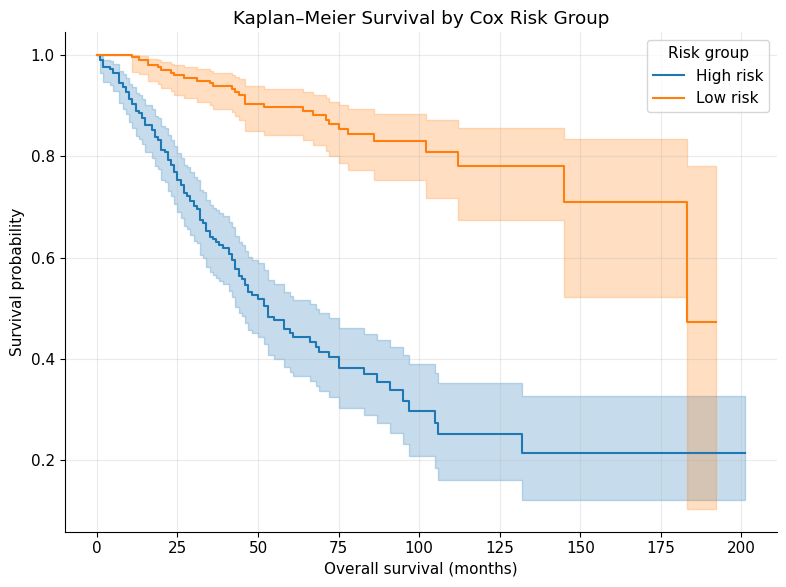


19.9 OUTPUTS

Figure:
/content/poster_outputs/figures/Figure_GSE39582_Kaplan_Meier_Risk_Groups.png

Tables:
/content/poster_outputs/tables/Table_GSE39582_Kaplan_Meier_Summary.csv
/content/poster_outputs/tables/GSE39582_KM_Risk_Group_Data.csv

19.9 COMPLETED SUCCESSFULLY


In [ ]:
# ======================================================================
# 19.9 — KAPLAN–MEIER SURVIVAL ANALYSIS
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

print("=" * 70)
print("19.9 — KAPLAN–MEIER SURVIVAL ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

if "risk_table" not in globals():
    raise RuntimeError(
        "risk_table is not available. "
        "Run Section 19.8 successfully first."
    )

required_columns = [
    "Sample",
    "OS_time_months",
    "OS_event",
    "Risk_Score",
    "Risk_Group"
]

missing_columns = [
    c for c in required_columns
    if c not in risk_table.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing columns in risk_table: {missing_columns}"
    )

print("\n✓ risk_table available")
print("✓ Required survival columns available")

# ----------------------------------------------------------------------
# 2. CLEAN DATA
# ----------------------------------------------------------------------

km_data = risk_table.copy()

km_data["OS_time_months"] = pd.to_numeric(
    km_data["OS_time_months"],
    errors="coerce"
)

km_data["OS_event"] = pd.to_numeric(
    km_data["OS_event"],
    errors="coerce"
)

km_data["Risk_Score"] = pd.to_numeric(
    km_data["Risk_Score"],
    errors="coerce"
)

km_data = km_data.dropna(
    subset=[
        "OS_time_months",
        "OS_event",
        "Risk_Score",
        "Risk_Group"
    ]
).copy()

km_data["OS_event"] = (
    km_data["OS_event"]
    .astype(int)
)

# Remove impossible survival times
km_data = km_data[
    km_data["OS_time_months"] > 0
].copy()

print("\nSamples available for KM analysis:", len(km_data))

# ----------------------------------------------------------------------
# 3. CHECK RISK GROUPS
# ----------------------------------------------------------------------

high = km_data[
    km_data["Risk_Group"] == "High"
].copy()

low = km_data[
    km_data["Risk_Group"] == "Low"
].copy()

if len(high) == 0 or len(low) == 0:
    raise RuntimeError(
        "High or Low risk group is empty."
    )

print("\nRisk-group sizes:")
print(
    km_data["Risk_Group"].value_counts()
)

print("\nEvents by risk group:")
print(
    km_data.groupby("Risk_Group")["OS_event"].agg(
        Samples="count",
        Events="sum"
    )
)

# ----------------------------------------------------------------------
# 4. FIT KAPLAN–MEIER MODELS
# ----------------------------------------------------------------------

kmf_high = KaplanMeierFitter(
    label="High risk"
)

kmf_low = KaplanMeierFitter(
    label="Low risk"
)

kmf_high.fit(
    durations=high["OS_time_months"],
    event_observed=high["OS_event"]
)

kmf_low.fit(
    durations=low["OS_time_months"],
    event_observed=low["OS_event"]
)

print("\n✓ Kaplan–Meier models fitted")

# ----------------------------------------------------------------------
# 5. LOG-RANK TEST
# ----------------------------------------------------------------------

logrank_result = logrank_test(
    high["OS_time_months"],
    low["OS_time_months"],
    event_observed_A=high["OS_event"],
    event_observed_B=low["OS_event"]
)

logrank_p = float(
    logrank_result.p_value
)

test_statistic = float(
    logrank_result.test_statistic
)

print("\n" + "-" * 70)
print("LOG-RANK TEST")
print("-" * 70)

print(
    "Test statistic:",
    round(test_statistic, 6)
)

print(
    "P-value:",
    f"{logrank_p:.6g}"
)

# ----------------------------------------------------------------------
# 6. MEDIAN SURVIVAL
# ----------------------------------------------------------------------

median_high = float(
    kmf_high.median_survival_time_
)

median_low = float(
    kmf_low.median_survival_time_
)

print("\nMedian overall survival:")
print(
    "High risk:",
    median_high
)

print(
    "Low risk:",
    median_low
)

# ----------------------------------------------------------------------
# 7. CREATE KM SUMMARY TABLE
# ----------------------------------------------------------------------

km_summary = pd.DataFrame({
    "Risk_Group": [
        "High",
        "Low"
    ],
    "Samples": [
        len(high),
        len(low)
    ],
    "Events": [
        int(high["OS_event"].sum()),
        int(low["OS_event"].sum())
    ],
    "Event_Rate": [
        high["OS_event"].mean(),
        low["OS_event"].mean()
    ],
    "Median_OS_months": [
        median_high,
        median_low
    ]
})

# Add statistical-test information
km_summary["Logrank_Test_Statistic"] = test_statistic
km_summary["Logrank_P_Value"] = logrank_p

# ----------------------------------------------------------------------
# 8. CREATE FIGURE
# ----------------------------------------------------------------------

FIG_DIR = "/content/poster_outputs/figures"
TABLE_DIR = "/content/poster_outputs/tables"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

plt.figure(figsize=(8, 6))

kmf_high.plot_survival_function(
    ci_show=True
)

kmf_low.plot_survival_function(
    ci_show=True
)

plt.xlabel("Overall survival (months)")
plt.ylabel("Survival probability")
plt.title("Kaplan–Meier Survival by Cox Risk Group")

plt.legend(
    title="Risk group"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

km_figure = os.path.join(
    FIG_DIR,
    "Figure_GSE39582_Kaplan_Meier_Risk_Groups.png"
)

plt.savefig(
    km_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 9. SAVE SUMMARY TABLE
# ----------------------------------------------------------------------

km_table_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Kaplan_Meier_Summary.csv"
)

km_summary.to_csv(
    km_table_file,
    index=False
)

# ----------------------------------------------------------------------
# 10. SAVE KM EVENT DATA
# ----------------------------------------------------------------------

km_data_file = os.path.join(
    TABLE_DIR,
    "GSE39582_KM_Risk_Group_Data.csv"
)

km_data.to_csv(
    km_data_file,
    index=False
)

# ----------------------------------------------------------------------
# 11. FINAL OUTPUT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("19.9 OUTPUTS")
print("=" * 70)

print("\nFigure:")
print(km_figure)

print("\nTables:")
print(km_table_file)
print(km_data_file)

print("\n" + "=" * 70)
print("19.9 COMPLETED SUCCESSFULLY")
print("=" * 70)

19.10 — TIME-DEPENDENT SURVIVAL PERFORMANCE

Samples available: 439

Time horizons: [12, 36, 60] months

----------------------------------------------------------------------
TIME-DEPENDENT AUC RESULTS
----------------------------------------------------------------------


,Time_months,AUC,Eligible_samples,Events_by_time,Survivors_at_time
0,12,0.885700,425,25,400
1,36,0.869463,369,86,283
2,60,0.875563,297,121,176


12 months: AUC = 0.8857
36 months: AUC = 0.8695
60 months: AUC = 0.8756


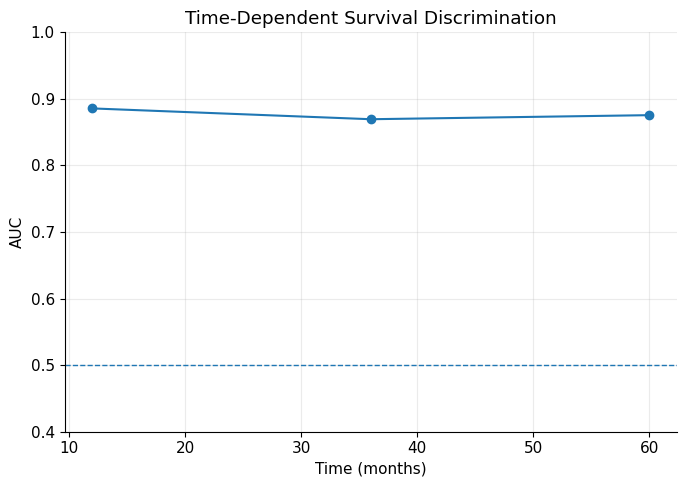


19.10 COMPLETED SUCCESSFULLY

Saved:
/content/poster_outputs/tables/Table_GSE39582_Time_Dependent_AUC.csv
/content/poster_outputs/figures/Figure_GSE39582_Time_Dependent_AUC.png
/content/poster_outputs/tables/Table_GSE39582_Survival_Performance_Summary.csv

Time-dependent AUC:
 Time_months      AUC  Eligible_samples  Events_by_time  Survivors_at_time
          12 0.885700               425              25                400
          36 0.869463               369              86                283
          60 0.875563               297             121                176


In [ ]:
# ======================================================================
# 19.10 — TIME-DEPENDENT SURVIVAL PERFORMANCE
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score

print("=" * 70)
print("19.10 — TIME-DEPENDENT SURVIVAL PERFORMANCE")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ----------------------------------------------------------------------

if "risk_table" not in globals():
    raise RuntimeError(
        "risk_table is not available. Run 19.8 first."
    )

if "km_data" not in globals():
    km_data = risk_table.copy()

# ----------------------------------------------------------------------
# 2. PREPARE DATA
# ----------------------------------------------------------------------

td_data = risk_table.copy()

td_data["OS_time_months"] = pd.to_numeric(
    td_data["OS_time_months"],
    errors="coerce"
)

td_data["OS_event"] = pd.to_numeric(
    td_data["OS_event"],
    errors="coerce"
)

td_data["Risk_Score"] = pd.to_numeric(
    td_data["Risk_Score"],
    errors="coerce"
)

td_data = td_data.dropna(
    subset=[
        "OS_time_months",
        "OS_event",
        "Risk_Score"
    ]
).copy()

td_data["OS_event"] = (
    td_data["OS_event"].astype(int)
)

print(
    "\nSamples available:",
    len(td_data)
)

# ----------------------------------------------------------------------
# 3. DEFINE TIME HORIZONS
# ----------------------------------------------------------------------

time_points = [
    12,
    36,
    60
]

print(
    "\nTime horizons:",
    time_points,
    "months"
)

# ----------------------------------------------------------------------
# 4. TIME-DEPENDENT AUC
# ----------------------------------------------------------------------

auc_results = []

for t in time_points:

    # --------------------------------------------------------------
    # Landmark-style binary outcome
    #
    # Event by time t:
    #   1 = death occurred by t
    #
    # Survived beyond t:
    #   0 = known to survive beyond t
    #
    # Individuals censored before t are excluded because their
    # status at t is unknown.
    # --------------------------------------------------------------

    eligible = (
        (td_data["OS_time_months"] >= t)
        |
        (
            (td_data["OS_event"] == 1)
            &
            (td_data["OS_time_months"] <= t)
        )
    )

    d = td_data.loc[
        eligible
    ].copy()

    d["Event_by_time"] = (
        (
            (d["OS_event"] == 1)
            &
            (d["OS_time_months"] <= t)
        )
        .astype(int)
    )

    n_events = int(
        d["Event_by_time"].sum()
    )

    n_survivors = int(
        (d["Event_by_time"] == 0).sum()
    )

    # Need both classes
    if (
        d["Event_by_time"].nunique() < 2
    ):

        auc = np.nan

    else:

        auc = roc_auc_score(
            d["Event_by_time"],
            d["Risk_Score"]
        )

    auc_results.append({
        "Time_months": t,
        "AUC": auc,
        "Eligible_samples": len(d),
        "Events_by_time": n_events,
        "Survivors_at_time": n_survivors
    })

auc_df = pd.DataFrame(
    auc_results
)

# ----------------------------------------------------------------------
# 5. DISPLAY RESULTS
# ----------------------------------------------------------------------

print("\n" + "-" * 70)
print("TIME-DEPENDENT AUC RESULTS")
print("-" * 70)

display(
    auc_df
)

for _, row in auc_df.iterrows():

    if pd.notna(row["AUC"]):

        print(
            f"{int(row['Time_months'])} months: "
            f"AUC = {row['AUC']:.4f}"
        )

    else:

        print(
            f"{int(row['Time_months'])} months: "
            f"AUC unavailable"
        )

# ----------------------------------------------------------------------
# 6. SAVE AUC TABLE
# ----------------------------------------------------------------------

TABLE_DIR = (
    "/content/poster_outputs/tables"
)

FIG_DIR = (
    "/content/poster_outputs/figures"
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

auc_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Time_Dependent_AUC.csv"
)

auc_df.to_csv(
    auc_file,
    index=False
)

# ----------------------------------------------------------------------
# 7. CREATE AUC FIGURE
# ----------------------------------------------------------------------

plot_df = auc_df.dropna(
    subset=["AUC"]
)

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    plot_df["Time_months"],
    plot_df["AUC"],
    marker="o"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Time (months)"
)

plt.ylabel(
    "AUC"
)

plt.title(
    "Time-Dependent Survival Discrimination"
)

plt.ylim(
    0.4,
    1.0
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

auc_figure = os.path.join(
    FIG_DIR,
    "Figure_GSE39582_Time_Dependent_AUC.png"
)

plt.savefig(
    auc_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 8. SAVE PERFORMANCE SUMMARY
# ----------------------------------------------------------------------

performance_summary = pd.DataFrame({
    "Metric": [
        "Discovery samples",
        "Overall Cox C-index",
        "12-month AUC",
        "36-month AUC",
        "60-month AUC"
    ],
    "Value": [
        len(td_data),
        (
            final_cox.concordance_index_
            if "final_cox" in globals()
            else np.nan
        ),
        (
            auc_df.loc[
                auc_df["Time_months"] == 12,
                "AUC"
            ].iloc[0]
            if 12 in auc_df["Time_months"].values
            else np.nan
        ),
        (
            auc_df.loc[
                auc_df["Time_months"] == 36,
                "AUC"
            ].iloc[0]
            if 36 in auc_df["Time_months"].values
            else np.nan
        ),
        (
            auc_df.loc[
                auc_df["Time_months"] == 60,
                "AUC"
            ].iloc[0]
            if 60 in auc_df["Time_months"].values
            else np.nan
        )
    ]
})

performance_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Survival_Performance_Summary.csv"
)

performance_summary.to_csv(
    performance_file,
    index=False
)

# ----------------------------------------------------------------------
# 9. FINAL OUTPUT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("19.10 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nSaved:")
print(auc_file)
print(auc_figure)
print(performance_file)

print("\nTime-dependent AUC:")
print(
    auc_df.to_string(index=False)
)

19.11 — FINAL TABLES / FIGURES
✓ Final LASSO table saved
✓ Final Cox table saved
✓ Risk-group summary saved
✓ KM summary saved
✓ Time-dependent AUC table saved


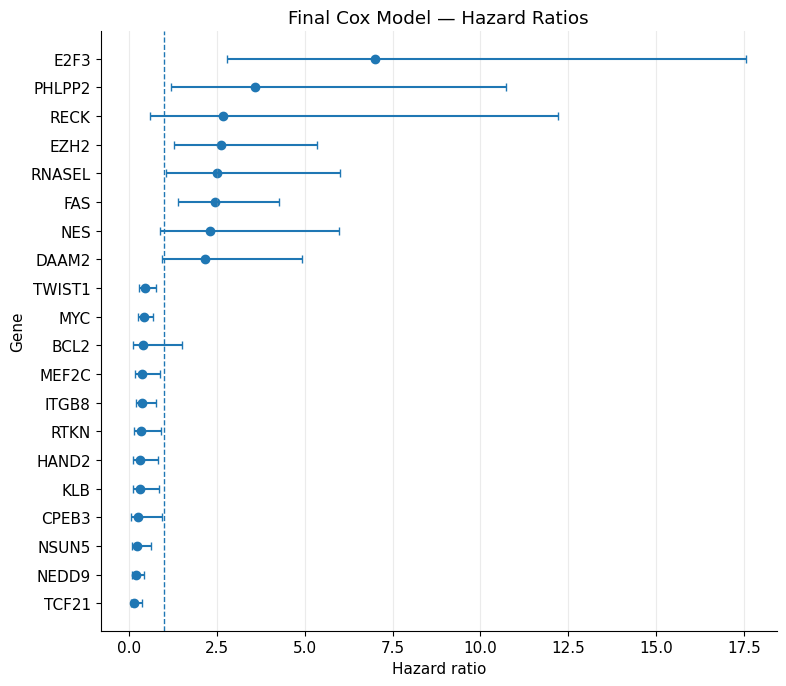

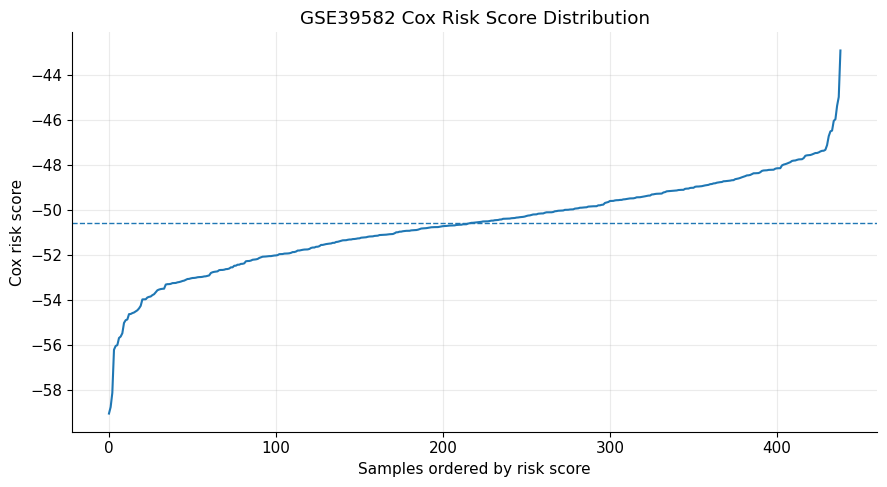


19.11 COMPLETED SUCCESSFULLY

FINAL TABLES:
/content/poster_outputs/tables/Table_GSE39582_Final_LASSO_Selected_Genes.csv
/content/poster_outputs/tables/Table_GSE39582_Final_Cox_Hazard_Ratios.csv
/content/poster_outputs/tables/Table_GSE39582_Final_Risk_Group_Summary.csv
/content/poster_outputs/tables/Table_GSE39582_Final_KM_Summary.csv
/content/poster_outputs/tables/Table_GSE39582_Final_Time_Dependent_AUC.csv
/content/poster_outputs/tables/Table_GSE39582_Section19_Final_Summary.csv

FINAL FIGURES:
/content/poster_outputs/figures/Figure_GSE39582_Kaplan_Meier_Risk_Groups.png
/content/poster_outputs/figures/Figure_GSE39582_Time_Dependent_AUC.png
/content/poster_outputs/figures/Figure_GSE39582_Final_Cox_Hazard_Ratios.png
/content/poster_outputs/figures/Figure_GSE39582_Final_Risk_Score_Distribution.png


In [ ]:
# ======================================================================
# 19.11 — FINAL TABLES / FIGURES
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("19.11 — FINAL TABLES / FIGURES")
print("=" * 70)

TABLE_DIR = "/content/poster_outputs/tables"
FIG_DIR = "/content/poster_outputs/figures"

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# 1. FINAL LASSO GENE TABLE
# ----------------------------------------------------------------------

if "lasso_coefficients" in globals():

    final_lasso_table = (
        lasso_coefficients
        .copy()
        .reset_index()
    )

    if "index" in final_lasso_table.columns:
        final_lasso_table = final_lasso_table.rename(
            columns={"index": "Gene"}
        )

else:

    raise RuntimeError(
        "lasso_coefficients not found. Run 19.6 first."
    )

lasso_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Final_LASSO_Selected_Genes.csv"
)

final_lasso_table.to_csv(
    lasso_file,
    index=False
)

print("✓ Final LASSO table saved")

# ----------------------------------------------------------------------
# 2. FINAL COX TABLE
# ----------------------------------------------------------------------

if "cox_summary" not in globals():

    raise RuntimeError(
        "cox_summary not found. Run 19.7 first."
    )

final_cox_table = (
    cox_summary
    .copy()
    .reset_index()
)

if "index" in final_cox_table.columns:

    final_cox_table = final_cox_table.rename(
        columns={"index": "Gene"}
    )

cox_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Final_Cox_Hazard_Ratios.csv"
)

final_cox_table.to_csv(
    cox_file,
    index=False
)

print("✓ Final Cox table saved")

# ----------------------------------------------------------------------
# 3. RISK-GROUP SUMMARY
# ----------------------------------------------------------------------

if "risk_table" not in globals():

    raise RuntimeError(
        "risk_table not found. Run 19.8 first."
    )

risk_group_summary = (
    risk_table
    .groupby("Risk_Group")
    .agg(
        Samples=("Sample", "count"),
        Events=("OS_event", "sum"),
        Median_Risk_Score=("Risk_Score", "median"),
        Mean_Risk_Score=("Risk_Score", "mean"),
        Median_OS_months=("OS_time_months", "median")
    )
    .reset_index()
)

risk_group_summary["Event_Rate"] = (
    risk_group_summary["Events"]
    / risk_group_summary["Samples"]
)

risk_group_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Final_Risk_Group_Summary.csv"
)

risk_group_summary.to_csv(
    risk_group_file,
    index=False
)

print("✓ Risk-group summary saved")

# ----------------------------------------------------------------------
# 4. KM SUMMARY
# ----------------------------------------------------------------------

if "km_summary" in globals():

    final_km_summary = km_summary.copy()

else:

    final_km_summary = risk_group_summary.copy()

km_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Final_KM_Summary.csv"
)

final_km_summary.to_csv(
    km_file,
    index=False
)

print("✓ KM summary saved")

# ----------------------------------------------------------------------
# 5. TIME-DEPENDENT PERFORMANCE
# ----------------------------------------------------------------------

if "auc_df" not in globals():

    raise RuntimeError(
        "auc_df not found. Run 19.10 first."
    )

final_auc = auc_df.copy()

auc_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Final_Time_Dependent_AUC.csv"
)

final_auc.to_csv(
    auc_file,
    index=False
)

print("✓ Time-dependent AUC table saved")

# ----------------------------------------------------------------------
# 6. OVERALL SECTION-19 SUMMARY
# ----------------------------------------------------------------------

optimal_penalty = np.nan
cv_cindex = np.nan

if "best_penalty" in globals():
    optimal_penalty = best_penalty

if "best_cv_cindex" in globals():
    cv_cindex = best_cv_cindex

final_model_cindex = np.nan

if "final_cox" in globals():
    final_model_cindex = (
        final_cox.concordance_index_
    )

n_selected = len(
    selected_genes
) if "selected_genes" in globals() else np.nan

n_events = int(
    risk_table["OS_event"].sum()
)

summary_table = pd.DataFrame({
    "Metric": [
        "Discovery samples",
        "Discovery events",
        "Candidate genes",
        "LASSO-selected genes",
        "Optimal LASSO penalty",
        "Mean CV C-index",
        "Final Cox C-index",
        "Final Cox model type"
    ],
    "Value": [
        len(risk_table),
        n_events,
        127,
        n_selected,
        optimal_penalty,
        cv_cindex,
        final_model_cindex,
        (
            model_type
            if "model_type" in globals()
            else "Unpenalized Cox"
        )
    ]
})

summary_file = os.path.join(
    TABLE_DIR,
    "Table_GSE39582_Section19_Final_Summary.csv"
)

summary_table.to_csv(
    summary_file,
    index=False
)

# ----------------------------------------------------------------------
# 7. FINAL COX FOREST-STYLE PLOT
# ----------------------------------------------------------------------

plot_cox = cox_summary.copy()

if "Hazard_Ratio" in plot_cox.columns:

    plot_cox = (
        plot_cox
        .sort_values(
            "Hazard_Ratio"
        )
    )

    # Limit visualization to the 20 strongest
    # absolute coefficients for readability.
    if len(plot_cox) > 20:

        plot_cox = (
            plot_cox
            .sort_values(
                "Absolute_Coefficient",
                ascending=False
            )
            .head(20)
            .sort_values(
                "Hazard_Ratio"
            )
        )

    genes_plot = plot_cox.index.astype(str)

    hr = plot_cox["Hazard_Ratio"].values

    lower = (
        plot_cox["HR_Lower_95"].values
        if "HR_Lower_95" in plot_cox.columns
        else None
    )

    upper = (
        plot_cox["HR_Upper_95"].values
        if "HR_Upper_95" in plot_cox.columns
        else None
    )

    plt.figure(
        figsize=(8, max(6, len(plot_cox) * 0.35))
    )

    y = np.arange(len(plot_cox))

    plt.scatter(
        hr,
        y
    )

    if lower is not None and upper is not None:

        xerr = np.vstack([
            hr - lower,
            upper - hr
        ])

        plt.errorbar(
            hr,
            y,
            xerr=xerr,
            fmt="none",
            capsize=3
        )

    plt.axvline(
        1.0,
        linestyle="--",
        linewidth=1
    )

    plt.yticks(
        y,
        genes_plot
    )

    plt.xlabel(
        "Hazard ratio"
    )

    plt.ylabel(
        "Gene"
    )

    plt.title(
        "Final Cox Model — Hazard Ratios"
    )

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()

    forest_file = os.path.join(
        FIG_DIR,
        "Figure_GSE39582_Final_Cox_Hazard_Ratios.png"
    )

    plt.savefig(
        forest_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print(
        "⚠ Cox forest plot skipped because "
        "Hazard_Ratio is unavailable."
    )

# ----------------------------------------------------------------------
# 8. FINAL RISK-SCORE DISTRIBUTION
# ----------------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

sorted_risk = (
    risk_table
    .sort_values("Risk_Score")
    .reset_index(drop=True)
)

x = np.arange(
    len(sorted_risk)
)

plt.plot(
    x,
    sorted_risk["Risk_Score"]
)

plt.axhline(
    risk_table["Risk_Score"].median(),
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Samples ordered by risk score"
)

plt.ylabel(
    "Cox risk score"
)

plt.title(
    "GSE39582 Cox Risk Score Distribution"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

risk_figure = os.path.join(
    FIG_DIR,
    "Figure_GSE39582_Final_Risk_Score_Distribution.png"
)

plt.savefig(
    risk_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------------------
# 9. FINAL OUTPUT LIST
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("19.11 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nFINAL TABLES:")
print(lasso_file)
print(cox_file)
print(risk_group_file)
print(km_file)
print(auc_file)
print(summary_file)

print("\nFINAL FIGURES:")
print(
    os.path.join(
        FIG_DIR,
        "Figure_GSE39582_Kaplan_Meier_Risk_Groups.png"
    )
)
print(
    os.path.join(
        FIG_DIR,
        "Figure_GSE39582_Time_Dependent_AUC.png"
    )
)
print(
    os.path.join(
        FIG_DIR,
        "Figure_GSE39582_Final_Cox_Hazard_Ratios.png"
    )
)
print(risk_figure)

In [ ]:
# ======================================================================
# 19.12 — SECTION 19 ZIP DOWNLOAD
# ======================================================================

import os
import shutil
from google.colab import files

print("=" * 70)
print("19.12 — CREATING SECTION 19 ZIP")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. SOURCE DIRECTORIES
# ----------------------------------------------------------------------

BASE_DIR = "/content/poster_outputs"

FIG_DIR = os.path.join(
    BASE_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    BASE_DIR,
    "tables"
)

# ----------------------------------------------------------------------
# 2. CREATE SECTION 19 FOLDER
# ----------------------------------------------------------------------

SECTION_DIR = "/content/Section_19_LASSO_Cox"

if os.path.exists(SECTION_DIR):
    shutil.rmtree(SECTION_DIR)

os.makedirs(
    os.path.join(SECTION_DIR, "figures"),
    exist_ok=True
)

os.makedirs(
    os.path.join(SECTION_DIR, "tables"),
    exist_ok=True
)

# ----------------------------------------------------------------------
# 3. COPY SECTION 19 FIGURES
# ----------------------------------------------------------------------

section19_figure_keywords = [
    "GSE39582_Kaplan",
    "GSE39582_Time_Dependent_AUC",
    "GSE39582_Final_Cox",
    "GSE39582_Final_Risk"
]

figure_count = 0

if os.path.exists(FIG_DIR):

    for filename in os.listdir(FIG_DIR):

        source = os.path.join(
            FIG_DIR,
            filename
        )

        if not os.path.isfile(source):
            continue

        if any(
            keyword in filename
            for keyword in section19_figure_keywords
        ):

            destination = os.path.join(
                SECTION_DIR,
                "figures",
                filename
            )

            shutil.copy2(
                source,
                destination
            )

            figure_count += 1

# ----------------------------------------------------------------------
# 4. COPY SECTION 19 TABLES
# ----------------------------------------------------------------------

section19_table_keywords = [
    "GSE39582",
    "Table_GSE39582"
]

table_count = 0

if os.path.exists(TABLE_DIR):

    for filename in os.listdir(TABLE_DIR):

        source = os.path.join(
            TABLE_DIR,
            filename
        )

        if not os.path.isfile(source):
            continue

        if any(
            keyword in filename
            for keyword in section19_table_keywords
        ):

            destination = os.path.join(
                SECTION_DIR,
                "tables",
                filename
            )

            shutil.copy2(
                source,
                destination
            )

            table_count += 1

# ----------------------------------------------------------------------
# 5. CREATE ZIP
# ----------------------------------------------------------------------

ZIP_BASE = "/content/Section_19_LASSO_Cox"

ZIP_FILE = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/content",
    base_dir="Section_19_LASSO_Cox"
)

# ----------------------------------------------------------------------
# 6. CHECK CONTENTS
# ----------------------------------------------------------------------

print("\nFigures included:", figure_count)
print("Tables included:", table_count)

print("\nZIP created:")
print(ZIP_FILE)

print(
    "\nZIP size:",
    round(
        os.path.getsize(ZIP_FILE) / (1024 ** 2),
        2
    ),
    "MB"
)

print("\n" + "=" * 70)
print("19.12 COMPLETED SUCCESSFULLY")
print("=" * 70)

# ----------------------------------------------------------------------
# 7. DOWNLOAD TO YOUR COMPUTER
# ----------------------------------------------------------------------

files.download(
    ZIP_FILE
)

19.12 — CREATING SECTION 19 ZIP

Figures included: 4
Tables included: 27

ZIP created:
/content/Section_19_LASSO_Cox.zip

ZIP size: 159.79 MB

19.12 COMPLETED SUCCESSFULLY


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ======================================================================
# SECTION 13 — ZIP DOWNLOAD
# ======================================================================

import os
import shutil
from google.colab import files

print("=" * 70)
print("SECTION 13 — CREATING ZIP")
print("=" * 70)

BASE_DIR = "/content/poster_outputs"

FIG_DIR = os.path.join(BASE_DIR, "figures")
TABLE_DIR = os.path.join(BASE_DIR, "tables")

SECTION_DIR = "/content/Section_13_Outputs"

# Remove previous copy if it exists
if os.path.exists(SECTION_DIR):
    shutil.rmtree(SECTION_DIR)

# Create folders
os.makedirs(
    os.path.join(SECTION_DIR, "figures"),
    exist_ok=True
)

os.makedirs(
    os.path.join(SECTION_DIR, "tables"),
    exist_ok=True
)

# ----------------------------------------------------------------------
# COPY FIGURES
# ----------------------------------------------------------------------

figure_count = 0

if os.path.exists(FIG_DIR):

    for filename in os.listdir(FIG_DIR):

        source = os.path.join(FIG_DIR, filename)

        if not os.path.isfile(source):
            continue

        destination = os.path.join(
            SECTION_DIR,
            "figures",
            filename
        )

        shutil.copy2(source, destination)
        figure_count += 1

# ----------------------------------------------------------------------
# COPY TABLES
# ----------------------------------------------------------------------

table_count = 0

if os.path.exists(TABLE_DIR):

    for filename in os.listdir(TABLE_DIR):

        source = os.path.join(TABLE_DIR, filename)

        if not os.path.isfile(source):
            continue

        destination = os.path.join(
            SECTION_DIR,
            "tables",
            filename
        )

        shutil.copy2(source, destination)
        table_count += 1

# ----------------------------------------------------------------------
# CREATE ZIP
# ----------------------------------------------------------------------

ZIP_FILE = shutil.make_archive(
    "/content/Section_13_Outputs",
    "zip",
    root_dir="/content",
    base_dir="Section_13_Outputs"
)

print("\nFigures included:", figure_count)
print("Tables included:", table_count)

print("\nZIP created:")
print(ZIP_FILE)

print(
    "\nZIP size:",
    round(
        os.path.getsize(ZIP_FILE) / (1024 ** 2),
        2
    ),
    "MB"
)

print("\n" + "=" * 70)
print("SECTION 13 ZIP CREATED")
print("=" * 70)

# Download automatically
files.download(ZIP_FILE)

SECTION 13 — CREATING ZIP

Figures included: 8
Tables included: 34

ZIP created:
/content/Section_13_Outputs.zip

ZIP size: 160.27 MB

SECTION 13 ZIP CREATED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>